# Αναγνώριση Ελληνικών Παραδοσιακών Φορεσιών με Deep Learning

## Πειραματική Αξιολόγηση Μοντέλων Μεταφοράς Μάθησης (Transfer Learning)

Το παρόν notebook παρουσιάζει την πειραματική διαδικασία που ακολουθήθηκε για την ανάπτυξη και αξιολόγηση μοντέλων βαθιάς μάθησης με σκοπό την αναγνώριση της γεωγραφικής προέλευσης ελληνικών παραδοσιακών φορεσιών από εικόνες.

Αρχικά πραγματοποιείται η προετοιμασία των δεδομένων και ο ορισμός των κοινών υπερπαραμέτρων. Στη συνέχεια παρουσιάζονται διαδοχικά τα πειράματα που υλοποιήθηκαν με διαφορετικές στρατηγικές μεταφοράς μάθησης (Transfer Learning), καθώς και η αξιολόγηση της απόδοσής τους με τη χρήση κατάλληλων μετρικών ταξινόμησης.

Στόχος είναι η σύγκριση των διαφορετικών προσεγγίσεων και η επιλογή του μοντέλου που επιτυγχάνει τη βέλτιστη απόδοση στο πρόβλημα της αναγνώρισης ελληνικών παραδοσιακών φορεσιών.


#Ενότητα 1 - Ρυθμίσεις Πειράματος (Setup)

Στην ενότητα αυτή πραγματοποιείται η αρχική προετοιμασία του περιβάλλοντος εκτέλεσης. Αρχικά εισάγονται οι απαραίτητες βιβλιοθήκες, ορίζονται οι βασικές διαδρομές του έργου και πραγματοποιείται η σύνδεση με το Google Drive, όπου είναι αποθηκευμένο το σύνολο δεδομένων και τα αποτελέσματα των πειραμάτων.

Επιπλέον, ελέγχεται η διαθεσιμότητα επιτάχυνσης μέσω GPU, ώστε η εκπαίδευση των μοντέλων να πραγματοποιείται με τον αποδοτικότερο δυνατό τρόπο.

In [1]:
# =============================================================================
# ΕΝΟΤΗΤΑ 1 — ΡΥΘΜΙΣΕΙΣ ΠΕΡΙΒΑΛΛΟΝΤΟΣ
# =============================================================================

import os
import random
from pathlib import Path

import numpy as np
import torch

from google.colab import drive


# -----------------------------------------------------------------------------
# 1.1 Έλεγχος περιβάλλοντος εκτέλεσης
# -----------------------------------------------------------------------------

print("=" * 70)
print("ΕΛΕΓΧΟΣ ΠΕΡΙΒΑΛΛΟΝΤΟΣ ΕΚΤΕΛΕΣΗΣ")
print("=" * 70)

print(f"PyTorch version : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU             : {torch.cuda.get_device_name(0)}")
else:
    print("GPU             : Δεν είναι διαθέσιμη")


# -----------------------------------------------------------------------------
# 1.2 Σύνδεση με το Google Drive
# -----------------------------------------------------------------------------

drive.mount("/content/drive")


# -----------------------------------------------------------------------------
# 1.3 Έλεγχος περιεχομένων του Google Drive
# -----------------------------------------------------------------------------

MY_DRIVE_DIR = Path("/content/drive/MyDrive")

if not MY_DRIVE_DIR.exists():
    raise FileNotFoundError(
        "Δεν βρέθηκε ο φάκελος /content/drive/MyDrive."
    )

print("\n" + "=" * 70)
print("ΠΕΡΙΕΧΟΜΕΝΑ ΤΟΥ GOOGLE DRIVE")
print("=" * 70)

for item in sorted(MY_DRIVE_DIR.iterdir()):
    print(item.name)


# -----------------------------------------------------------------------------
# 1.4 Βασικές διαδρομές του project
# -----------------------------------------------------------------------------

PROJECT_DIR = MY_DRIVE_DIR / "ptyxiaki"

DATASET_SPLIT_DIR = PROJECT_DIR / "dataset_split"

TRAIN_DIR = DATASET_SPLIT_DIR / "train"
VALIDATION_DIR = DATASET_SPLIT_DIR / "validation"
TEST_DIR = DATASET_SPLIT_DIR / "test"

REPORTS_DIR = PROJECT_DIR / "reports"
SCRIPTS_DIR = PROJECT_DIR / "scripts"


# -----------------------------------------------------------------------------
# 1.5 Σταθεροί κεντρικοί φάκελοι αποθήκευσης
# -----------------------------------------------------------------------------
# Οι μεταβλητές αυτές αποτελούν τις μόνιμες ρίζες αποθήκευσης.
# Δεν πρέπει να επαναπροσδιορίζονται μέσα στα επιμέρους πειράματα.

MODELS_DIR = PROJECT_DIR / "models"

CHECKPOINTS_ROOT_DIR = (
    MODELS_DIR / "checkpoints"
)

TRAINED_MODELS_ROOT_DIR = (
    MODELS_DIR / "trained"
)

RESULTS_ROOT_DIR = (
    PROJECT_DIR / "results"
)


# -----------------------------------------------------------------------------
# 1.6 Έλεγχος ύπαρξης του βασικού φακέλου του project
# -----------------------------------------------------------------------------

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        f"Δεν βρέθηκε ο βασικός φάκελος του project:\n{PROJECT_DIR}"
    )


# -----------------------------------------------------------------------------
# 1.7 Εμφάνιση περιεχομένων του project
# -----------------------------------------------------------------------------

print("\n" + "=" * 70)
print("ΠΕΡΙΕΧΟΜΕΝΑ ΤΟΥ PROJECT")
print("=" * 70)

for item in sorted(PROJECT_DIR.iterdir()):
    print(item.name)


# -----------------------------------------------------------------------------
# 1.8 Δημιουργία των απαραίτητων γενικών φακέλων
# -----------------------------------------------------------------------------
# Οι φάκελοι του dataset δεν δημιουργούνται αυτόματα, επειδή πρέπει να
# περιέχουν ήδη τα δεδομένα train, validation και test.

directories_to_create = [
    REPORTS_DIR,
    MODELS_DIR,
    CHECKPOINTS_ROOT_DIR,
    TRAINED_MODELS_ROOT_DIR,
    RESULTS_ROOT_DIR,
    SCRIPTS_DIR,
]

for directory in directories_to_create:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# -----------------------------------------------------------------------------
# 1.9 Έλεγχος βασικών φακέλων του project
# -----------------------------------------------------------------------------

project_directories = {
    "dataset_split": DATASET_SPLIT_DIR,
    "reports": REPORTS_DIR,
    "models": MODELS_DIR,
    "checkpoints": CHECKPOINTS_ROOT_DIR,
    "trained": TRAINED_MODELS_ROOT_DIR,
    "results": RESULTS_ROOT_DIR,
    "scripts": SCRIPTS_DIR,
}

print("\n" + "=" * 70)
print("ΕΛΕΓΧΟΣ ΒΑΣΙΚΩΝ ΦΑΚΕΛΩΝ")
print("=" * 70)

for directory_name, directory_path in project_directories.items():
    print(
        f"{directory_name:<15}: "
        f"{directory_path.exists()}"
    )


# -----------------------------------------------------------------------------
# 1.10 Έλεγχος ύπαρξης των dataset subsets
# -----------------------------------------------------------------------------

required_dataset_directories = {
    "train": TRAIN_DIR,
    "validation": VALIDATION_DIR,
    "test": TEST_DIR,
}

missing_dataset_directories = [
    str(directory_path)
    for directory_path in required_dataset_directories.values()
    if not directory_path.exists()
]

if missing_dataset_directories:
    raise FileNotFoundError(
        "Δεν βρέθηκαν οι παρακάτω φάκελοι του dataset:\n"
        + "\n".join(missing_dataset_directories)
    )


# -----------------------------------------------------------------------------
# 1.11 Αναπαραγωγιμότητα πειραμάτων
# -----------------------------------------------------------------------------

RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(RANDOM_SEED)
    torch.cuda.manual_seed_all(RANDOM_SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# -----------------------------------------------------------------------------
# 1.12 Επιλογή συσκευής εκτέλεσης
# -----------------------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# -----------------------------------------------------------------------------
# 1.13 Τελική σύνοψη ρυθμίσεων
# -----------------------------------------------------------------------------

print("\n" + "=" * 70)
print("ΣΥΝΟΨΗ ΡΥΘΜΙΣΕΩΝ ΠΕΡΙΒΑΛΛΟΝΤΟΣ")
print("=" * 70)

print(f"Project directory       : {PROJECT_DIR}")
print(f"Dataset split directory : {DATASET_SPLIT_DIR}")

print("\nDataset subsets:")
print(f"Train directory         : {TRAIN_DIR}")
print(f"Validation directory    : {VALIDATION_DIR}")
print(f"Test directory          : {TEST_DIR}")

print("\nGeneral output folders:")
print(f"Reports                 : {REPORTS_DIR}")
print(f"Checkpoints root        : {CHECKPOINTS_ROOT_DIR}")
print(f"Trained models root     : {TRAINED_MODELS_ROOT_DIR}")
print(f"Results root            : {RESULTS_ROOT_DIR}")
print(f"Scripts                 : {SCRIPTS_DIR}")

print("\nReproducibility:")
print(f"Random seed             : {RANDOM_SEED}")

print("\nHardware:")
print(f"Selected device         : {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU                     : {torch.cuda.get_device_name(0)}")
else:
    print("GPU                     : Δεν είναι διαθέσιμη")

print("\n" + "=" * 70)
print("Η Ενότητα 1 ολοκληρώθηκε επιτυχώς.")
print("=" * 70)

ΕΛΕΓΧΟΣ ΠΕΡΙΒΑΛΛΟΝΤΟΣ ΕΚΤΕΛΕΣΗΣ
PyTorch version : 2.11.0+cu128
CUDA available  : True
GPU             : Tesla T4
Mounted at /content/drive

ΠΕΡΙΕΧΟΜΕΝΑ ΤΟΥ GOOGLE DRIVE
Colab Notebooks
ptyxiaki
ptyxiaki (1)

ΠΕΡΙΕΧΟΜΕΝΑ ΤΟΥ PROJECT
.venv
__pycache__
analyze_dataset.py
app.py
dataset
dataset_split
model.py
models
predict.py
reports
requirements.txt
results
scripts
split_dataset.py
static
templates

ΕΛΕΓΧΟΣ ΒΑΣΙΚΩΝ ΦΑΚΕΛΩΝ
dataset_split  : True
reports        : True
models         : True
checkpoints    : True
trained        : True
results        : True
scripts        : True

ΣΥΝΟΨΗ ΡΥΘΜΙΣΕΩΝ ΠΕΡΙΒΑΛΛΟΝΤΟΣ
Project directory       : /content/drive/MyDrive/ptyxiaki
Dataset split directory : /content/drive/MyDrive/ptyxiaki/dataset_split

Dataset subsets:
Train directory         : /content/drive/MyDrive/ptyxiaki/dataset_split/train
Validation directory    : /content/drive/MyDrive/ptyxiaki/dataset_split/validation
Test directory          : /content/drive/MyDrive/ptyxiaki/dataset_split/test

Ge

# Ενότητα 2 - Κοινές υπερπαράμετροι

Στην ενότητα αυτή ορίζονται οι βασικές υπερπαράμετροι που θα χρησιμοποιηθούν κοινά σε όλα τα πειράματα. Η χρήση κοινών ρυθμίσεων για το μέγεθος των εικόνων, το μέγεθος των batches και το μέγιστο πλήθος εποχών επιτρέπει τη συνεπή και δίκαιη σύγκριση των διαφορετικών αρχιτεκτονικών και στρατηγικών μεταφοράς μάθησης.

Οι υπερπαράμετροι που αφορούν αποκλειστικά ένα συγκεκριμένο πείραμα, όπως η ονομασία του μοντέλου ή διαφορετικοί ρυθμοί μάθησης για Fine-Tuning, θα ορίζονται ξεχωριστά μέσα στην αντίστοιχη πειραματική ενότητα.

In [2]:
# =============================================================================
# ΕΝΟΤΗΤΑ 2 — ΚΟΙΝΕΣ ΥΠΕΡΠΑΡΑΜΕΤΡΟΙ
# =============================================================================


# -----------------------------------------------------------------------------
# 2.1 Παράμετροι εισόδου εικόνων
# -----------------------------------------------------------------------------
# Τα προεκπαιδευμένα μοντέλα ResNet18 και EfficientNet-B0 χρησιμοποιούν
# συνήθως εικόνες εισόδου μεγέθους 224 x 224 pixels.

IMAGE_SIZE = 224


# -----------------------------------------------------------------------------
# 2.2 Παράμετροι DataLoader
# -----------------------------------------------------------------------------

BATCH_SIZE = 16
NUM_WORKERS = 2


# -----------------------------------------------------------------------------
# 2.3 Παράμετροι εκπαίδευσης
# -----------------------------------------------------------------------------

MAX_EPOCHS = 25
EARLY_STOPPING_PATIENCE = 5


# -----------------------------------------------------------------------------
# 2.4 Προεπιλεγμένες παράμετροι βελτιστοποίησης
# -----------------------------------------------------------------------------
# Οι τιμές αυτές θα χρησιμοποιηθούν αρχικά στα πειράματα Feature Extraction.
# Σε πειράματα Fine-Tuning μπορεί να οριστεί μικρότερο learning rate μέσα
# στην αντίστοιχη πειραματική ενότητα.

DEFAULT_LEARNING_RATE = 1e-3
DEFAULT_WEIGHT_DECAY = 1e-4


# -----------------------------------------------------------------------------
# 2.5 Αναμενόμενα χαρακτηριστικά του dataset
# -----------------------------------------------------------------------------
# Οι τιμές αυτές χρησιμοποιούνται για έλεγχο ότι φορτώθηκε το σωστό dataset.

EXPECTED_TOTAL_IMAGES = 411
EXPECTED_NUM_CLASSES = 9


# -----------------------------------------------------------------------------
# 2.6 Εμφάνιση των κοινών υπερπαραμέτρων
# -----------------------------------------------------------------------------

print("=" * 70)
print("ΚΟΙΝΕΣ ΥΠΕΡΠΑΡΑΜΕΤΡΟΙ")
print("=" * 70)

print("\nImage settings:")
print(f"Image size              : {IMAGE_SIZE} x {IMAGE_SIZE}")

print("\nDataLoader settings:")
print(f"Batch size              : {BATCH_SIZE}")
print(f"Number of workers       : {NUM_WORKERS}")

print("\nTraining settings:")
print(f"Maximum epochs          : {MAX_EPOCHS}")
print(f"Early stopping patience : {EARLY_STOPPING_PATIENCE}")

print("\nDefault optimization settings:")
print(f"Learning rate           : {DEFAULT_LEARNING_RATE}")
print(f"Weight decay            : {DEFAULT_WEIGHT_DECAY}")

print("\nExpected dataset:")
print(f"Total images            : {EXPECTED_TOTAL_IMAGES}")
print(f"Number of classes       : {EXPECTED_NUM_CLASSES}")

print("\n" + "=" * 70)
print("Η Ενότητα 2 ολοκληρώθηκε επιτυχώς.")
print("=" * 70)

ΚΟΙΝΕΣ ΥΠΕΡΠΑΡΑΜΕΤΡΟΙ

Image settings:
Image size              : 224 x 224

DataLoader settings:
Batch size              : 16
Number of workers       : 2

Training settings:
Maximum epochs          : 25
Early stopping patience : 5

Default optimization settings:
Learning rate           : 0.001
Weight decay            : 0.0001

Expected dataset:
Total images            : 411
Number of classes       : 9

Η Ενότητα 2 ολοκληρώθηκε επιτυχώς.


# Ενότητα 3 - Μετασχηματισμοί εικόνων

Στην ενότητα αυτή ορίζονται οι μετασχηματισμοί που εφαρμόζονται στις εικόνες πριν από την εισαγωγή τους στα μοντέλα βαθιάς μάθησης.

Στο σύνολο εκπαίδευσης εφαρμόζονται ήπιες τεχνικές επαύξησης δεδομένων, όπως μικρή περιστροφή, μετατόπιση, αλλαγή κλίμακας και περιορισμένη μεταβολή φωτεινότητας και αντίθεσης. Οι μετασχηματισμοί αυτοί αυξάνουν την ποικιλία των διαθέσιμων παραδειγμάτων, χωρίς να αλλοιώνουν σημαντικά τα χαρακτηριστικά των παραδοσιακών φορεσιών.

Στα σύνολα επικύρωσης και ελέγχου δεν εφαρμόζεται τυχαία επαύξηση δεδομένων, ώστε η αξιολόγηση των μοντέλων να πραγματοποιείται με σταθερό και αναπαραγώγιμο τρόπο. Όλες οι εικόνες μετατρέπονται σε tensors και κανονικοποιούνται με βάση τις μέσες τιμές και τις τυπικές αποκλίσεις του συνόλου ImageNet, στο οποίο έχουν προεκπαιδευτεί τα μοντέλα που θα χρησιμοποιηθούν.

In [3]:
# =============================================================================
# ΕΝΟΤΗΤΑ 3 — ΜΕΤΑΣΧΗΜΑΤΙΣΜΟΙ ΕΙΚΟΝΩΝ
# =============================================================================

from torchvision import transforms


# -----------------------------------------------------------------------------
# 3.1 Τιμές κανονικοποίησης του ImageNet
# -----------------------------------------------------------------------------
# Τα μοντέλα ResNet18 και EfficientNet-B0 έχουν προεκπαιδευτεί στο ImageNet.
# Για αυτόν τον λόγο χρησιμοποιούνται οι ίδιες μέσες τιμές και τυπικές
# αποκλίσεις για την κανονικοποίηση των τριών RGB καναλιών.

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


# -----------------------------------------------------------------------------
# 3.2 Μετασχηματισμοί του training set
# -----------------------------------------------------------------------------
# Στο training set εφαρμόζεται ήπιο data augmentation.
#
# Δεν χρησιμοποιείται RandomHorizontalFlip, επειδή η οριζόντια αναστροφή
# μπορεί να αλλάξει τη θέση ασύμμετρων ενδυματολογικών ή διακοσμητικών
# χαρακτηριστικών μιας παραδοσιακής φορεσιάς.

train_transforms = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.RandomRotation(
        degrees=5
    ),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),

    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# -----------------------------------------------------------------------------
# 3.3 Μετασχηματισμοί του validation set
# -----------------------------------------------------------------------------
# Στο validation set δεν εφαρμόζονται τυχαίοι μετασχηματισμοί, ώστε η
# αξιολόγηση σε κάθε εποχή να γίνεται στις ίδιες ακριβώς εικόνες.

validation_transforms = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# -----------------------------------------------------------------------------
# 3.4 Μετασχηματισμοί του test set
# -----------------------------------------------------------------------------
# Το test set χρησιμοποιείται αποκλειστικά για την τελική αξιολόγηση.
# Για αυτόν τον λόγο εφαρμόζεται μόνο αλλαγή μεγέθους, μετατροπή σε tensor
# και κανονικοποίηση.

test_transforms = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# -----------------------------------------------------------------------------
# 3.5 Έλεγχος των μετασχηματισμών
# -----------------------------------------------------------------------------

if len(IMAGENET_MEAN) != 3 or len(IMAGENET_STD) != 3:
    raise ValueError(
        "Οι τιμές κανονικοποίησης πρέπει να περιλαμβάνουν "
        "τρεις τιμές, μία για κάθε RGB κανάλι."
    )

if any(standard_deviation <= 0 for standard_deviation in IMAGENET_STD):
    raise ValueError(
        "Οι τυπικές αποκλίσεις του ImageNet πρέπει να είναι θετικές."
    )


# -----------------------------------------------------------------------------
# 3.6 Εμφάνιση των μετασχηματισμών
# -----------------------------------------------------------------------------

print("=" * 70)
print("ΜΕΤΑΣΧΗΜΑΤΙΣΜΟΙ ΕΙΚΟΝΩΝ")
print("=" * 70)

print("\nImageNet normalization:")
print(f"Mean                    : {IMAGENET_MEAN}")
print(f"Standard deviation      : {IMAGENET_STD}")

print("\nTrain transforms:")
print(train_transforms)

print("\nValidation transforms:")
print(validation_transforms)

print("\nTest transforms:")
print(test_transforms)

print("\n" + "=" * 70)
print("Η Ενότητα 3 ολοκληρώθηκε επιτυχώς.")
print("=" * 70)

ΜΕΤΑΣΧΗΜΑΤΙΣΜΟΙ ΕΙΚΟΝΩΝ

ImageNet normalization:
Mean                    : [0.485, 0.456, 0.406]
Standard deviation      : [0.229, 0.224, 0.225]

Train transforms:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomRotation(degrees=[-5.0, 5.0], interpolation=nearest, expand=False, fill=0)
    RandomAffine(degrees=[0.0, 0.0], translate=(0.05, 0.05), scale=(0.95, 1.05))
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation transforms:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Test transforms:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Η Ενότ

# Ενότητα 4 - Dataset και DataLoaders

Στην ενότητα αυτή φορτώνονται τα σύνολα εκπαίδευσης, επικύρωσης και ελέγχου από τη δομή φακέλων του dataset. Η κλάση `ImageFolder` αντιστοιχίζει αυτόματα κάθε υποφάκελο σε μία κατηγορία και δημιουργεί τις αντίστοιχες αριθμητικές ετικέτες.

Στη συνέχεια ελέγχεται ότι τα τρία υποσύνολα περιέχουν τις ίδιες κλάσεις και την ίδια αντιστοίχιση μεταξύ ονομάτων και αριθμητικών ετικετών. Δημιουργούνται επίσης οι `DataLoaders`, οι οποίοι οργανώνουν τις εικόνες σε batches και υποστηρίζουν την τυχαία ανάμειξη των δεδομένων εκπαίδευσης.

Τέλος, πραγματοποιούνται έλεγχοι για το πλήθος των εικόνων, τον αριθμό των κλάσεων, τις διαστάσεις των tensors και την εγκυρότητα των ετικετών.

In [4]:
# =============================================================================
# ΕΝΟΤΗΤΑ 4 — DATASET ΚΑΙ DATALOADERS
# =============================================================================

from torch.utils.data import DataLoader
from torchvision import datasets


# -----------------------------------------------------------------------------
# 4.1 Δημιουργία των συνόλων δεδομένων
# -----------------------------------------------------------------------------
# Η κλάση ImageFolder περιμένει δομή φακέλων της μορφής:
#
# dataset_split/
# ├── train/
# │   ├── class_1/
# │   ├── class_2/
# │   └── ...
# ├── validation/
# │   ├── class_1/
# │   ├── class_2/
# │   └── ...
# └── test/
#     ├── class_1/
#     ├── class_2/
#     └── ...
#
# Κάθε υποφάκελος αναγνωρίζεται αυτόματα ως ξεχωριστή κλάση.

train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transforms
)

validation_dataset = datasets.ImageFolder(
    root=VALIDATION_DIR,
    transform=validation_transforms
)

test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=test_transforms
)


# -----------------------------------------------------------------------------
# 4.2 Έλεγχος ότι τα datasets δεν είναι κενά
# -----------------------------------------------------------------------------

if len(train_dataset) == 0:
    raise ValueError(
        "Το training set δεν περιέχει εικόνες."
    )

if len(validation_dataset) == 0:
    raise ValueError(
        "Το validation set δεν περιέχει εικόνες."
    )

if len(test_dataset) == 0:
    raise ValueError(
        "Το test set δεν περιέχει εικόνες."
    )


# -----------------------------------------------------------------------------
# 4.3 Έλεγχος συνέπειας των κλάσεων
# -----------------------------------------------------------------------------
# Τα train, validation και test πρέπει να περιέχουν ακριβώς τις ίδιες
# κλάσεις και την ίδια αντιστοίχιση κλάσης προς αριθμητικό index.

if train_dataset.classes != validation_dataset.classes:
    raise ValueError(
        "Οι κλάσεις του train και του validation δεν είναι ίδιες."
    )

if train_dataset.classes != test_dataset.classes:
    raise ValueError(
        "Οι κλάσεις του train και του test δεν είναι ίδιες."
    )

if train_dataset.class_to_idx != validation_dataset.class_to_idx:
    raise ValueError(
        "Η αντιστοίχιση class_to_idx του train και του validation "
        "δεν είναι ίδια."
    )

if train_dataset.class_to_idx != test_dataset.class_to_idx:
    raise ValueError(
        "Η αντιστοίχιση class_to_idx του train και του test "
        "δεν είναι ίδια."
    )


# -----------------------------------------------------------------------------
# 4.4 Αποθήκευση πληροφοριών των κλάσεων
# -----------------------------------------------------------------------------

CLASS_NAMES = train_dataset.classes
CLASS_TO_IDX = train_dataset.class_to_idx
NUM_CLASSES = len(CLASS_NAMES)


# -----------------------------------------------------------------------------
# 4.5 Έλεγχος αναμενόμενου αριθμού εικόνων και κλάσεων
# -----------------------------------------------------------------------------

total_images = (
    len(train_dataset)
    + len(validation_dataset)
    + len(test_dataset)
)

if total_images != EXPECTED_TOTAL_IMAGES:
    raise ValueError(
        f"Αναμένονταν {EXPECTED_TOTAL_IMAGES} εικόνες, "
        f"αλλά βρέθηκαν {total_images}."
    )

if NUM_CLASSES != EXPECTED_NUM_CLASSES:
    raise ValueError(
        f"Αναμένονταν {EXPECTED_NUM_CLASSES} κλάσεις, "
        f"αλλά βρέθηκαν {NUM_CLASSES}."
    )


# -----------------------------------------------------------------------------
# 4.6 Δημιουργία αναπαραγώγιμης γεννήτριας για τον train DataLoader
# -----------------------------------------------------------------------------
# Η γεννήτρια χρησιμοποιείται από το shuffle του training set, ώστε η
# τυχαία σειρά των δειγμάτων να μπορεί να αναπαραχθεί με το ίδιο seed.

data_loader_generator = torch.Generator()
data_loader_generator.manual_seed(RANDOM_SEED)


# -----------------------------------------------------------------------------
# 4.7 Συνάρτηση αρχικοποίησης των DataLoader workers
# -----------------------------------------------------------------------------
# Κάθε worker λαμβάνει διαφορετικό αλλά αναπαραγώγιμο seed.

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)

    np.random.seed(worker_seed)
    random.seed(worker_seed)


# -----------------------------------------------------------------------------
# 4.8 Ρύθμιση χρήσης pinned memory
# -----------------------------------------------------------------------------
# Το pin_memory μπορεί να επιταχύνει τη μεταφορά δεδομένων προς τη GPU.

PIN_MEMORY = torch.cuda.is_available()


# -----------------------------------------------------------------------------
# 4.9 Δημιουργία των DataLoaders
# -----------------------------------------------------------------------------
# Στο training set χρησιμοποιείται shuffle=True.
#
# Στα validation και test sets χρησιμοποιείται shuffle=False, ώστε η σειρά
# των δεδομένων να παραμένει σταθερή κατά την αξιολόγηση.

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker,
    generator=data_loader_generator
)

validation_loader = DataLoader(
    dataset=validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker
)


# -----------------------------------------------------------------------------
# 4.10 Έλεγχος ότι δημιουργήθηκαν batches
# -----------------------------------------------------------------------------

if len(train_loader) == 0:
    raise ValueError(
        "Ο train DataLoader δεν περιέχει batches."
    )

if len(validation_loader) == 0:
    raise ValueError(
        "Ο validation DataLoader δεν περιέχει batches."
    )

if len(test_loader) == 0:
    raise ValueError(
        "Ο test DataLoader δεν περιέχει batches."
    )


# -----------------------------------------------------------------------------
# 4.11 Εμφάνιση σύνοψης του dataset
# -----------------------------------------------------------------------------

print("=" * 70)
print("ΣΥΝΟΨΗ DATASET ΚΑΙ DATALOADERS")
print("=" * 70)

print("\nDataset sizes:")
print(f"Training images         : {len(train_dataset)}")
print(f"Validation images       : {len(validation_dataset)}")
print(f"Test images             : {len(test_dataset)}")
print(f"Total images            : {total_images}")

print("\nClass information:")
print(f"Number of classes       : {NUM_CLASSES}")

print("\nDataLoader settings:")
print(f"Batch size              : {BATCH_SIZE}")
print(f"Number of workers       : {NUM_WORKERS}")
print(f"Pin memory              : {PIN_MEMORY}")

print("\nNumber of batches:")
print(f"Training batches        : {len(train_loader)}")
print(f"Validation batches      : {len(validation_loader)}")
print(f"Test batches            : {len(test_loader)}")

print("\nClass mapping:")

for class_name, class_index in CLASS_TO_IDX.items():
    print(f"{class_index} -> {class_name}")


# -----------------------------------------------------------------------------
# 4.12 Ανάγνωση ενός training batch
# -----------------------------------------------------------------------------

sample_images, sample_labels = next(
    iter(train_loader)
)


# -----------------------------------------------------------------------------
# 4.13 Εμφάνιση πληροφοριών του batch
# -----------------------------------------------------------------------------

print("\n" + "=" * 70)
print("ΕΛΕΓΧΟΣ ΠΡΩΤΟΥ TRAINING BATCH")
print("=" * 70)

print(f"Images tensor shape     : {sample_images.shape}")
print(f"Labels tensor shape     : {sample_labels.shape}")
print(f"Images tensor dtype     : {sample_images.dtype}")
print(f"Labels tensor dtype     : {sample_labels.dtype}")
print(f"Label values            : {sample_labels.tolist()}")


# -----------------------------------------------------------------------------
# 4.14 Έλεγχος διαστάσεων του tensor εικόνων
# -----------------------------------------------------------------------------
# Το αναμενόμενο σχήμα είναι:
#
# [batch_size, channels, height, width]
#
# Για RGB εικόνες:
#
# [batch_size, 3, IMAGE_SIZE, IMAGE_SIZE]

if sample_images.ndim != 4:
    raise ValueError(
        "Το tensor των εικόνων δεν έχει τέσσερις διαστάσεις."
    )

if sample_images.shape[0] > BATCH_SIZE:
    raise ValueError(
        "Το batch περιέχει περισσότερες εικόνες από το καθορισμένο "
        "BATCH_SIZE."
    )

if sample_images.shape[1] != 3:
    raise ValueError(
        "Οι εικόνες δεν έχουν τρία RGB κανάλια."
    )

if sample_images.shape[2] != IMAGE_SIZE:
    raise ValueError(
        f"Το ύψος των εικόνων δεν είναι {IMAGE_SIZE} pixels."
    )

if sample_images.shape[3] != IMAGE_SIZE:
    raise ValueError(
        f"Το πλάτος των εικόνων δεν είναι {IMAGE_SIZE} pixels."
    )


# -----------------------------------------------------------------------------
# 4.15 Έλεγχος του tensor ετικετών
# -----------------------------------------------------------------------------

if sample_labels.ndim != 1:
    raise ValueError(
        "Το tensor των labels δεν έχει μία διάσταση."
    )

if sample_labels.shape[0] != sample_images.shape[0]:
    raise ValueError(
        "Το πλήθος των labels δεν είναι ίσο με το πλήθος των εικόνων."
    )

if sample_labels.dtype != torch.int64:
    raise TypeError(
        "Τα labels πρέπει να έχουν dtype torch.int64."
    )

if sample_labels.min().item() < 0:
    raise ValueError(
        "Βρέθηκε αρνητικό class index."
    )

if sample_labels.max().item() >= NUM_CLASSES:
    raise ValueError(
        "Βρέθηκε class index εκτός των διαθέσιμων κλάσεων."
    )


# -----------------------------------------------------------------------------
# 4.16 Τελική επιβεβαίωση
# -----------------------------------------------------------------------------

print("\n" + "=" * 70)
print("Η Ενότητα 4 ολοκληρώθηκε επιτυχώς.")
print("=" * 70)

ΣΥΝΟΨΗ DATASET ΚΑΙ DATALOADERS

Dataset sizes:
Training images         : 286
Validation images       : 63
Test images             : 62
Total images            : 411

Class information:
Number of classes       : 9

DataLoader settings:
Batch size              : 16
Number of workers       : 2
Pin memory              : True

Number of batches:
Training batches        : 18
Validation batches      : 4
Test batches            : 4

Class mapping:
0 -> ipeiros
1 -> kriti
2 -> makedonia
3 -> nisia_aigaiou
4 -> nisia_ioniou
5 -> peloponnisos
6 -> sterea_ellada
7 -> thessalia
8 -> thraki

ΕΛΕΓΧΟΣ ΠΡΩΤΟΥ TRAINING BATCH
Images tensor shape     : torch.Size([16, 3, 224, 224])
Labels tensor shape     : torch.Size([16])
Images tensor dtype     : torch.float32
Labels tensor dtype     : torch.int64
Label values            : [7, 3, 2, 3, 4, 6, 2, 4, 8, 7, 6, 0, 7, 3, 8, 2]

Η Ενότητα 4 ολοκληρώθηκε επιτυχώς.


# Ενότητα 5 - Οπτικός έλεγχος του dataset

Στην ενότητα αυτή πραγματοποιείται οπτικός έλεγχος ενός batch εικόνων από το σύνολο εκπαίδευσης. Επειδή οι εικόνες έχουν κανονικοποιηθεί με τις τιμές του ImageNet, εφαρμόζεται προσωρινά η αντίστροφη διαδικασία, ώστε να εμφανιστούν με φυσιολογικά χρώματα.

Η οπτική επιθεώρηση επιτρέπει να επιβεβαιωθεί ότι οι εικόνες φορτώνονται σωστά, ότι οι μετασχηματισμοί επαύξησης δεδομένων δεν αλλοιώνουν υπερβολικά το περιεχόμενο και ότι οι αριθμητικές ετικέτες αντιστοιχούν στις σωστές κατηγορίες.

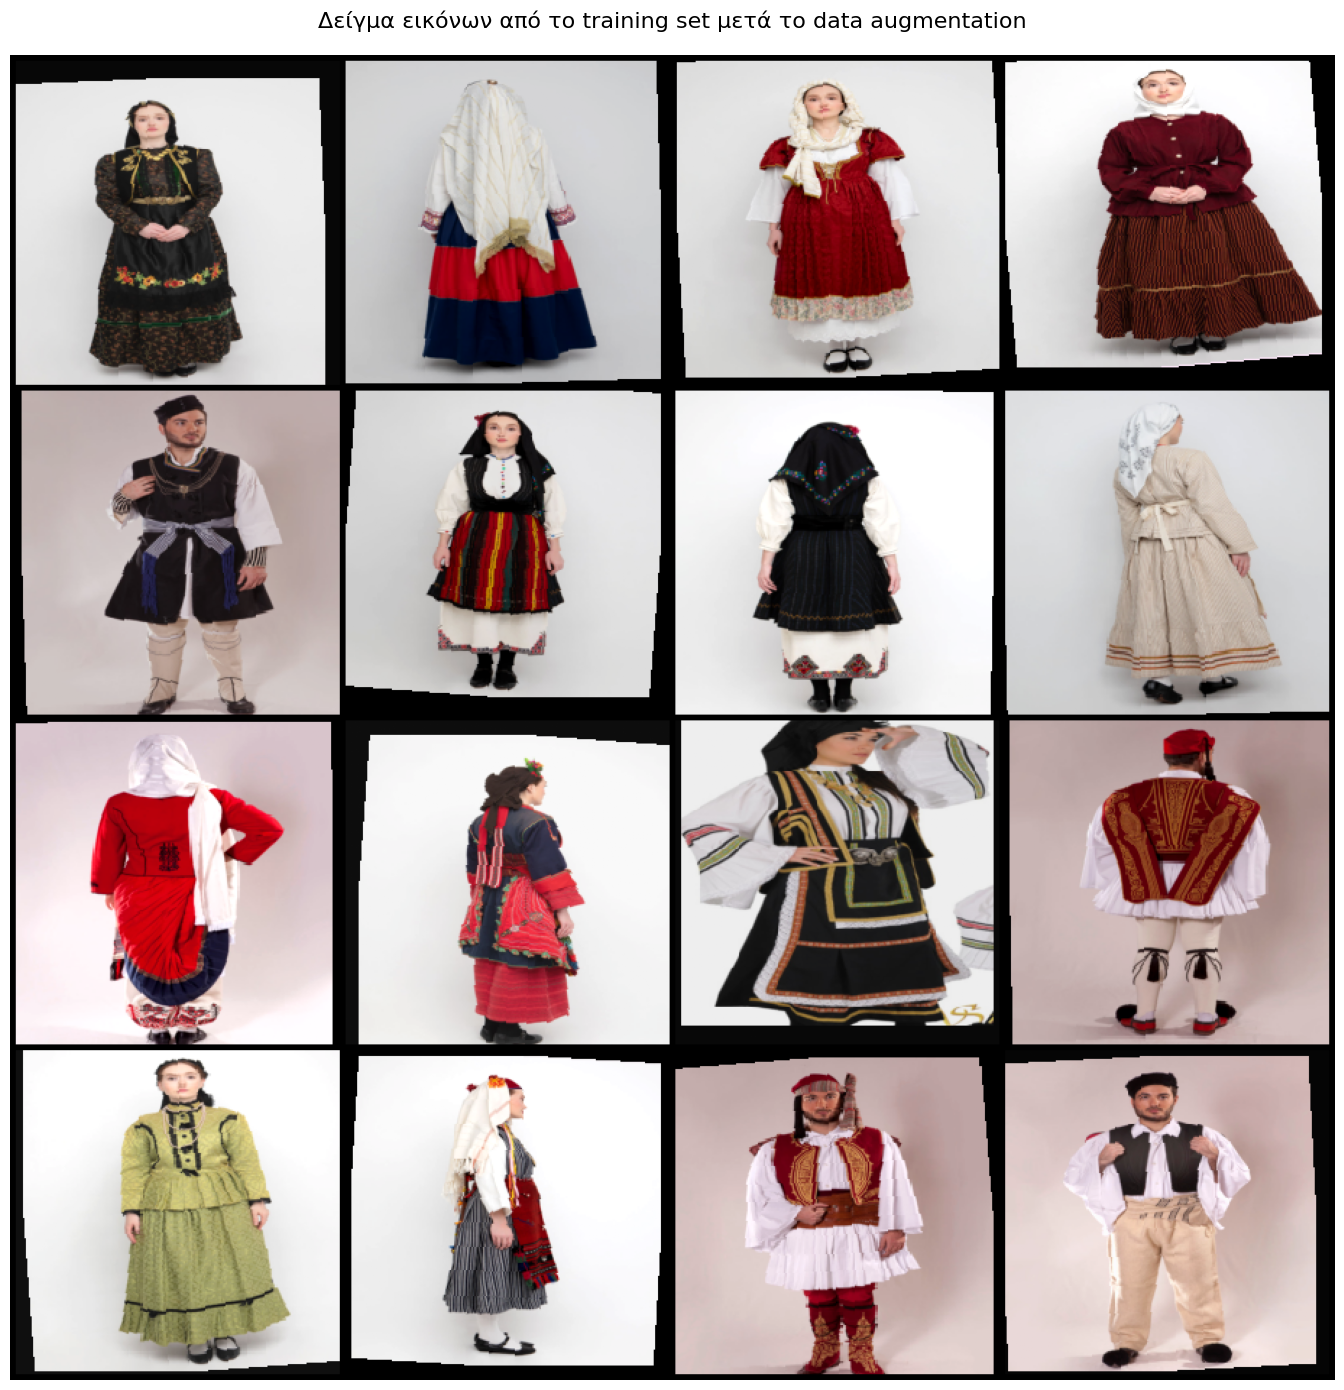

ΕΤΙΚΕΤΕΣ ΤΩΝ ΕΜΦΑΝΙΖΟΜΕΝΩΝ ΕΙΚΟΝΩΝ
Εικόνα 01 -> label 2 -> makedonia
Εικόνα 02 -> label 5 -> peloponnisos
Εικόνα 03 -> label 3 -> nisia_aigaiou
Εικόνα 04 -> label 3 -> nisia_aigaiou
Εικόνα 05 -> label 2 -> makedonia
Εικόνα 06 -> label 2 -> makedonia
Εικόνα 07 -> label 2 -> makedonia
Εικόνα 08 -> label 5 -> peloponnisos
Εικόνα 09 -> label 1 -> kriti
Εικόνα 10 -> label 2 -> makedonia
Εικόνα 11 -> label 7 -> thessalia
Εικόνα 12 -> label 5 -> peloponnisos
Εικόνα 13 -> label 3 -> nisia_aigaiou
Εικόνα 14 -> label 8 -> thraki
Εικόνα 15 -> label 5 -> peloponnisos
Εικόνα 16 -> label 0 -> ipeiros

Η Ενότητα 5 ολοκληρώθηκε επιτυχώς.


In [5]:
# =============================================================================
# ΕΝΟΤΗΤΑ 5 — ΟΠΤΙΚΟΣ ΕΛΕΓΧΟΣ ΤΟΥ DATASET
# =============================================================================

import matplotlib.pyplot as plt
import torchvision


# -----------------------------------------------------------------------------
# 5.1 Συνάρτηση αποκανονικοποίησης εικόνας
# -----------------------------------------------------------------------------
# Οι εικόνες έχουν κανονικοποιηθεί με τις τιμές του ImageNet.
# Για να εμφανιστούν σωστά, αντιστρέφεται προσωρινά η κανονικοποίηση.

def denormalize_image(image_tensor):
    """
    Αντιστρέφει την κανονικοποίηση ImageNet ενός tensor εικόνας.

    Parameters
    ----------
    image_tensor : torch.Tensor
        Tensor εικόνας με σχήμα [3, height, width].

    Returns
    -------
    torch.Tensor
        Αποκανονικοποιημένο tensor με τιμές στο διάστημα [0, 1].
    """

    if image_tensor.ndim != 3:
        raise ValueError(
            "Το tensor της εικόνας πρέπει να έχει τρεις διαστάσεις: "
            "[channels, height, width]."
        )

    if image_tensor.shape[0] != 3:
        raise ValueError(
            "Το tensor της εικόνας πρέπει να περιέχει τρία RGB κανάλια."
        )

    mean = torch.tensor(
        IMAGENET_MEAN,
        dtype=image_tensor.dtype,
        device=image_tensor.device
    ).view(3, 1, 1)

    std = torch.tensor(
        IMAGENET_STD,
        dtype=image_tensor.dtype,
        device=image_tensor.device
    ).view(3, 1, 1)

    denormalized_image = image_tensor * std + mean

    return torch.clamp(
        denormalized_image,
        min=0.0,
        max=1.0
    )


# -----------------------------------------------------------------------------
# 5.2 Ανάγνωση ενός batch από το training set
# -----------------------------------------------------------------------------

visual_images, visual_labels = next(
    iter(train_loader)
)


# -----------------------------------------------------------------------------
# 5.3 Έλεγχος των δεδομένων του batch
# -----------------------------------------------------------------------------

if visual_images.ndim != 4:
    raise ValueError(
        "Το tensor του batch εικόνων πρέπει να έχει τέσσερις διαστάσεις."
    )

if visual_labels.ndim != 1:
    raise ValueError(
        "Το tensor των labels πρέπει να έχει μία διάσταση."
    )

if visual_images.shape[0] != visual_labels.shape[0]:
    raise ValueError(
        "Το πλήθος των εικόνων δεν είναι ίσο με το πλήθος των labels."
    )


# -----------------------------------------------------------------------------
# 5.4 Επιλογή εικόνων προς εμφάνιση
# -----------------------------------------------------------------------------
# Εμφανίζονται έως 16 εικόνες.

MAX_IMAGES_TO_DISPLAY = 16

number_of_images_to_display = min(
    MAX_IMAGES_TO_DISPLAY,
    visual_images.shape[0]
)

selected_images = visual_images[
    :number_of_images_to_display
]

selected_labels = visual_labels[
    :number_of_images_to_display
]


# -----------------------------------------------------------------------------
# 5.5 Αποκανονικοποίηση των εικόνων
# -----------------------------------------------------------------------------

images_to_display = torch.stack([
    denormalize_image(image)
    for image in selected_images
])


# -----------------------------------------------------------------------------
# 5.6 Δημιουργία πλέγματος εικόνων
# -----------------------------------------------------------------------------
# Χρησιμοποιούνται έως τέσσερις εικόνες ανά σειρά.

GRID_COLUMNS = 4

image_grid = torchvision.utils.make_grid(
    images_to_display,
    nrow=GRID_COLUMNS,
    padding=4
)


# -----------------------------------------------------------------------------
# 5.7 Εμφάνιση του πλέγματος
# -----------------------------------------------------------------------------

plt.figure(figsize=(14, 14))

plt.imshow(
    image_grid
    .permute(1, 2, 0)
    .cpu()
    .numpy()
)

plt.axis("off")

plt.title(
    "Δείγμα εικόνων από το training set μετά το data augmentation",
    fontsize=16,
    pad=20
)

plt.tight_layout()
plt.show()


# -----------------------------------------------------------------------------
# 5.8 Εμφάνιση των πραγματικών ετικετών
# -----------------------------------------------------------------------------

print("=" * 70)
print("ΕΤΙΚΕΤΕΣ ΤΩΝ ΕΜΦΑΝΙΖΟΜΕΝΩΝ ΕΙΚΟΝΩΝ")
print("=" * 70)

for image_position, label_index in enumerate(
    selected_labels.tolist(),
    start=1
):
    if not 0 <= label_index < NUM_CLASSES:
        raise ValueError(
            f"Η εικόνα {image_position} έχει μη έγκυρο class index: "
            f"{label_index}."
        )

    class_name = CLASS_NAMES[label_index]

    print(
        f"Εικόνα {image_position:02d} "
        f"-> label {label_index} "
        f"-> {class_name}"
    )


# -----------------------------------------------------------------------------
# 5.9 Τελική επιβεβαίωση
# -----------------------------------------------------------------------------

print("\n" + "=" * 70)
print("Η Ενότητα 5 ολοκληρώθηκε επιτυχώς.")
print("=" * 70)

# Ενότητα 6 - Κοινές συναρτήσεις πειραμάτων

Στην ενότητα αυτή ορίζονται οι κοινές συναρτήσεις που θα χρησιμοποιηθούν για την εκπαίδευση και την αξιολόγηση όλων των μοντέλων.

Η χρήση κοινών συναρτήσεων εξασφαλίζει ότι τα πειράματα εκτελούνται με την ίδια διαδικασία και αξιολογούνται με τις ίδιες μετρικές. Με αυτόν τον τρόπο, η σύγκριση μεταξύ των διαφορετικών αρχιτεκτονικών και στρατηγικών μεταφοράς μάθησης πραγματοποιείται με συνεπή και αντικειμενικό τρόπο.

Οι συναρτήσεις της ενότητας καλύπτουν:

- τη δημιουργία των φακέλων κάθε πειράματος,
- τον υπολογισμό των συνολικών και εκπαιδεύσιμων παραμέτρων,
- την εκτέλεση μίας εποχής εκπαίδευσης,
- την εκτέλεση μίας εποχής επικύρωσης,
- την πλήρη διαδικασία εκπαίδευσης με Early Stopping,
- την αποθήκευση του καλύτερου checkpoint,
- την οπτικοποίηση της πορείας εκπαίδευσης,
- την τελική αξιολόγηση στο test set,
- τον υπολογισμό των μετρικών Accuracy, Macro Precision, Macro Recall, Macro F1-score και Weighted F1-score,
- τη δημιουργία Classification Report και Confusion Matrix,
- την αποθήκευση των ιστορικών εκπαίδευσης και των τελικών αποτελεσμάτων.

In [6]:
# =============================================================================
# ΕΝΟΤΗΤΑ 6 — ΚΟΙΝΕΣ ΣΥΝΑΡΤΗΣΕΙΣ ΠΕΙΡΑΜΑΤΩΝ
# =============================================================================

import copy
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score
)


# -----------------------------------------------------------------------------
# 6.1 Δημιουργία φακέλων ενός πειράματος
# -----------------------------------------------------------------------------

def create_experiment_directories(experiment_name):
    """
    Δημιουργεί τους φακέλους αποθήκευσης ενός πειράματος.

    Κάθε πείραμα δημιουργείται πάντα απευθείας μέσα στους σταθερούς
    κεντρικούς φακέλους:
    - results/
    - models/checkpoints/
    - models/trained/

    Parameters
    ----------
    experiment_name : str
        Μοναδικό όνομα του πειράματος.

    Returns
    -------
    dict
        Λεξικό με τις διαδρομές των φακέλων:
        - results_dir
        - checkpoint_dir
        - trained_model_dir
    """

    if not isinstance(experiment_name, str):
        raise TypeError(
            "Το experiment_name πρέπει να είναι συμβολοσειρά."
        )

    experiment_name = experiment_name.strip()

    if not experiment_name:
        raise ValueError(
            "Το experiment_name δεν μπορεί να είναι κενό."
        )

    # -------------------------------------------------------------------------
    # Δημιουργία διαδρομών από τους ΣΤΑΘΕΡΟΥΣ root φακέλους
    # -------------------------------------------------------------------------

    experiment_results_dir = (
        RESULTS_ROOT_DIR / experiment_name
    )

    experiment_checkpoint_dir = (
        CHECKPOINTS_ROOT_DIR / experiment_name
    )

    experiment_trained_model_dir = (
        TRAINED_MODELS_ROOT_DIR / experiment_name
    )

    # -------------------------------------------------------------------------
    # Δημιουργία φακέλων
    # -------------------------------------------------------------------------

    experiment_results_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    experiment_checkpoint_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    experiment_trained_model_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # -------------------------------------------------------------------------
    # Επιστροφή των διαδρομών του συγκεκριμένου πειράματος
    # -------------------------------------------------------------------------

    return {
        "results_dir": experiment_results_dir,
        "checkpoint_dir": experiment_checkpoint_dir,
        "trained_model_dir": experiment_trained_model_dir
    }


# -----------------------------------------------------------------------------
# 6.2 Υπολογισμός παραμέτρων μοντέλου
# -----------------------------------------------------------------------------

def count_model_parameters(model):
    """
    Υπολογίζει το πλήθος των συνολικών, εκπαιδεύσιμων και παγωμένων
    παραμέτρων ενός μοντέλου.

    Parameters
    ----------
    model : torch.nn.Module
        Το μοντέλο προς ανάλυση.

    Returns
    -------
    dict
        Λεξικό με το πλήθος των παραμέτρων.
    """

    total_parameters = sum(
        parameter.numel()
        for parameter in model.parameters()
    )

    trainable_parameters = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

    frozen_parameters = (
        total_parameters - trainable_parameters
    )

    return {
        "total_parameters": total_parameters,
        "trainable_parameters": trainable_parameters,
        "frozen_parameters": frozen_parameters
    }


# -----------------------------------------------------------------------------
# 6.3 Εμφάνιση πληροφοριών μοντέλου
# -----------------------------------------------------------------------------

def print_model_summary(
    model,
    experiment_name,
    transfer_learning_mode
):
    """
    Εμφανίζει βασικές πληροφορίες για το μοντέλο και τις παραμέτρους του.
    """

    parameter_counts = count_model_parameters(model)

    print("=" * 70)
    print("ΣΥΝΟΨΗ ΜΟΝΤΕΛΟΥ")
    print("=" * 70)

    print(f"Experiment name            : {experiment_name}")
    print(f"Model class                : {model.__class__.__name__}")
    print(f"Transfer learning mode     : {transfer_learning_mode}")
    print(f"Number of classes          : {NUM_CLASSES}")
    print(f"Running on                 : {DEVICE}")

    print("\nParameters:")
    print(
        f"Total parameters          : "
        f"{parameter_counts['total_parameters']:,}"
    )
    print(
        f"Trainable parameters      : "
        f"{parameter_counts['trainable_parameters']:,}"
    )
    print(
        f"Frozen parameters         : "
        f"{parameter_counts['frozen_parameters']:,}"
    )


# -----------------------------------------------------------------------------
# 6.4 Έλεγχος εξόδου μοντέλου
# -----------------------------------------------------------------------------

def validate_model_output(
    model,
    batch_size=BATCH_SIZE
):
    """
    Ελέγχει ότι η έξοδος του μοντέλου έχει το αναμενόμενο σχήμα.

    Το αναμενόμενο σχήμα είναι:
    [batch_size, NUM_CLASSES]
    """

    if batch_size <= 0:
        raise ValueError(
            "Το batch_size πρέπει να είναι θετικός ακέραιος."
        )

    dummy_batch = torch.randn(
        batch_size,
        3,
        IMAGE_SIZE,
        IMAGE_SIZE,
        device=DEVICE
    )

    model.eval()

    with torch.no_grad():
        output = model(dummy_batch)

    expected_shape = (
        batch_size,
        NUM_CLASSES
    )

    if output.shape != expected_shape:
        raise ValueError(
            "Η έξοδος του μοντέλου έχει λανθασμένο σχήμα.\n"
            f"Αναμενόμενο: {expected_shape}\n"
            f"Πραγματικό: {tuple(output.shape)}"
        )

    print("\nModel output check:")
    print(f"Output tensor shape        : {output.shape}")
    print("✓ Η έξοδος του μοντέλου έχει το σωστό σχήμα.")


# -----------------------------------------------------------------------------
# 6.5 Εκτέλεση μίας εποχής εκπαίδευσης
# -----------------------------------------------------------------------------

def train_one_epoch(
    model,
    data_loader,
    criterion,
    optimizer,
    device
):
    """
    Εκτελεί μία πλήρη εποχή εκπαίδευσης.

    Returns
    -------
    tuple
        Μέσο training loss και training accuracy.
    """

    model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for images, labels in data_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        batch_size = images.size(0)

        running_loss += (
            loss.item() * batch_size
        )

        predictions = outputs.argmax(
            dim=1
        )

        correct_predictions += (
            predictions == labels
        ).sum().item()

        total_samples += batch_size

    if total_samples == 0:
        raise ValueError(
            "Ο training DataLoader δεν περιείχε δείγματα."
        )

    epoch_loss = (
        running_loss / total_samples
    )

    epoch_accuracy = (
        correct_predictions / total_samples
    )

    return epoch_loss, epoch_accuracy


# -----------------------------------------------------------------------------
# 6.6 Εκτέλεση μίας εποχής αξιολόγησης
# -----------------------------------------------------------------------------

def evaluate_one_epoch(
    model,
    data_loader,
    criterion,
    device
):
    """
    Εκτελεί μία πλήρη εποχή αξιολόγησης χωρίς ενημέρωση των βαρών.

    Returns
    -------
    tuple
        Μέσο loss και accuracy.
    """

    model.eval()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            batch_size = images.size(0)

            running_loss += (
                loss.item() * batch_size
            )

            predictions = outputs.argmax(
                dim=1
            )

            correct_predictions += (
                predictions == labels
            ).sum().item()

            total_samples += batch_size

    if total_samples == 0:
        raise ValueError(
            "Ο DataLoader αξιολόγησης δεν περιείχε δείγματα."
        )

    epoch_loss = (
        running_loss / total_samples
    )

    epoch_accuracy = (
        correct_predictions / total_samples
    )

    return epoch_loss, epoch_accuracy


# -----------------------------------------------------------------------------
# 6.7 Πλήρης διαδικασία εκπαίδευσης
# -----------------------------------------------------------------------------

def train_model(
    model,
    train_loader,
    validation_loader,
    criterion,
    optimizer,
    experiment_name,
    checkpoint_path,
    max_epochs=MAX_EPOCHS,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    scheduler=None
):
    """
    Εκπαιδεύει ένα μοντέλο με Early Stopping.

    Το καλύτερο μοντέλο επιλέγεται με βάση το μικρότερο validation loss.
    """

    if max_epochs <= 0:
        raise ValueError(
            "Το max_epochs πρέπει να είναι θετικός ακέραιος."
        )

    if early_stopping_patience <= 0:
        raise ValueError(
            "Το early_stopping_patience πρέπει να είναι θετικός ακέραιος."
        )

    best_model_weights = copy.deepcopy(
        model.state_dict()
    )

    best_validation_loss = float("inf")
    best_validation_accuracy = 0.0
    best_epoch = 0

    early_stopping_counter = 0

    history = {
        "train_loss": [],
        "validation_loss": [],
        "train_accuracy": [],
        "validation_accuracy": [],
        "learning_rate": []
    }

    print("=" * 80)
    print(f"ΕΝΑΡΞΗ ΕΚΠΑΙΔΕΥΣΗΣ — {experiment_name}")
    print("=" * 80)

    training_start_time = time.time()

    for epoch in range(max_epochs):

        epoch_start_time = time.time()

        current_learning_rate = (
            optimizer.param_groups[0]["lr"]
        )

        print(
            f"\nEpoch [{epoch + 1}/{max_epochs}]"
        )

        print(
            f"Learning Rate       : "
            f"{current_learning_rate:.8f}"
        )

        train_loss, train_accuracy = train_one_epoch(
            model=model,
            data_loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=DEVICE
        )

        validation_loss, validation_accuracy = evaluate_one_epoch(
            model=model,
            data_loader=validation_loader,
            criterion=criterion,
            device=DEVICE
        )

        history["train_loss"].append(
            train_loss
        )

        history["validation_loss"].append(
            validation_loss
        )

        history["train_accuracy"].append(
            train_accuracy
        )

        history["validation_accuracy"].append(
            validation_accuracy
        )

        history["learning_rate"].append(
            current_learning_rate
        )

        epoch_duration = (
            time.time() - epoch_start_time
        )

        print(f"Train Loss          : {train_loss:.4f}")
        print(f"Validation Loss     : {validation_loss:.4f}")
        print(f"Train Accuracy      : {train_accuracy:.4f}")
        print(f"Validation Accuracy : {validation_accuracy:.4f}")
        print(f"Epoch Time          : {epoch_duration:.2f} seconds")

        # ---------------------------------------------------------------------
        # Έλεγχος βελτίωσης του validation loss
        # ---------------------------------------------------------------------

        if validation_loss < best_validation_loss:

            best_validation_loss = validation_loss
            best_validation_accuracy = validation_accuracy
            best_epoch = epoch + 1

            best_model_weights = copy.deepcopy(
                model.state_dict()
            )

            early_stopping_counter = 0

            checkpoint = {
                "experiment_name": experiment_name,
                "epoch": best_epoch,
                "model_state_dict": best_model_weights,
                "optimizer_state_dict": optimizer.state_dict(),
                "validation_loss": best_validation_loss,
                "validation_accuracy": best_validation_accuracy,
                "class_names": CLASS_NAMES,
                "class_to_idx": CLASS_TO_IDX,
                "image_size": IMAGE_SIZE
            }

            torch.save(
                checkpoint,
                checkpoint_path
            )

            print("✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.")

        else:

            early_stopping_counter += 1

            print(
                "Δεν παρατηρήθηκε βελτίωση "
                f"({early_stopping_counter}/"
                f"{early_stopping_patience})."
            )

        # ---------------------------------------------------------------------
        # Ενημέρωση scheduler
        # ---------------------------------------------------------------------

        if scheduler is not None:

            if isinstance(
                scheduler,
                torch.optim.lr_scheduler.ReduceLROnPlateau
            ):
                scheduler.step(
                    validation_loss
                )
            else:
                scheduler.step()

        # ---------------------------------------------------------------------
        # Early Stopping
        # ---------------------------------------------------------------------

        if (
            early_stopping_counter
            >= early_stopping_patience
        ):
            print("\n✓ Ενεργοποιήθηκε το Early Stopping.")
            break

    training_time = (
        time.time() - training_start_time
    )

    model.load_state_dict(
        best_model_weights
    )

    training_information = {
        "experiment_name": experiment_name,
        "training_time_seconds": training_time,
        "epochs_completed": len(
            history["train_loss"]
        ),
        "best_epoch": best_epoch,
        "best_validation_loss": best_validation_loss,
        "best_validation_accuracy": best_validation_accuracy
    }

    print("\n" + "=" * 80)
    print("Η ΕΚΠΑΙΔΕΥΣΗ ΟΛΟΚΛΗΡΩΘΗΚΕ")
    print("=" * 80)

    print(
        f"Training time           : "
        f"{training_time:.2f} seconds"
    )

    print(
        f"Epochs completed        : "
        f"{training_information['epochs_completed']}"
    )

    print(
        f"Best epoch              : "
        f"{best_epoch}"
    )

    print(
        f"Best validation loss    : "
        f"{best_validation_loss:.4f}"
    )

    print(
        f"Best validation accuracy: "
        f"{best_validation_accuracy:.4f}"
    )

    return model, history, training_information


# -----------------------------------------------------------------------------
# 6.8 Οπτικοποίηση του ιστορικού εκπαίδευσης
# -----------------------------------------------------------------------------

def plot_training_history(
    history,
    experiment_name,
    results_dir,
    save_plots=True
):
    """
    Δημιουργεί ξεχωριστά διαγράμματα για το loss και το accuracy.
    """

    required_history_keys = [
        "train_loss",
        "validation_loss",
        "train_accuracy",
        "validation_accuracy"
    ]

    for key in required_history_keys:
        if key not in history:
            raise KeyError(
                f"Δεν βρέθηκε το πεδίο '{key}' στο history."
            )

    number_of_epochs = len(
        history["train_loss"]
    )

    if number_of_epochs == 0:
        raise ValueError(
            "Το history δεν περιέχει αποτελέσματα εκπαίδευσης."
        )

    epochs = range(
        1,
        number_of_epochs + 1
    )

    # -------------------------------------------------------------------------
    # Διάγραμμα Loss
    # -------------------------------------------------------------------------

    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs,
        history["train_loss"],
        label="Train Loss",
        linewidth=2
    )

    plt.plot(
        epochs,
        history["validation_loss"],
        label="Validation Loss",
        linewidth=2
    )

    plt.title(
        f"Training and Validation Loss\n{experiment_name}"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    if save_plots:
        loss_plot_path = (
            results_dir / "loss_curve.png"
        )

        plt.savefig(
            loss_plot_path,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()

    # -------------------------------------------------------------------------
    # Διάγραμμα Accuracy
    # -------------------------------------------------------------------------

    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs,
        history["train_accuracy"],
        label="Train Accuracy",
        linewidth=2
    )

    plt.plot(
        epochs,
        history["validation_accuracy"],
        label="Validation Accuracy",
        linewidth=2
    )

    plt.title(
        f"Training and Validation Accuracy\n{experiment_name}"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    if save_plots:
        accuracy_plot_path = (
            results_dir / "accuracy_curve.png"
        )

        plt.savefig(
            accuracy_plot_path,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()

    print("✓ Τα διαγράμματα εκπαίδευσης δημιουργήθηκαν επιτυχώς.")


# -----------------------------------------------------------------------------
# 6.9 Συλλογή προβλέψεων από έναν DataLoader
# -----------------------------------------------------------------------------

def collect_predictions(
    model,
    data_loader,
    device
):
    """
    Συλλέγει τις πραγματικές ετικέτες και τις προβλέψεις του μοντέλου.

    Returns
    -------
    tuple
        Πραγματικές ετικέτες και προβλέψεις ως NumPy arrays.
    """

    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            predictions = outputs.argmax(
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    if len(all_labels) == 0:
        raise ValueError(
            "Δεν συλλέχθηκαν πραγματικές ετικέτες."
        )

    if len(all_predictions) == 0:
        raise ValueError(
            "Δεν συλλέχθηκαν προβλέψεις."
        )

    if len(all_labels) != len(all_predictions):
        raise ValueError(
            "Το πλήθος των πραγματικών ετικετών δεν είναι ίσο "
            "με το πλήθος των προβλέψεων."
        )

    return (
        np.asarray(all_labels),
        np.asarray(all_predictions)
    )


# -----------------------------------------------------------------------------
# 6.9.1 Συλλογή Top-3 προβλέψεων
# -----------------------------------------------------------------------------

def collect_top3_predictions(
    model,
    data_loader,
    device
):
    """
    Συλλέγει τις πραγματικές ετικέτες και τις τρεις πιθανότερες
    προβλέψεις του μοντέλου.

    Returns
    -------
    tuple
        Πραγματικές ετικέτες και Top-3 προβλέψεις ως NumPy arrays.
    """

    model.eval()

    all_labels = []
    all_top3_predictions = []

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            top3_predictions = torch.topk(
                outputs,
                k=3,
                dim=1
            ).indices

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_top3_predictions.extend(
                top3_predictions.cpu().numpy()
            )

    if len(all_labels) == 0:
        raise ValueError(
            "Δεν συλλέχθηκαν πραγματικές ετικέτες."
        )

    if len(all_top3_predictions) == 0:
        raise ValueError(
            "Δεν συλλέχθηκαν Top-3 προβλέψεις."
        )

    if len(all_labels) != len(all_top3_predictions):
        raise ValueError(
            "Το πλήθος των πραγματικών ετικετών δεν είναι ίσο "
            "με το πλήθος των Top-3 προβλέψεων."
        )

    return (
        np.asarray(all_labels),
        np.asarray(all_top3_predictions)
    )


# -----------------------------------------------------------------------------
# 6.10 Αξιολόγηση μοντέλου στο test set
# -----------------------------------------------------------------------------

def evaluate_model_on_test_set(
    model,
    test_loader,
    class_names,
    experiment_name,
    results_dir,
    save_results=True
):
    """
    Αξιολογεί το μοντέλο στο test set και εμφανίζει τις τελικές μετρικές.

    Περιλαμβάνει:
    - Top-1 Accuracy
    - Top-3 Accuracy
    - Macro Precision
    - Macro Recall
    - Macro F1
    - Weighted F1

    Returns
    -------
    dict
        Λεξικό με τις βασικές μετρικές αξιολόγησης.
    """

    all_labels, all_predictions = collect_predictions(
        model=model,
        data_loader=test_loader,
        device=DEVICE
    )

    all_top3_labels, all_top3_predictions = (
        collect_top3_predictions(
            model=model,
            data_loader=test_loader,
            device=DEVICE
        )
    )

    if not np.array_equal(
        all_labels,
        all_top3_labels
    ):
        raise ValueError(
            "Οι πραγματικές ετικέτες των Top-1 και Top-3 "
            "αξιολογήσεων δεν συμφωνούν."
        )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    top3_correct = (
        all_top3_predictions
        == all_labels.reshape(-1, 1)
    ).any(axis=1)

    top3_accuracy = (
        top3_correct.mean()
    )

    macro_precision = precision_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )

    test_metrics = {
        "experiment_name": experiment_name,
        "accuracy": float(accuracy),
        "top3_accuracy": float(top3_accuracy),
        "macro_precision": float(macro_precision),
        "macro_recall": float(macro_recall),
        "macro_f1": float(macro_f1),
        "weighted_f1": float(weighted_f1)
    }

    print("=" * 70)
    print(f"TEST SET RESULTS — {experiment_name}")
    print("=" * 70)

    print(f"Accuracy          : {accuracy:.4f}")
    print(f"Top-3 Accuracy    : {top3_accuracy:.4f}")
    print(f"Macro Precision   : {macro_precision:.4f}")
    print(f"Macro Recall      : {macro_recall:.4f}")
    print(f"Macro F1-score    : {macro_f1:.4f}")
    print(f"Weighted F1-score : {weighted_f1:.4f}")

    # -------------------------------------------------------------------------
    # Classification Report
    # -------------------------------------------------------------------------

    report_text = classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    )

    report_dictionary = classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    print("\n" + "=" * 70)
    print("CLASSIFICATION REPORT")
    print("=" * 70)

    print(report_text)

    # -------------------------------------------------------------------------
    # Confusion Matrix
    # -------------------------------------------------------------------------

    confusion_matrix_values = confusion_matrix(
        all_labels,
        all_predictions,
        labels=list(range(len(class_names)))
    )

    figure, axis = plt.subplots(
        figsize=(12, 10)
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix_values,
        display_labels=class_names
    )

    display.plot(
        ax=axis,
        cmap="Blues",
        xticks_rotation=45,
        values_format="d",
        colorbar=False
    )

    axis.set_title(
        f"Confusion Matrix\n{experiment_name}"
    )

    figure.tight_layout()

    if save_results:

        confusion_matrix_path = (
            results_dir / "confusion_matrix.png"
        )

        figure.savefig(
            confusion_matrix_path,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()

    # -------------------------------------------------------------------------
    # Αποθήκευση αποτελεσμάτων
    # -------------------------------------------------------------------------

    if save_results:

        metrics_path = (
            results_dir / "test_metrics.json"
        )

        classification_report_path = (
            results_dir / "classification_report.json"
        )

        classification_report_text_path = (
            results_dir / "classification_report.txt"
        )

        predictions_path = (
            results_dir / "test_predictions.npz"
        )

        save_json_file(
            data=test_metrics,
            file_path=metrics_path
        )

        save_json_file(
            data=report_dictionary,
            file_path=classification_report_path
        )

        with open(
            classification_report_text_path,
            "w",
            encoding="utf-8"
        ) as file:

            file.write(
                report_text
            )

        np.savez(
            predictions_path,
            true_labels=all_labels,
            predicted_labels=all_predictions,
            top3_predictions=all_top3_predictions
        )

        print("\nΑποθηκεύτηκαν:")
        print(f"Metrics              : {metrics_path}")
        print(f"Classification report: {classification_report_path}")
        print(f"Predictions          : {predictions_path}")
        print(f"Confusion matrix     : {confusion_matrix_path}")

    return test_metrics


# -----------------------------------------------------------------------------
# 6.11 Αποθήκευση λεξικού σε αρχείο JSON
# -----------------------------------------------------------------------------

def save_json_file(
    data,
    file_path
):
    """
    Αποθηκεύει ένα λεξικό ή μία λίστα σε αρχείο JSON.
    """

    file_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    with open(
        file_path,
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            data,
            file,
            ensure_ascii=False,
            indent=4
        )


# -----------------------------------------------------------------------------
# 6.12 Αποθήκευση ιστορικού και πληροφοριών εκπαίδευσης
# -----------------------------------------------------------------------------

def save_training_results(
    history,
    training_information,
    results_dir
):
    """
    Αποθηκεύει το ιστορικό και τις πληροφορίες εκπαίδευσης σε JSON.
    """

    history_path = (
        results_dir / "training_history.json"
    )

    training_information_path = (
        results_dir / "training_information.json"
    )

    save_json_file(
        data=history,
        file_path=history_path
    )

    save_json_file(
        data=training_information,
        file_path=training_information_path
    )

    print("✓ Αποθηκεύτηκαν τα αποτελέσματα εκπαίδευσης.")

    print(f"Training history     : {history_path}")
    print(f"Training information : {training_information_path}")


# -----------------------------------------------------------------------------
# 6.13 Αποθήκευση τελικού μοντέλου
# -----------------------------------------------------------------------------

def save_final_model(
    model,
    experiment_name,
    model_path,
    test_metrics=None
):
    """
    Αποθηκεύει το τελικό καλύτερο μοντέλο μαζί με βασικές πληροφορίες.
    """

    model_data = {
        "experiment_name": experiment_name,
        "model_state_dict": model.state_dict(),
        "class_names": CLASS_NAMES,
        "class_to_idx": CLASS_TO_IDX,
        "number_of_classes": NUM_CLASSES,
        "image_size": IMAGE_SIZE,
        "imagenet_mean": IMAGENET_MEAN,
        "imagenet_std": IMAGENET_STD
    }

    if test_metrics is not None:
        model_data["test_metrics"] = test_metrics

    model_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    torch.save(
        model_data,
        model_path
    )

    print("✓ Το τελικό μοντέλο αποθηκεύτηκε επιτυχώς.")
    print(f"Model path: {model_path}")


# -----------------------------------------------------------------------------
# 6.14 Τελική επιβεβαίωση
# -----------------------------------------------------------------------------

print("=" * 70)
print("ΚΟΙΝΕΣ ΣΥΝΑΡΤΗΣΕΙΣ ΠΕΙΡΑΜΑΤΩΝ")
print("=" * 70)

print("Δημιουργήθηκαν οι συναρτήσεις:")

print("1.  create_experiment_directories")
print("2.  count_model_parameters")
print("3.  print_model_summary")
print("4.  validate_model_output")
print("5.  train_one_epoch")
print("6.  evaluate_one_epoch")
print("7.  train_model")
print("8.  plot_training_history")
print("9.  collect_predictions")
print("10. collect_top3_predictions")
print("11. evaluate_model_on_test_set")
print("12. save_json_file")
print("13. save_training_results")
print("14. save_final_model")

print("\n" + "=" * 70)
print("Η Ενότητα 6 ολοκληρώθηκε επιτυχώς.")
print("=" * 70)

ΚΟΙΝΕΣ ΣΥΝΑΡΤΗΣΕΙΣ ΠΕΙΡΑΜΑΤΩΝ
Δημιουργήθηκαν οι συναρτήσεις:
1.  create_experiment_directories
2.  count_model_parameters
3.  print_model_summary
4.  validate_model_output
5.  train_one_epoch
6.  evaluate_one_epoch
7.  train_model
8.  plot_training_history
9.  collect_predictions
10. collect_top3_predictions
11. evaluate_model_on_test_set
12. save_json_file
13. save_training_results
14. save_final_model

Η Ενότητα 6 ολοκληρώθηκε επιτυχώς.


# ΠΕΙΡΑΜΑ 1 — ResNet18 Feature Extraction

Στο πρώτο πείραμα εφαρμόζεται η τεχνική μεταφοράς μάθησης Feature Extraction με βάση την αρχιτεκτονική ResNet18.

Το μοντέλο φορτώνεται με βάρη προεκπαιδευμένα στο σύνολο δεδομένων ImageNet. Στη συνέχεια, όλες οι παράμετροι του συνελικτικού τμήματος παγώνουν, ώστε να μη μεταβάλλονται κατά την εκπαίδευση. Το αρχικό πλήρως συνδεδεμένο επίπεδο αντικαθίσταται από ένα νέο επίπεδο εξόδου, προσαρμοσμένο στις κατηγορίες του συγκεκριμένου dataset.

Κατά συνέπεια, εκπαιδεύεται μόνο το νέο επίπεδο ταξινόμησης. Η προσέγγιση αυτή είναι κατάλληλη για μικρά σύνολα δεδομένων, καθώς μειώνει τον αριθμό των εκπαιδεύσιμων παραμέτρων και περιορίζει τον κίνδυνο υπερπροσαρμογής.

Η απόδοση του μοντέλου αξιολογείται στο σύνολο επικύρωσης κατά τη διάρκεια της εκπαίδευσης και στο σύνολο ελέγχου μετά την επιλογή του καλύτερου μοντέλου.

In [7]:
# =============================================================================
# 7.1 ΡΥΘΜΙΣΕΙΣ ΠΕΙΡΑΜΑΤΟΣ
# =============================================================================

EXPERIMENT_NAME = "resnet18_feature_extraction"
MODEL_ARCHITECTURE = "ResNet18"
TRANSFER_LEARNING_MODE = "Feature Extraction"

EXPERIMENT_LEARNING_RATE = DEFAULT_LEARNING_RATE
EXPERIMENT_WEIGHT_DECAY = DEFAULT_WEIGHT_DECAY


# -----------------------------------------------------------------------------
# Δημιουργία φακέλων του πειράματος
# -----------------------------------------------------------------------------

experiment_directories = create_experiment_directories(
    experiment_name=EXPERIMENT_NAME
)

EXPERIMENT_RESULTS_DIR = (
    experiment_directories["results_dir"]
)

EXPERIMENT_CHECKPOINT_DIR = (
    experiment_directories["checkpoint_dir"]
)

EXPERIMENT_TRAINED_MODEL_DIR = (
    experiment_directories["trained_model_dir"]
)


# -----------------------------------------------------------------------------
# Διαδρομές αρχείων του πειράματος
# -----------------------------------------------------------------------------

BEST_CHECKPOINT_PATH = (
    EXPERIMENT_CHECKPOINT_DIR
    / "best_checkpoint.pth"
)

FINAL_MODEL_PATH = (
    EXPERIMENT_TRAINED_MODEL_DIR
    / "resnet18_feature_extraction.pth"
)


# -----------------------------------------------------------------------------
# Εμφάνιση ρυθμίσεων
# -----------------------------------------------------------------------------

print("=" * 70)
print("ΠΕΙΡΑΜΑ 1 — ΡΥΘΜΙΣΕΙΣ")
print("=" * 70)

print(f"Experiment name       : {EXPERIMENT_NAME}")
print(f"Model architecture    : {MODEL_ARCHITECTURE}")
print(f"Transfer learning     : {TRANSFER_LEARNING_MODE}")

print("\nOptimization:")
print(f"Learning rate         : {EXPERIMENT_LEARNING_RATE}")
print(f"Weight decay          : {EXPERIMENT_WEIGHT_DECAY}")
print(f"Maximum epochs        : {MAX_EPOCHS}")
print(f"Early stopping        : {EARLY_STOPPING_PATIENCE}")

print("\nOutput directories:")
print(f"Results directory     : {EXPERIMENT_RESULTS_DIR}")
print(f"Checkpoint directory  : {EXPERIMENT_CHECKPOINT_DIR}")
print(f"Model directory       : {EXPERIMENT_TRAINED_MODEL_DIR}")

print("\nOutput files:")
print(f"Best checkpoint       : {BEST_CHECKPOINT_PATH}")
print(f"Final model           : {FINAL_MODEL_PATH}")

ΠΕΙΡΑΜΑ 1 — ΡΥΘΜΙΣΕΙΣ
Experiment name       : resnet18_feature_extraction
Model architecture    : ResNet18
Transfer learning     : Feature Extraction

Optimization:
Learning rate         : 0.001
Weight decay          : 0.0001
Maximum epochs        : 25
Early stopping        : 5

Output directories:
Results directory     : /content/drive/MyDrive/ptyxiaki/results/resnet18_feature_extraction
Checkpoint directory  : /content/drive/MyDrive/ptyxiaki/models/checkpoints/resnet18_feature_extraction
Model directory       : /content/drive/MyDrive/ptyxiaki/models/trained/resnet18_feature_extraction

Output files:
Best checkpoint       : /content/drive/MyDrive/ptyxiaki/models/checkpoints/resnet18_feature_extraction/best_checkpoint.pth
Final model           : /content/drive/MyDrive/ptyxiaki/models/trained/resnet18_feature_extraction/resnet18_feature_extraction.pth


## Δημιουργία του μοντέλου

Αρχικά φορτώνεται το ResNet18 με προεκπαιδευμένα βάρη από το ImageNet. Έπειτα, όλες οι υπάρχουσες παράμετροι του δικτύου παγώνουν με την επιλογή `requires_grad = False`.

Το αρχικό πλήρως συνδεδεμένο επίπεδο της αρχιτεκτονικής αντικαθίσταται από ένα νέο γραμμικό επίπεδο, του οποίου ο αριθμός εξόδων είναι ίσος με το πλήθος των κατηγοριών του dataset. Οι παράμετροι του νέου επιπέδου παραμένουν εκπαιδεύσιμες.

In [8]:
# =============================================================================
# 7.2 ΔΗΜΙΟΥΡΓΙΑ RESNET18 ΓΙΑ FEATURE EXTRACTION
# =============================================================================

import torch.nn as nn

from torchvision.models import (
    ResNet18_Weights,
    resnet18
)


# -----------------------------------------------------------------------------
# 7.2.1 Φόρτωση προεκπαιδευμένων βαρών
# -----------------------------------------------------------------------------

resnet18_weights = (
    ResNet18_Weights.DEFAULT
)

model = resnet18(
    weights=resnet18_weights
)


# -----------------------------------------------------------------------------
# 7.2.2 Πάγωμα όλων των προεκπαιδευμένων παραμέτρων
# -----------------------------------------------------------------------------

for parameter in model.parameters():
    parameter.requires_grad = False


# -----------------------------------------------------------------------------
# 7.2.3 Αντικατάσταση του τελικού πλήρως συνδεδεμένου επιπέδου
# -----------------------------------------------------------------------------

number_of_input_features = (
    model.fc.in_features
)

model.fc = nn.Linear(
    in_features=number_of_input_features,
    out_features=NUM_CLASSES
)


# -----------------------------------------------------------------------------
# 7.2.4 Μεταφορά του μοντέλου στη διαθέσιμη συσκευή
# -----------------------------------------------------------------------------

model = model.to(
    DEVICE
)


# -----------------------------------------------------------------------------
# 7.2.5 Έλεγχος ότι εκπαιδεύεται μόνο το νέο επίπεδο
# -----------------------------------------------------------------------------

trainable_parameter_names = [
    parameter_name
    for parameter_name, parameter in model.named_parameters()
    if parameter.requires_grad
]

expected_trainable_parameter_names = [
    "fc.weight",
    "fc.bias"
]

if trainable_parameter_names != expected_trainable_parameter_names:
    raise ValueError(
        "Στο Feature Extraction πρέπει να είναι εκπαιδεύσιμες "
        "μόνο οι παράμετροι fc.weight και fc.bias.\n"
        f"Βρέθηκαν: {trainable_parameter_names}"
    )


# -----------------------------------------------------------------------------
# 7.2.6 Εμφάνιση σύνοψης του μοντέλου
# -----------------------------------------------------------------------------

print_model_summary(
    model=model,
    experiment_name=EXPERIMENT_NAME,
    transfer_learning_mode=TRANSFER_LEARNING_MODE
)

print("\nFinal classification layer:")
print(model.fc)

print("\nTrainable parameter names:")

for parameter_name in trainable_parameter_names:
    print(f"- {parameter_name}")


# -----------------------------------------------------------------------------
# 7.2.7 Έλεγχος εξόδου του μοντέλου
# -----------------------------------------------------------------------------

validate_model_output(
    model=model,
    batch_size=min(
        BATCH_SIZE,
        4
    )
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 181MB/s]


ΣΥΝΟΨΗ ΜΟΝΤΕΛΟΥ
Experiment name            : resnet18_feature_extraction
Model class                : ResNet
Transfer learning mode     : Feature Extraction
Number of classes          : 9
Running on                 : cuda

Parameters:
Total parameters          : 11,181,129
Trainable parameters      : 4,617
Frozen parameters         : 11,176,512

Final classification layer:
Linear(in_features=512, out_features=9, bias=True)

Trainable parameter names:
- fc.weight
- fc.bias

Model output check:
Output tensor shape        : torch.Size([4, 9])
✓ Η έξοδος του μοντέλου έχει το σωστό σχήμα.


## Συνάρτηση κόστους και optimizer

Για το πρόβλημα πολυταξικής ταξινόμησης χρησιμοποιείται η συνάρτηση κόστους Cross-Entropy Loss.

Ως αλγόριθμος βελτιστοποίησης χρησιμοποιείται ο Adam. Στον optimizer εισάγονται αποκλειστικά οι παράμετροι που έχουν οριστεί ως εκπαιδεύσιμες. Επομένως, στο συγκεκριμένο πείραμα ενημερώνονται μόνο τα βάρη και η μεροληψία του νέου τελικού επιπέδου ταξινόμησης.

In [9]:
# =============================================================================
# 7.3 ΣΥΝΑΡΤΗΣΗ ΚΟΣΤΟΥΣ ΚΑΙ OPTIMIZER
# =============================================================================

import torch.optim as optim


# -----------------------------------------------------------------------------
# 7.3.1 Συνάρτηση κόστους
# -----------------------------------------------------------------------------

criterion = nn.CrossEntropyLoss()


# -----------------------------------------------------------------------------
# 7.3.2 Επιλογή μόνο των εκπαιδεύσιμων παραμέτρων
# -----------------------------------------------------------------------------

trainable_parameters = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]

if len(trainable_parameters) == 0:
    raise ValueError(
        "Δεν βρέθηκαν εκπαιδεύσιμες παράμετροι."
    )


# -----------------------------------------------------------------------------
# 7.3.3 Δημιουργία optimizer
# -----------------------------------------------------------------------------

optimizer = optim.Adam(
    params=trainable_parameters,
    lr=EXPERIMENT_LEARNING_RATE,
    weight_decay=EXPERIMENT_WEIGHT_DECAY
)


# -----------------------------------------------------------------------------
# 7.3.4 Έλεγχος optimizer
# -----------------------------------------------------------------------------

optimizer_parameter_count = sum(
    parameter.numel()
    for parameter_group in optimizer.param_groups
    for parameter in parameter_group["params"]
)

model_trainable_parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

if (
    optimizer_parameter_count
    != model_trainable_parameter_count
):
    raise ValueError(
        "Ο optimizer δεν περιλαμβάνει ακριβώς όλες τις "
        "εκπαιδεύσιμες παραμέτρους."
    )


# -----------------------------------------------------------------------------
# 7.3.5 Εμφάνιση ρυθμίσεων
# -----------------------------------------------------------------------------

print("=" * 70)
print("ΣΥΝΑΡΤΗΣΗ ΚΟΣΤΟΥΣ ΚΑΙ OPTIMIZER")
print("=" * 70)

print(f"Loss function          : {criterion.__class__.__name__}")
print(f"Optimizer              : {optimizer.__class__.__name__}")
print(f"Learning rate          : {EXPERIMENT_LEARNING_RATE}")
print(f"Weight decay           : {EXPERIMENT_WEIGHT_DECAY}")
print(f"Optimized parameters   : {optimizer_parameter_count:,}")

ΣΥΝΑΡΤΗΣΗ ΚΟΣΤΟΥΣ ΚΑΙ OPTIMIZER
Loss function          : CrossEntropyLoss
Optimizer              : Adam
Learning rate          : 0.001
Weight decay           : 0.0001
Optimized parameters   : 4,617


## Εκπαίδευση του μοντέλου

Το μοντέλο εκπαιδεύεται για έως και τον προκαθορισμένο μέγιστο αριθμό εποχών. Μετά από κάθε εποχή υπολογίζονται το loss και η accuracy τόσο στο σύνολο εκπαίδευσης όσο και στο σύνολο επικύρωσης.

Το καλύτερο μοντέλο επιλέγεται με βάση τη μικρότερη τιμή του validation loss. Χρησιμοποιείται επίσης Early Stopping, ώστε η διαδικασία να διακόπτεται όταν δεν παρατηρείται βελτίωση για συγκεκριμένο αριθμό διαδοχικών εποχών.

In [10]:
# =============================================================================
# 7.4 ΕΚΠΑΙΔΕΥΣΗ ΤΟΥ ΜΟΝΤΕΛΟΥ
# =============================================================================

model, training_history, training_information = train_model(
    model=model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    criterion=criterion,
    optimizer=optimizer,
    experiment_name=EXPERIMENT_NAME,
    checkpoint_path=BEST_CHECKPOINT_PATH,
    max_epochs=MAX_EPOCHS,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    scheduler=None
)

ΕΝΑΡΞΗ ΕΚΠΑΙΔΕΥΣΗΣ — resnet18_feature_extraction

Epoch [1/25]
Learning Rate       : 0.00100000
Train Loss          : 2.2818
Validation Loss     : 2.2177
Train Accuracy      : 0.1189
Validation Accuracy : 0.1111
Epoch Time          : 132.44 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [2/25]
Learning Rate       : 0.00100000
Train Loss          : 2.0330
Validation Loss     : 2.0881
Train Accuracy      : 0.2448
Validation Accuracy : 0.3175
Epoch Time          : 3.41 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [3/25]
Learning Rate       : 0.00100000
Train Loss          : 1.9507
Validation Loss     : 2.0137
Train Accuracy      : 0.3462
Validation Accuracy : 0.3333
Epoch Time          : 5.45 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [4/25]
Learning Rate       : 0.00100000
Train Loss          : 1.7035
Validation Loss     : 1.9027
Train Accuracy      : 0.4685
Validation Accuracy : 0.3175
Epoch Time          : 3.56 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [5

In [11]:
# =============================================================================
# 7.5 ΑΠΟΘΗΚΕΥΣΗ ΑΠΟΤΕΛΕΣΜΑΤΩΝ ΕΚΠΑΙΔΕΥΣΗΣ
# =============================================================================

save_training_results(
    history=training_history,
    training_information=training_information,
    results_dir=EXPERIMENT_RESULTS_DIR
)

✓ Αποθηκεύτηκαν τα αποτελέσματα εκπαίδευσης.
Training history     : /content/drive/MyDrive/ptyxiaki/results/resnet18_feature_extraction/training_history.json
Training information : /content/drive/MyDrive/ptyxiaki/results/resnet18_feature_extraction/training_information.json


## Οπτικοποίηση της πορείας εκπαίδευσης

Στα ακόλουθα διαγράμματα παρουσιάζεται η εξέλιξη του loss και της accuracy στα σύνολα εκπαίδευσης και επικύρωσης. Η σύγκριση των δύο καμπυλών βοηθά στον εντοπισμό πιθανής υπερπροσαρμογής ή ανεπαρκούς εκπαίδευσης.

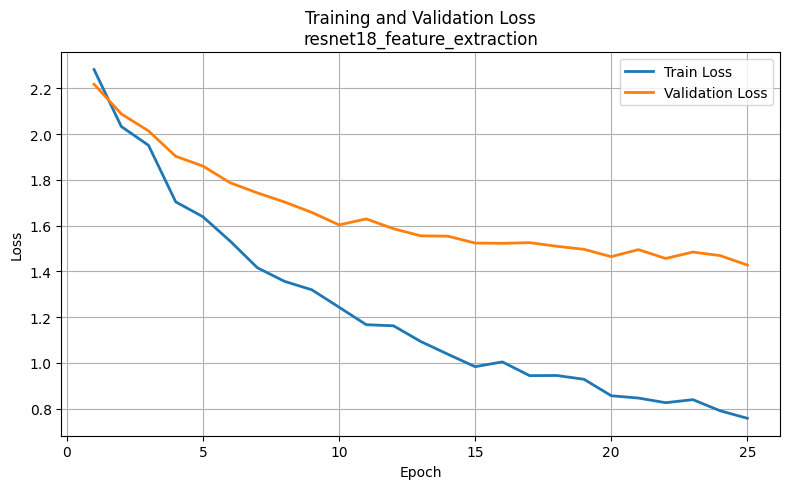

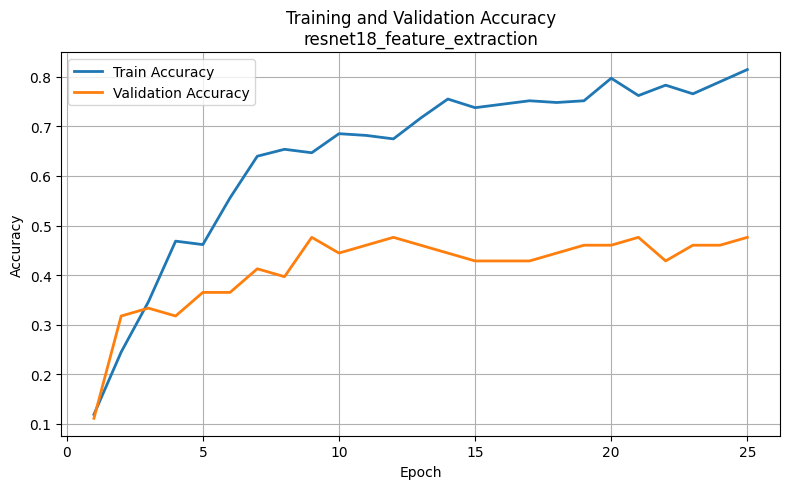

✓ Τα διαγράμματα εκπαίδευσης δημιουργήθηκαν επιτυχώς.


In [12]:
# =============================================================================
# 7.6 ΟΠΤΙΚΟΠΟΙΗΣΗ ΤΗΣ ΠΟΡΕΙΑΣ ΕΚΠΑΙΔΕΥΣΗΣ
# =============================================================================

plot_training_history(
    history=training_history,
    experiment_name=EXPERIMENT_NAME,
    results_dir=EXPERIMENT_RESULTS_DIR,
    save_plots=True
)

In [13]:
# =============================================================================
# 7.7 ΦΟΡΤΩΣΗ ΚΑΙ ΕΛΕΓΧΟΣ ΤΟΥ ΚΑΛΥΤΕΡΟΥ CHECKPOINT
# =============================================================================

if not BEST_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Δεν βρέθηκε το checkpoint:\n{BEST_CHECKPOINT_PATH}"
    )


best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=DEVICE
)


required_checkpoint_keys = [
    "experiment_name",
    "epoch",
    "model_state_dict",
    "optimizer_state_dict",
    "validation_loss",
    "validation_accuracy",
    "class_names",
    "class_to_idx",
    "image_size"
]

missing_checkpoint_keys = [
    key
    for key in required_checkpoint_keys
    if key not in best_checkpoint
]

if missing_checkpoint_keys:
    raise KeyError(
        "Λείπουν πεδία από το checkpoint: "
        f"{missing_checkpoint_keys}"
    )


if (
    best_checkpoint["experiment_name"]
    != EXPERIMENT_NAME
):
    raise ValueError(
        "Το checkpoint ανήκει σε διαφορετικό πείραμα."
    )


if (
    best_checkpoint["class_names"]
    != CLASS_NAMES
):
    raise ValueError(
        "Οι κλάσεις του checkpoint δεν συμφωνούν "
        "με τις κλάσεις του dataset."
    )


model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model = model.to(
    DEVICE
)

model.eval()


print("=" * 70)
print("ΚΑΛΥΤΕΡΟ CHECKPOINT")
print("=" * 70)

print(
    f"Experiment             : "
    f"{best_checkpoint['experiment_name']}"
)

print(
    f"Best epoch             : "
    f"{best_checkpoint['epoch']}"
)

print(
    f"Validation loss        : "
    f"{best_checkpoint['validation_loss']:.4f}"
)

print(
    f"Validation accuracy    : "
    f"{best_checkpoint['validation_accuracy']:.4f}"
)

print(f"Checkpoint path        : {BEST_CHECKPOINT_PATH}")

print("\n✓ Το καλύτερο checkpoint φορτώθηκε επιτυχώς.")

ΚΑΛΥΤΕΡΟ CHECKPOINT
Experiment             : resnet18_feature_extraction
Best epoch             : 25
Validation loss        : 1.4273
Validation accuracy    : 0.4762
Checkpoint path        : /content/drive/MyDrive/ptyxiaki/models/checkpoints/resnet18_feature_extraction/best_checkpoint.pth

✓ Το καλύτερο checkpoint φορτώθηκε επιτυχώς.


TEST SET RESULTS — resnet18_feature_extraction
Accuracy          : 0.4194
Top-3 Accuracy    : 0.8710
Macro Precision   : 0.4944
Macro Recall      : 0.4167
Macro F1-score    : 0.4092
Weighted F1-score : 0.4120

CLASSIFICATION REPORT
               precision    recall  f1-score   support

      ipeiros     0.4000    0.5714    0.4706         7
        kriti     0.3333    0.5000    0.4000         6
    makedonia     0.3000    0.3750    0.3333         8
nisia_aigaiou     1.0000    0.2500    0.4000         8
 nisia_ioniou     0.3750    0.5000    0.4286         6
 peloponnisos     0.3750    0.4286    0.4000         7
sterea_ellada     0.5000    0.1667    0.2500         6
    thessalia     0.6667    0.3333    0.4444         6
       thraki     0.5000    0.6250    0.5556         8

     accuracy                         0.4194        62
    macro avg     0.4944    0.4167    0.4092        62
 weighted avg     0.5012    0.4194    0.4120        62



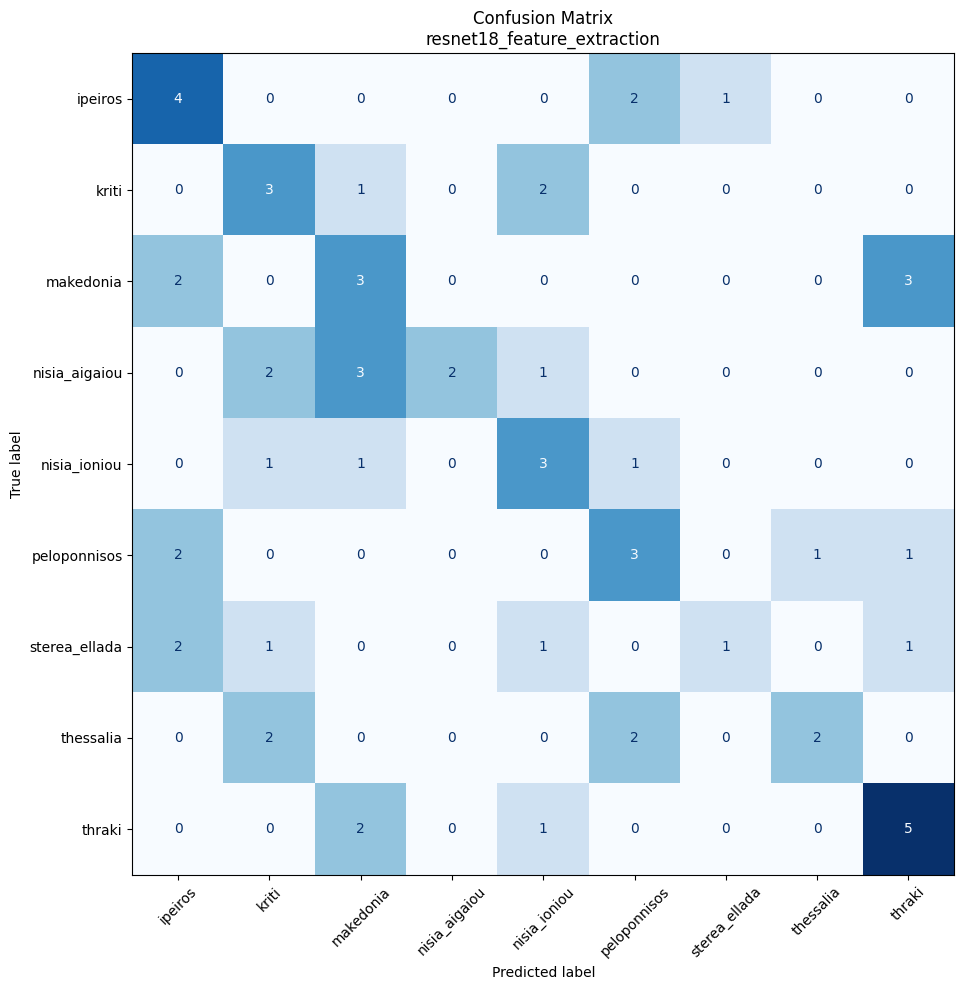


Αποθηκεύτηκαν:
Metrics              : /content/drive/MyDrive/ptyxiaki/results/resnet18_feature_extraction/test_metrics.json
Classification report: /content/drive/MyDrive/ptyxiaki/results/resnet18_feature_extraction/classification_report.json
Predictions          : /content/drive/MyDrive/ptyxiaki/results/resnet18_feature_extraction/test_predictions.npz
Confusion matrix     : /content/drive/MyDrive/ptyxiaki/results/resnet18_feature_extraction/confusion_matrix.png


In [14]:
# =============================================================================
# 7.8 ΤΕΛΙΚΗ ΑΞΙΟΛΟΓΗΣΗ ΣΤΟ TEST SET
# =============================================================================

test_metrics = evaluate_model_on_test_set(
    model=model,
    test_loader=test_loader,
    class_names=CLASS_NAMES,
    experiment_name=EXPERIMENT_NAME,
    results_dir=EXPERIMENT_RESULTS_DIR,
    save_results=True
)

In [15]:
# =============================================================================
# 7.9 ΑΠΟΘΗΚΕΥΣΗ ΤΟΥ ΤΕΛΙΚΟΥ ΜΟΝΤΕΛΟΥ
# =============================================================================

save_final_model(
    model=model,
    experiment_name=EXPERIMENT_NAME,
    model_path=FINAL_MODEL_PATH,
    test_metrics=test_metrics
)

✓ Το τελικό μοντέλο αποθηκεύτηκε επιτυχώς.
Model path: /content/drive/MyDrive/ptyxiaki/models/trained/resnet18_feature_extraction/resnet18_feature_extraction.pth


In [16]:
# =============================================================================
# 7.10 ΤΕΛΙΚΗ ΣΥΝΟΨΗ ΠΕΙΡΑΜΑΤΟΣ
# =============================================================================

parameter_counts = count_model_parameters(
    model
)


experiment_summary = {
    "experiment_name": EXPERIMENT_NAME,
    "model_architecture": MODEL_ARCHITECTURE,
    "transfer_learning_mode": TRANSFER_LEARNING_MODE,
    "learning_rate": EXPERIMENT_LEARNING_RATE,
    "weight_decay": EXPERIMENT_WEIGHT_DECAY,
    "batch_size": BATCH_SIZE,
    "maximum_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "epochs_completed": training_information["epochs_completed"],
    "best_epoch": training_information["best_epoch"],
    "best_validation_loss": training_information[
        "best_validation_loss"
    ],
    "best_validation_accuracy": training_information[
        "best_validation_accuracy"
    ],
    "training_time_seconds": training_information[
        "training_time_seconds"
    ],
    "total_parameters": parameter_counts[
        "total_parameters"
    ],
    "trainable_parameters": parameter_counts[
        "trainable_parameters"
    ],
    "frozen_parameters": parameter_counts[
        "frozen_parameters"
    ],
    "test_metrics": test_metrics,
    "best_checkpoint_path": str(
        BEST_CHECKPOINT_PATH
    ),
    "final_model_path": str(
        FINAL_MODEL_PATH
    )
}


EXPERIMENT_SUMMARY_PATH = (
    EXPERIMENT_RESULTS_DIR
    / "experiment_summary.json"
)


save_json_file(
    data=experiment_summary,
    file_path=EXPERIMENT_SUMMARY_PATH
)


print("=" * 75)
print("ΠΕΙΡΑΜΑ 1 — ΤΕΛΙΚΗ ΣΥΝΟΨΗ")
print("=" * 75)

print(f"Experiment             : {EXPERIMENT_NAME}")
print(f"Architecture           : {MODEL_ARCHITECTURE}")
print(f"Transfer learning      : {TRANSFER_LEARNING_MODE}")

print("\nTraining:")
print(
    f"Epochs completed       : "
    f"{training_information['epochs_completed']}"
)
print(
    f"Best epoch             : "
    f"{training_information['best_epoch']}"
)
print(
    f"Best validation loss   : "
    f"{training_information['best_validation_loss']:.4f}"
)
print(
    f"Best validation acc.   : "
    f"{training_information['best_validation_accuracy']:.4f}"
)
print(
    f"Training time          : "
    f"{training_information['training_time_seconds']:.2f} seconds"
)

print("\nParameters:")
print(
    f"Total parameters       : "
    f"{parameter_counts['total_parameters']:,}"
)
print(
    f"Trainable parameters   : "
    f"{parameter_counts['trainable_parameters']:,}"
)
print(
    f"Frozen parameters      : "
    f"{parameter_counts['frozen_parameters']:,}"
)

print("\nTest results:")
print(
    f"Accuracy               : "
    f"{test_metrics['accuracy']:.4f}"
)
print(
    f"Macro Precision        : "
    f"{test_metrics['macro_precision']:.4f}"
)
print(
    f"Macro Recall           : "
    f"{test_metrics['macro_recall']:.4f}"
)
print(
    f"Macro F1-score         : "
    f"{test_metrics['macro_f1']:.4f}"
)
print(
    f"Weighted F1-score      : "
    f"{test_metrics['weighted_f1']:.4f}"
)

print("\nSaved files:")
print(f"Best checkpoint        : {BEST_CHECKPOINT_PATH}")
print(f"Final model            : {FINAL_MODEL_PATH}")
print(f"Experiment summary     : {EXPERIMENT_SUMMARY_PATH}")

print("\n" + "=" * 75)
print("Το Πείραμα 1 ολοκληρώθηκε επιτυχώς.")
print("=" * 75)

ΠΕΙΡΑΜΑ 1 — ΤΕΛΙΚΗ ΣΥΝΟΨΗ
Experiment             : resnet18_feature_extraction
Architecture           : ResNet18
Transfer learning      : Feature Extraction

Training:
Epochs completed       : 25
Best epoch             : 25
Best validation loss   : 1.4273
Best validation acc.   : 0.4762
Training time          : 244.47 seconds

Parameters:
Total parameters       : 11,181,129
Trainable parameters   : 4,617
Frozen parameters      : 11,176,512

Test results:
Accuracy               : 0.4194
Macro Precision        : 0.4944
Macro Recall           : 0.4167
Macro F1-score         : 0.4092
Weighted F1-score      : 0.4120

Saved files:
Best checkpoint        : /content/drive/MyDrive/ptyxiaki/models/checkpoints/resnet18_feature_extraction/best_checkpoint.pth
Final model            : /content/drive/MyDrive/ptyxiaki/models/trained/resnet18_feature_extraction/resnet18_feature_extraction.pth
Experiment summary     : /content/drive/MyDrive/ptyxiaki/results/resnet18_feature_extraction/experiment_summary


# ΠΕΙΡΑΜΑ 2 — ResNet18 Partial Fine-Tuning


Στο δεύτερο πείραμα εφαρμόζεται **μερικό Fine-Tuning (Partial Fine-Tuning)** στο
προεκπαιδευμένο μοντέλο **ResNet18**.

Σε αντίθεση με το πρώτο πείραμα, όπου εκπαιδεύτηκε αποκλειστικά το τελικό
πλήρως συνδεδεμένο επίπεδο (Feature Extraction), στο παρόν πείραμα
ξεπαγώνει και εκπαιδεύεται επιπλέον το τελευταίο residual block (`layer4`)
του δικτύου.

Η προσέγγιση αυτή επιτρέπει στο μοντέλο να προσαρμόσει τα υψηλού επιπέδου
χαρακτηριστικά του στις ιδιαιτερότητες των ελληνικών παραδοσιακών φορεσιών,
διατηρώντας παράλληλα τα γενικά χαρακτηριστικά εικόνας που έχουν ήδη
μαθευτεί από το ImageNet.

Η συγκεκριμένη στρατηγική αποτελεί μία από τις πιο διαδεδομένες πρακτικές
Transfer Learning για μικρά σύνολα δεδομένων, καθώς συνδυάζει υψηλή
απόδοση με περιορισμένο κίνδυνο υπερπροσαρμογής.

In [17]:
# =============================================================================
# 8.2 ΡΥΘΜΙΣΕΙΣ ΠΕΙΡΑΜΑΤΟΣ
# =============================================================================

EXPERIMENT_NAME = "resnet18_partial_fine_tuning"

MODEL_ARCHITECTURE = "ResNet18"

TRANSFER_LEARNING_MODE = "Partial Fine-Tuning (layer4 + fc)"

LEARNING_RATE = 1e-4

WEIGHT_DECAY = DEFAULT_WEIGHT_DECAY


# -----------------------------------------------------------------------------
# Δημιουργία φακέλων του πειράματος
# -----------------------------------------------------------------------------

experiment_directories = create_experiment_directories(
    EXPERIMENT_NAME
)

EXPERIMENT_RESULTS_DIR = (
    experiment_directories["results_dir"]
)

EXPERIMENT_CHECKPOINT_DIR = (
    experiment_directories["checkpoint_dir"]
)

EXPERIMENT_TRAINED_MODEL_DIR = (
    experiment_directories["trained_model_dir"]
)


# -----------------------------------------------------------------------------
# Διαδρομές αρχείων
# -----------------------------------------------------------------------------

BEST_CHECKPOINT_PATH = (
    EXPERIMENT_CHECKPOINT_DIR
    / "best_checkpoint.pth"
)

FINAL_MODEL_PATH = (
    EXPERIMENT_TRAINED_MODEL_DIR
    / f"{EXPERIMENT_NAME}.pth"
)

EXPERIMENT_SUMMARY_PATH = (
    EXPERIMENT_RESULTS_DIR
    / "experiment_summary.json"
)


# -----------------------------------------------------------------------------
# Εμφάνιση ρυθμίσεων
# -----------------------------------------------------------------------------

print("=" * 70)
print("ΠΕΙΡΑΜΑ 2 — RESNET18 PARTIAL FINE-TUNING")
print("=" * 70)

print(f"Experiment name       : {EXPERIMENT_NAME}")
print(f"Model architecture    : {MODEL_ARCHITECTURE}")
print(f"Transfer learning     : {TRANSFER_LEARNING_MODE}")
print(f"Learning rate         : {LEARNING_RATE}")
print(f"Weight decay          : {WEIGHT_DECAY}")
print(f"Maximum epochs        : {MAX_EPOCHS}")
print(f"Early stopping        : {EARLY_STOPPING_PATIENCE}")

print("\nDirectories:")
print(f"Results               : {EXPERIMENT_RESULTS_DIR}")
print(f"Checkpoints           : {EXPERIMENT_CHECKPOINT_DIR}")
print(f"Trained models        : {EXPERIMENT_TRAINED_MODEL_DIR}")

print("\nFiles:")
print(f"Best checkpoint       : {BEST_CHECKPOINT_PATH}")
print(f"Final model           : {FINAL_MODEL_PATH}")
print(f"Experiment summary    : {EXPERIMENT_SUMMARY_PATH}")

ΠΕΙΡΑΜΑ 2 — RESNET18 PARTIAL FINE-TUNING
Experiment name       : resnet18_partial_fine_tuning
Model architecture    : ResNet18
Transfer learning     : Partial Fine-Tuning (layer4 + fc)
Learning rate         : 0.0001
Weight decay          : 0.0001
Maximum epochs        : 25
Early stopping        : 5

Directories:
Results               : /content/drive/MyDrive/ptyxiaki/results/resnet18_partial_fine_tuning
Checkpoints           : /content/drive/MyDrive/ptyxiaki/models/checkpoints/resnet18_partial_fine_tuning
Trained models        : /content/drive/MyDrive/ptyxiaki/models/trained/resnet18_partial_fine_tuning

Files:
Best checkpoint       : /content/drive/MyDrive/ptyxiaki/models/checkpoints/resnet18_partial_fine_tuning/best_checkpoint.pth
Final model           : /content/drive/MyDrive/ptyxiaki/models/trained/resnet18_partial_fine_tuning/resnet18_partial_fine_tuning.pth
Experiment summary    : /content/drive/MyDrive/ptyxiaki/results/resnet18_partial_fine_tuning/experiment_summary.json


In [18]:
# =============================================================================
# 8.3 ΔΗΜΙΟΥΡΓΙΑ ΜΟΝΤΕΛΟΥ
# =============================================================================

import torch.nn as nn

from torchvision.models import (
    resnet18,
    ResNet18_Weights
)


# -----------------------------------------------------------------------------
# Φόρτωση προεκπαιδευμένου ResNet18
# -----------------------------------------------------------------------------

model = resnet18(
    weights=ResNet18_Weights.DEFAULT
)


# -----------------------------------------------------------------------------
# Πάγωμα όλων των παραμέτρων του δικτύου
# -----------------------------------------------------------------------------

for parameter in model.parameters():
    parameter.requires_grad = False


# -----------------------------------------------------------------------------
# Ξεπάγωμα του τελευταίου residual block
# -----------------------------------------------------------------------------

for parameter in model.layer4.parameters():
    parameter.requires_grad = True


# -----------------------------------------------------------------------------
# Αντικατάσταση του τελικού classifier
# -----------------------------------------------------------------------------

classifier_input_features = (
    model.fc.in_features
)

model.fc = nn.Linear(
    in_features=classifier_input_features,
    out_features=NUM_CLASSES
)


# -----------------------------------------------------------------------------
# Μεταφορά του μοντέλου στη διαθέσιμη συσκευή
# -----------------------------------------------------------------------------

model = model.to(
    DEVICE
)


# -----------------------------------------------------------------------------
# Έλεγχος της εξόδου του μοντέλου
# -----------------------------------------------------------------------------

validate_model_output(
    model=model,
    batch_size=BATCH_SIZE
)


# -----------------------------------------------------------------------------
# Εμφάνιση σύνοψης μοντέλου
# -----------------------------------------------------------------------------

print_model_summary(
    model=model,
    experiment_name=EXPERIMENT_NAME,
    transfer_learning_mode=TRANSFER_LEARNING_MODE
)


Model output check:
Output tensor shape        : torch.Size([16, 9])
✓ Η έξοδος του μοντέλου έχει το σωστό σχήμα.
ΣΥΝΟΨΗ ΜΟΝΤΕΛΟΥ
Experiment name            : resnet18_partial_fine_tuning
Model class                : ResNet
Transfer learning mode     : Partial Fine-Tuning (layer4 + fc)
Number of classes          : 9
Running on                 : cuda

Parameters:
Total parameters          : 11,181,129
Trainable parameters      : 8,398,345
Frozen parameters         : 2,782,784


In [19]:
# =============================================================================
# 8.4 LOSS FUNCTION ΚΑΙ OPTIMIZER
# =============================================================================

import torch.optim as optim


# -----------------------------------------------------------------------------
# Συνάρτηση κόστους
# -----------------------------------------------------------------------------

criterion = nn.CrossEntropyLoss()


# -----------------------------------------------------------------------------
# Επιλογή μόνο των εκπαιδεύσιμων παραμέτρων
# -----------------------------------------------------------------------------

trainable_parameters = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]


# -----------------------------------------------------------------------------
# Optimizer
# -----------------------------------------------------------------------------

optimizer = optim.Adam(
    trainable_parameters,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# -----------------------------------------------------------------------------
# Επιβεβαίωση ρυθμίσεων
# -----------------------------------------------------------------------------

number_of_trainable_tensors = len(
    trainable_parameters
)

number_of_trainable_parameters = sum(
    parameter.numel()
    for parameter in trainable_parameters
)

print("=" * 70)
print("LOSS FUNCTION ΚΑΙ OPTIMIZER")
print("=" * 70)

print(f"Criterion                  : {criterion.__class__.__name__}")
print(f"Optimizer                  : {optimizer.__class__.__name__}")
print(f"Learning rate              : {LEARNING_RATE}")
print(f"Weight decay               : {WEIGHT_DECAY}")
print(f"Trainable tensors          : {number_of_trainable_tensors}")
print(
    f"Trainable parameters       : "
    f"{number_of_trainable_parameters:,}"
)

LOSS FUNCTION ΚΑΙ OPTIMIZER
Criterion                  : CrossEntropyLoss
Optimizer                  : Adam
Learning rate              : 0.0001
Weight decay               : 0.0001
Trainable tensors          : 17
Trainable parameters       : 8,398,345


In [20]:
# =============================================================================
# 8.5 ΕΚΠΑΙΔΕΥΣΗ ΜΟΝΤΕΛΟΥ
# =============================================================================

model, training_history, training_information = train_model(
    model=model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    criterion=criterion,
    optimizer=optimizer,
    experiment_name=EXPERIMENT_NAME,
    checkpoint_path=BEST_CHECKPOINT_PATH,
    max_epochs=MAX_EPOCHS,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    scheduler=None
)

ΕΝΑΡΞΗ ΕΚΠΑΙΔΕΥΣΗΣ — resnet18_partial_fine_tuning

Epoch [1/25]
Learning Rate       : 0.00010000
Train Loss          : 2.0324
Validation Loss     : 1.8193
Train Accuracy      : 0.2552
Validation Accuracy : 0.4127
Epoch Time          : 7.04 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [2/25]
Learning Rate       : 0.00010000
Train Loss          : 1.1575
Validation Loss     : 1.5918
Train Accuracy      : 0.7168
Validation Accuracy : 0.5079
Epoch Time          : 3.96 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [3/25]
Learning Rate       : 0.00010000
Train Loss          : 0.7630
Validation Loss     : 1.4429
Train Accuracy      : 0.8427
Validation Accuracy : 0.5238
Epoch Time          : 4.02 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [4/25]
Learning Rate       : 0.00010000
Train Loss          : 0.5199
Validation Loss     : 1.3158
Train Accuracy      : 0.9196
Validation Accuracy : 0.5556
Epoch Time          : 6.04 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [5/

In [21]:
# =============================================================================
# 8.6 ΑΠΟΘΗΚΕΥΣΗ ΑΠΟΤΕΛΕΣΜΑΤΩΝ ΕΚΠΑΙΔΕΥΣΗΣ
# =============================================================================

save_training_results(
    history=training_history,
    training_information=training_information,
    results_dir=EXPERIMENT_RESULTS_DIR
)

✓ Αποθηκεύτηκαν τα αποτελέσματα εκπαίδευσης.
Training history     : /content/drive/MyDrive/ptyxiaki/results/resnet18_partial_fine_tuning/training_history.json
Training information : /content/drive/MyDrive/ptyxiaki/results/resnet18_partial_fine_tuning/training_information.json


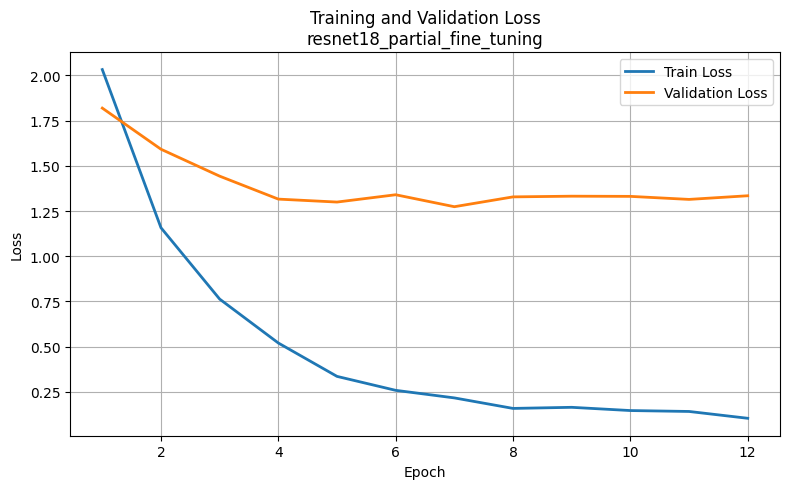

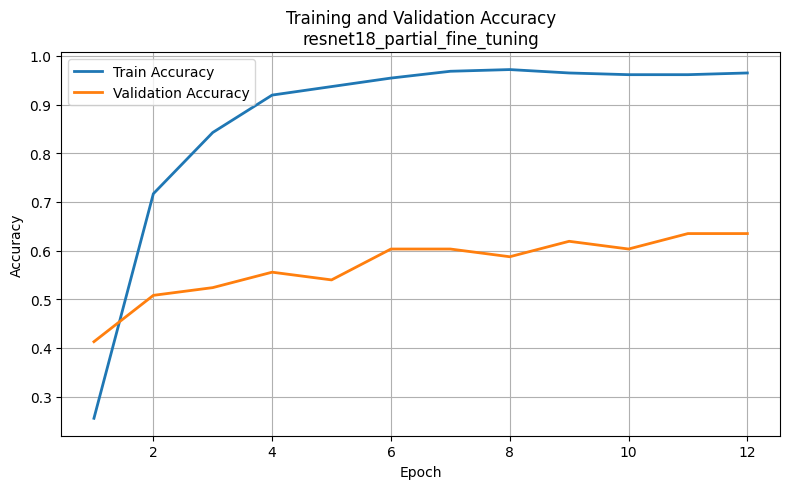

✓ Τα διαγράμματα εκπαίδευσης δημιουργήθηκαν επιτυχώς.


In [22]:
# =============================================================================
# 8.7 ΔΙΑΓΡΑΜΜΑΤΑ ΕΚΠΑΙΔΕΥΣΗΣ
# =============================================================================

plot_training_history(
    history=training_history,
    experiment_name=EXPERIMENT_NAME,
    results_dir=EXPERIMENT_RESULTS_DIR,
    save_plots=True
)

In [23]:
# =============================================================================
# 8.8 ΦΟΡΤΩΣΗ ΤΟΥ ΚΑΛΥΤΕΡΟΥ CHECKPOINT
# =============================================================================

if not BEST_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        "Δεν βρέθηκε το καλύτερο checkpoint στη διαδρομή:\n"
        f"{BEST_CHECKPOINT_PATH}"
    )


checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)


required_checkpoint_keys = [
    "experiment_name",
    "epoch",
    "model_state_dict",
    "validation_loss",
    "validation_accuracy",
    "class_names",
    "class_to_idx",
    "image_size"
]


for key in required_checkpoint_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Το checkpoint δεν περιέχει το απαιτούμενο πεδίο '{key}'."
        )


model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(
    DEVICE
)

model.eval()


print("=" * 70)
print("ΦΟΡΤΩΣΗ ΚΑΛΥΤΕΡΟΥ CHECKPOINT")
print("=" * 70)

print(f"Checkpoint path          : {BEST_CHECKPOINT_PATH}")
print(f"Experiment               : {checkpoint['experiment_name']}")
print(f"Best epoch               : {checkpoint['epoch']}")
print(
    f"Validation loss          : "
    f"{checkpoint['validation_loss']:.4f}"
)
print(
    f"Validation accuracy      : "
    f"{checkpoint['validation_accuracy']:.4f}"
)

print("\n✓ Το καλύτερο checkpoint φορτώθηκε επιτυχώς.")

ΦΟΡΤΩΣΗ ΚΑΛΥΤΕΡΟΥ CHECKPOINT
Checkpoint path          : /content/drive/MyDrive/ptyxiaki/models/checkpoints/resnet18_partial_fine_tuning/best_checkpoint.pth
Experiment               : resnet18_partial_fine_tuning
Best epoch               : 7
Validation loss          : 1.2738
Validation accuracy      : 0.6032

✓ Το καλύτερο checkpoint φορτώθηκε επιτυχώς.


TEST SET RESULTS — resnet18_partial_fine_tuning
Accuracy          : 0.5484
Top-3 Accuracy    : 0.8710
Macro Precision   : 0.5765
Macro Recall      : 0.5397
Macro F1-score    : 0.5402
Weighted F1-score : 0.5462

CLASSIFICATION REPORT
               precision    recall  f1-score   support

      ipeiros     0.3636    0.5714    0.4444         7
        kriti     0.7500    0.5000    0.6000         6
    makedonia     0.5000    0.5000    0.5000         8
nisia_aigaiou     0.8333    0.6250    0.7143         8
 nisia_ioniou     0.6250    0.8333    0.7143         6
 peloponnisos     0.2500    0.2857    0.2667         7
sterea_ellada     0.5000    0.3333    0.4000         6
    thessalia     0.6667    0.3333    0.4444         6
       thraki     0.7000    0.8750    0.7778         8

     accuracy                         0.5484        62
    macro avg     0.5765    0.5397    0.5402        62
 weighted avg     0.5776    0.5484    0.5462        62



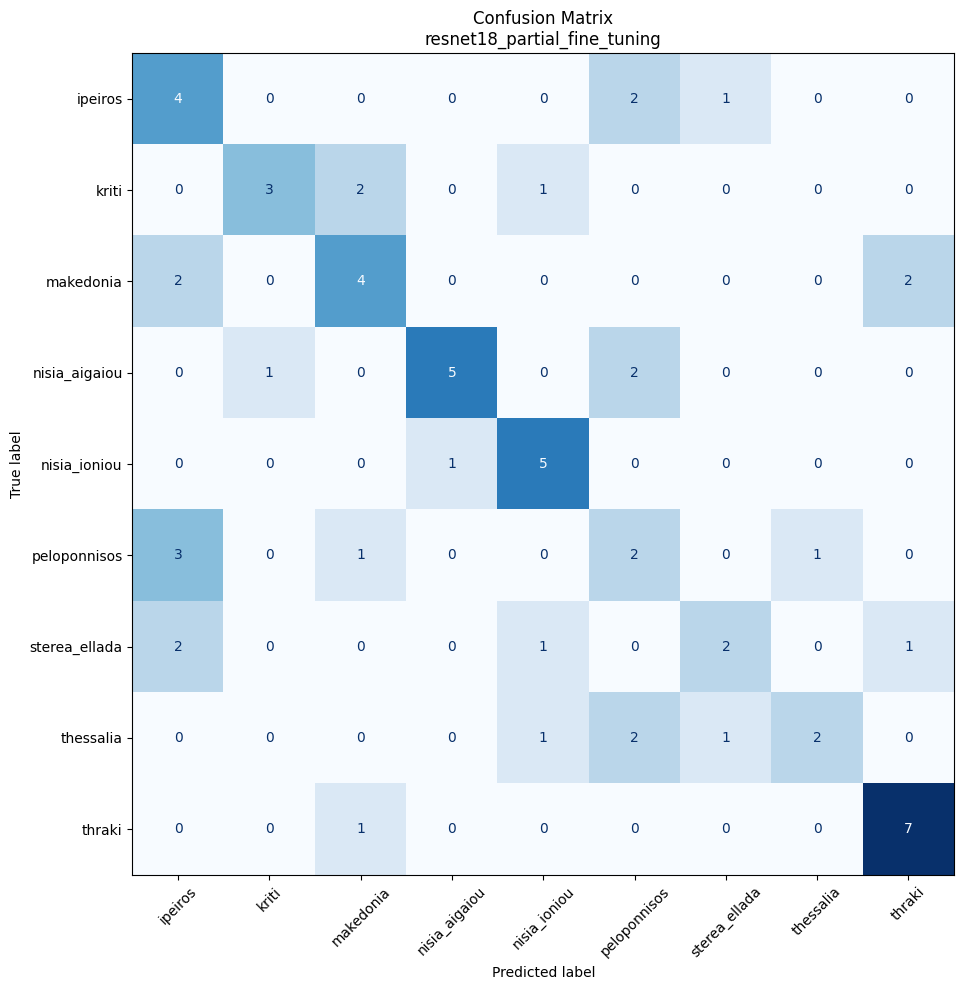


Αποθηκεύτηκαν:
Metrics              : /content/drive/MyDrive/ptyxiaki/results/resnet18_partial_fine_tuning/test_metrics.json
Classification report: /content/drive/MyDrive/ptyxiaki/results/resnet18_partial_fine_tuning/classification_report.json
Predictions          : /content/drive/MyDrive/ptyxiaki/results/resnet18_partial_fine_tuning/test_predictions.npz
Confusion matrix     : /content/drive/MyDrive/ptyxiaki/results/resnet18_partial_fine_tuning/confusion_matrix.png


In [24]:
# =============================================================================
# 8.9 ΑΞΙΟΛΟΓΗΣΗ ΣΤΟ TEST SET
# =============================================================================

test_metrics = evaluate_model_on_test_set(
    model=model,
    test_loader=test_loader,
    class_names=CLASS_NAMES,
    experiment_name=EXPERIMENT_NAME,
    results_dir=EXPERIMENT_RESULTS_DIR,
    save_results=True
)

In [25]:
# =============================================================================
# 8.10 ΑΠΟΘΗΚΕΥΣΗ ΤΕΛΙΚΟΥ ΜΟΝΤΕΛΟΥ
# =============================================================================

save_final_model(
    model=model,
    experiment_name=EXPERIMENT_NAME,
    model_path=FINAL_MODEL_PATH,
    test_metrics=test_metrics
)

✓ Το τελικό μοντέλο αποθηκεύτηκε επιτυχώς.
Model path: /content/drive/MyDrive/ptyxiaki/models/trained/resnet18_partial_fine_tuning/resnet18_partial_fine_tuning.pth


In [26]:
# =============================================================================
# 8.11 ΤΕΛΙΚΗ ΣΥΝΟΨΗ ΠΕΙΡΑΜΑΤΟΣ
# =============================================================================

parameter_counts = count_model_parameters(
    model
)


experiment_summary = {
    "experiment_name": EXPERIMENT_NAME,
    "model_architecture": MODEL_ARCHITECTURE,
    "transfer_learning_mode": TRANSFER_LEARNING_MODE,

    "dataset": {
        "number_of_classes": int(NUM_CLASSES),
        "class_names": list(CLASS_NAMES),
        "image_size": int(IMAGE_SIZE),
        "batch_size": int(BATCH_SIZE)
    },

    "hyperparameters": {
        "learning_rate": float(LEARNING_RATE),
        "weight_decay": float(WEIGHT_DECAY),
        "maximum_epochs": int(MAX_EPOCHS),
        "early_stopping_patience": int(
            EARLY_STOPPING_PATIENCE
        ),
        "optimizer": optimizer.__class__.__name__,
        "criterion": criterion.__class__.__name__
    },

    "parameters": {
        "total_parameters": int(
            parameter_counts["total_parameters"]
        ),
        "trainable_parameters": int(
            parameter_counts["trainable_parameters"]
        ),
        "frozen_parameters": int(
            parameter_counts["frozen_parameters"]
        )
    },

    "training": {
        "training_time_seconds": float(
            training_information["training_time_seconds"]
        ),
        "epochs_completed": int(
            training_information["epochs_completed"]
        ),
        "best_epoch": int(
            training_information["best_epoch"]
        ),
        "best_validation_loss": float(
            training_information["best_validation_loss"]
        ),
        "best_validation_accuracy": float(
            training_information["best_validation_accuracy"]
        )
    },

    "test_metrics": {
        "accuracy": float(
            test_metrics["accuracy"]
        ),
        "macro_precision": float(
            test_metrics["macro_precision"]
        ),
        "macro_recall": float(
            test_metrics["macro_recall"]
        ),
        "macro_f1": float(
            test_metrics["macro_f1"]
        ),
        "weighted_f1": float(
            test_metrics["weighted_f1"]
        )
    },

    "saved_files": {
        "best_checkpoint": str(
            BEST_CHECKPOINT_PATH
        ),
        "final_model": str(
            FINAL_MODEL_PATH
        ),
        "results_directory": str(
            EXPERIMENT_RESULTS_DIR
        )
    }
}


save_json_file(
    data=experiment_summary,
    file_path=EXPERIMENT_SUMMARY_PATH
)


print("=" * 80)
print("ΤΕΛΙΚΗ ΣΥΝΟΨΗ — ΠΕΙΡΑΜΑ 2")
print("=" * 80)

print(f"Experiment                  : {EXPERIMENT_NAME}")
print(f"Architecture                : {MODEL_ARCHITECTURE}")
print(f"Transfer learning           : {TRANSFER_LEARNING_MODE}")

print("\nModel parameters:")
print(
    f"Total parameters            : "
    f"{parameter_counts['total_parameters']:,}"
)
print(
    f"Trainable parameters        : "
    f"{parameter_counts['trainable_parameters']:,}"
)
print(
    f"Frozen parameters           : "
    f"{parameter_counts['frozen_parameters']:,}"
)

print("\nTraining:")
print(
    f"Epochs completed            : "
    f"{training_information['epochs_completed']}"
)
print(
    f"Best epoch                  : "
    f"{training_information['best_epoch']}"
)
print(
    f"Best validation loss        : "
    f"{training_information['best_validation_loss']:.4f}"
)
print(
    f"Best validation accuracy    : "
    f"{training_information['best_validation_accuracy']:.4f}"
)
print(
    f"Training time               : "
    f"{training_information['training_time_seconds']:.2f} seconds"
)

print("\nTest set:")
print(
    f"Accuracy                    : "
    f"{test_metrics['accuracy']:.4f}"
)
print(
    f"Macro Precision             : "
    f"{test_metrics['macro_precision']:.4f}"
)
print(
    f"Macro Recall                : "
    f"{test_metrics['macro_recall']:.4f}"
)
print(
    f"Macro F1-score              : "
    f"{test_metrics['macro_f1']:.4f}"
)
print(
    f"Weighted F1-score           : "
    f"{test_metrics['weighted_f1']:.4f}"
)

print("\nSaved files:")
print(f"Best checkpoint             : {BEST_CHECKPOINT_PATH}")
print(f"Final model                 : {FINAL_MODEL_PATH}")
print(f"Experiment summary          : {EXPERIMENT_SUMMARY_PATH}")

print("\n" + "=" * 80)
print("✓ ΤΟ ΠΕΙΡΑΜΑ 2 ΟΛΟΚΛΗΡΩΘΗΚΕ ΕΠΙΤΥΧΩΣ")
print("=" * 80)

ΤΕΛΙΚΗ ΣΥΝΟΨΗ — ΠΕΙΡΑΜΑ 2
Experiment                  : resnet18_partial_fine_tuning
Architecture                : ResNet18
Transfer learning           : Partial Fine-Tuning (layer4 + fc)

Model parameters:
Total parameters            : 11,181,129
Trainable parameters        : 8,398,345
Frozen parameters           : 2,782,784

Training:
Epochs completed            : 12
Best epoch                  : 7
Best validation loss        : 1.2738
Best validation accuracy    : 0.6032
Training time               : 79.12 seconds

Test set:
Accuracy                    : 0.5484
Macro Precision             : 0.5765
Macro Recall                : 0.5397
Macro F1-score              : 0.5402
Weighted F1-score           : 0.5462

Saved files:
Best checkpoint             : /content/drive/MyDrive/ptyxiaki/models/checkpoints/resnet18_partial_fine_tuning/best_checkpoint.pth
Final model                 : /content/drive/MyDrive/ptyxiaki/models/trained/resnet18_partial_fine_tuning/resnet18_partial_fine_tuning.pth

# ΠΕΙΡΑΜΑ 3: EfficientNet-B0 Feature Extraction

Στο τρίτο πείραμα αξιοποιείται το προεκπαιδευμένο συνελικτικό νευρωνικό
δίκτυο EfficientNet-B0 με τη μέθοδο του Feature Extraction.

Όλες οι παράμετροι του προεκπαιδευμένου τμήματος του δικτύου παραμένουν
παγωμένες και εκπαιδεύεται αποκλειστικά το τελικό επίπεδο ταξινόμησης.
Το αρχικό επίπεδο ταξινόμησης αντικαθίσταται από ένα νέο πλήρως συνδεδεμένο
επίπεδο με αριθμό εξόδων ίσο με τις εννέα κατηγορίες του συνόλου δεδομένων.

Η συγκεκριμένη προσέγγιση επιτρέπει την αξιοποίηση των χαρακτηριστικών που
έχει ήδη μάθει το EfficientNet-B0 από το ImageNet, περιορίζοντας παράλληλα
τον αριθμό των εκπαιδεύσιμων παραμέτρων και τον απαιτούμενο χρόνο εκπαίδευσης.

In [27]:
# =============================================================================
# 9.2 ΡΥΘΜΙΣΕΙΣ ΠΕΙΡΑΜΑΤΟΣ ΚΑΙ ΔΗΜΙΟΥΡΓΙΑ ΦΑΚΕΛΩΝ
# =============================================================================

EXPERIMENT_NAME = "efficientnet_b0_feature_extraction"
MODEL_NAME = "EfficientNet-B0"
TRANSFER_LEARNING_MODE = "Feature Extraction"

LEARNING_RATE = DEFAULT_LEARNING_RATE
WEIGHT_DECAY = DEFAULT_WEIGHT_DECAY

# Δημιουργία των φακέλων αποθήκευσης του πειράματος
experiment_paths = create_experiment_directories(
    EXPERIMENT_NAME
)

EXPERIMENT_RESULTS_DIR = (
    experiment_paths["results_dir"]
)

EXPERIMENT_CHECKPOINT_DIR = (
    experiment_paths["checkpoint_dir"]
)

EXPERIMENT_TRAINED_MODEL_DIR = (
    experiment_paths["trained_model_dir"]
)

print("=" * 70)
print("ΡΥΘΜΙΣΕΙΣ ΠΕΙΡΑΜΑΤΟΣ 3")
print("=" * 70)

print(f"Experiment name       : {EXPERIMENT_NAME}")
print(f"Model                 : {MODEL_NAME}")
print(f"Transfer learning     : {TRANSFER_LEARNING_MODE}")
print(f"Number of classes     : {NUM_CLASSES}")
print(f"Batch size            : {BATCH_SIZE}")
print(f"Maximum epochs        : {MAX_EPOCHS}")
print(f"Early stopping        : {EARLY_STOPPING_PATIENCE}")
print(f"Learning rate         : {LEARNING_RATE}")
print(f"Weight decay          : {WEIGHT_DECAY}")
print(f"Device                : {DEVICE}")

print("\nΦάκελοι πειράματος:")
print(f"Results               : {EXPERIMENT_RESULTS_DIR}")
print(f"Checkpoints           : {EXPERIMENT_CHECKPOINT_DIR}")
print(f"Trained model         : {EXPERIMENT_TRAINED_MODEL_DIR}")

print("\n" + "=" * 70)
print("Οι ρυθμίσεις του Πειράματος 3 ορίστηκαν επιτυχώς.")
print("=" * 70)

ΡΥΘΜΙΣΕΙΣ ΠΕΙΡΑΜΑΤΟΣ 3
Experiment name       : efficientnet_b0_feature_extraction
Model                 : EfficientNet-B0
Transfer learning     : Feature Extraction
Number of classes     : 9
Batch size            : 16
Maximum epochs        : 25
Early stopping        : 5
Learning rate         : 0.001
Weight decay          : 0.0001
Device                : cuda

Φάκελοι πειράματος:
Results               : /content/drive/MyDrive/ptyxiaki/results/efficientnet_b0_feature_extraction
Checkpoints           : /content/drive/MyDrive/ptyxiaki/models/checkpoints/efficientnet_b0_feature_extraction
Trained model         : /content/drive/MyDrive/ptyxiaki/models/trained/efficientnet_b0_feature_extraction

Οι ρυθμίσεις του Πειράματος 3 ορίστηκαν επιτυχώς.


## Δημιουργία του μοντέλου EfficientNet-B0

Φορτώνεται το EfficientNet-B0 με προεκπαιδευμένα βάρη από το ImageNet.

Αρχικά παγώνουν όλες οι παράμετροι του προεκπαιδευμένου μοντέλου, ώστε να
μη μεταβάλλονται κατά τη διάρκεια της εκπαίδευσης.

Στη συνέχεια, το αρχικό τελικό επίπεδο ταξινόμησης αντικαθίσταται από νέο
γραμμικό επίπεδο με εννέα εξόδους. Επομένως, μόνο το νέο επίπεδο
ταξινόμησης παραμένει εκπαιδεύσιμο.

In [28]:
# =============================================================================
# 9.3 ΔΗΜΙΟΥΡΓΙΑ ΜΟΝΤΕΛΟΥ EFFICIENTNET-B0
# =============================================================================

import torch.nn as nn

from torchvision.models import (
    EfficientNet_B0_Weights,
    efficientnet_b0
)

# Επιλογή των προεκπαιδευμένων βαρών
efficientnet_weights = EfficientNet_B0_Weights.DEFAULT

# Φόρτωση του προεκπαιδευμένου μοντέλου
model = efficientnet_b0(
    weights=efficientnet_weights
)

# Πάγωμα όλων των προεκπαιδευμένων παραμέτρων
for parameter in model.parameters():
    parameter.requires_grad = False

# Αριθμός εισόδων του αρχικού classification layer
classifier_input_features = model.classifier[1].in_features

# Αντικατάσταση του τελικού classification layer
model.classifier[1] = nn.Linear(
    in_features=classifier_input_features,
    out_features=NUM_CLASSES
)

# Μεταφορά του μοντέλου στη διαθέσιμη συσκευή
model = model.to(DEVICE)

print("=" * 70)
print("ΔΗΜΙΟΥΡΓΙΑ ΜΟΝΤΕΛΟΥ")
print("=" * 70)

print(f"Model                  : {MODEL_NAME}")
print(f"Pretrained weights     : {efficientnet_weights}")
print(f"Classifier input size  : {classifier_input_features}")
print(f"Classifier output size : {NUM_CLASSES}")
print(f"Device                 : {DEVICE}")

print("\nΤο μοντέλο EfficientNet-B0 δημιουργήθηκε επιτυχώς.")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 185MB/s]

ΔΗΜΙΟΥΡΓΙΑ ΜΟΝΤΕΛΟΥ
Model                  : EfficientNet-B0
Pretrained weights     : EfficientNet_B0_Weights.IMAGENET1K_V1
Classifier input size  : 1280
Classifier output size : 9
Device                 : cuda

Το μοντέλο EfficientNet-B0 δημιουργήθηκε επιτυχώς.


In [29]:
# =============================================================================
# 9.4 ΕΛΕΓΧΟΣ ΕΚΠΑΙΔΕΥΣΙΜΩΝ ΠΑΡΑΜΕΤΡΩΝ
# =============================================================================

print("=" * 70)
print("ΕΚΠΑΙΔΕΥΣΙΜΕΣ ΠΑΡΑΜΕΤΡΟΙ")
print("=" * 70)

trainable_layer_names = []

for parameter_name, parameter in model.named_parameters():
    if parameter.requires_grad:
        trainable_layer_names.append(parameter_name)
        print(parameter_name)

print("\nΣυνολικό πλήθος εκπαιδεύσιμων tensors:")
print(len(trainable_layer_names))

ΕΚΠΑΙΔΕΥΣΙΜΕΣ ΠΑΡΑΜΕΤΡΟΙ
classifier.1.weight
classifier.1.bias

Συνολικό πλήθος εκπαιδεύσιμων tensors:
2


## Σύνοψη του μοντέλου

Στην ακόλουθη σύνοψη παρουσιάζεται ο συνολικός αριθμός παραμέτρων του
EfficientNet-B0, καθώς και ο διαχωρισμός τους σε εκπαιδεύσιμες και παγωμένες
παραμέτρους.

In [30]:
# =============================================================================
# 9.5 ΣΥΝΟΨΗ ΜΟΝΤΕΛΟΥ
# =============================================================================

model_parameters = print_model_summary(
    model,
    EXPERIMENT_NAME,
    TRANSFER_LEARNING_MODE
)

ΣΥΝΟΨΗ ΜΟΝΤΕΛΟΥ
Experiment name            : efficientnet_b0_feature_extraction
Model class                : EfficientNet
Transfer learning mode     : Feature Extraction
Number of classes          : 9
Running on                 : cuda

Parameters:
Total parameters          : 4,019,077
Trainable parameters      : 11,529
Frozen parameters         : 4,007,548


## Έλεγχος της εξόδου του μοντέλου

Πριν από την εκπαίδευση πραγματοποιείται δοκιμαστική προώθηση ενός εικονικού
batch εικόνων μέσα από το δίκτυο.

Με αυτόν τον τρόπο επιβεβαιώνεται ότι η έξοδος του μοντέλου έχει τις
αναμενόμενες διαστάσεις:

`[batch_size, number_of_classes]`.

In [31]:
# =============================================================================
# 9.6 ΕΛΕΓΧΟΣ ΕΞΟΔΟΥ ΜΟΝΤΕΛΟΥ
# =============================================================================

validate_model_output(
    model,
    batch_size=BATCH_SIZE
)


Model output check:
Output tensor shape        : torch.Size([16, 9])
✓ Η έξοδος του μοντέλου έχει το σωστό σχήμα.


## Συνάρτηση απώλειας και αλγόριθμος βελτιστοποίησης

Για την εκπαίδευση χρησιμοποιείται η συνάρτηση απώλειας Cross-Entropy Loss,
η οποία είναι κατάλληλη για προβλήματα πολυταξικής ταξινόμησης.

Ως αλγόριθμος βελτιστοποίησης χρησιμοποιείται ο Adam. Στον optimizer
περιλαμβάνονται αποκλειστικά οι παράμετροι που έχουν οριστεί ως
εκπαιδεύσιμες, δηλαδή οι παράμετροι του νέου τελικού επιπέδου ταξινόμησης.

In [32]:
# =============================================================================
# 9.7 ΣΥΝΑΡΤΗΣΗ ΑΠΩΛΕΙΑΣ ΚΑΙ OPTIMIZER
# =============================================================================

import torch.optim as optim

criterion = nn.CrossEntropyLoss()

trainable_parameters = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]

optimizer = optim.Adam(
    trainable_parameters,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("=" * 70)
print("ΡΥΘΜΙΣΕΙΣ ΕΚΠΑΙΔΕΥΣΗΣ")
print("=" * 70)

print(f"Loss function          : {criterion.__class__.__name__}")
print(f"Optimizer              : {optimizer.__class__.__name__}")
print(f"Learning rate          : {LEARNING_RATE}")
print(f"Weight decay           : {WEIGHT_DECAY}")
print(f"Trainable parameters   : {sum(p.numel() for p in trainable_parameters):,}")

ΡΥΘΜΙΣΕΙΣ ΕΚΠΑΙΔΕΥΣΗΣ
Loss function          : CrossEntropyLoss
Optimizer              : Adam
Learning rate          : 0.001
Weight decay           : 0.0001
Trainable parameters   : 11,529


##Εκπαίδευση του μοντέλου

Το EfficientNet-B0 εκπαιδεύεται χρησιμοποιώντας το training set, ενώ η
απόδοσή του παρακολουθείται στο validation set μετά από κάθε εποχή.

Η διαδικασία εκπαίδευσης περιλαμβάνει Early Stopping με βάση το validation
loss. Όταν δεν παρατηρείται βελτίωση για προκαθορισμένο αριθμό διαδοχικών
εποχών, η εκπαίδευση διακόπτεται αυτόματα.

Το καλύτερο μοντέλο αποθηκεύεται με βάση τη μικρότερη τιμή validation loss.

In [33]:
# =============================================================================
# 9.8 ΕΚΠΑΙΔΕΥΣΗ ΜΟΝΤΕΛΟΥ
# =============================================================================

checkpoint_path = (
    EXPERIMENT_CHECKPOINT_DIR
    / "best_model_checkpoint.pth"
)

model, history, training_information = train_model(
    model=model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    criterion=criterion,
    optimizer=optimizer,
    experiment_name=EXPERIMENT_NAME,
    checkpoint_path=checkpoint_path,
    max_epochs=MAX_EPOCHS,
    early_stopping_patience=EARLY_STOPPING_PATIENCE
)

ΕΝΑΡΞΗ ΕΚΠΑΙΔΕΥΣΗΣ — efficientnet_b0_feature_extraction

Epoch [1/25]
Learning Rate       : 0.00100000
Train Loss          : 2.1547
Validation Loss     : 2.0583
Train Accuracy      : 0.1783
Validation Accuracy : 0.2381
Epoch Time          : 6.03 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [2/25]
Learning Rate       : 0.00100000
Train Loss          : 1.9301
Validation Loss     : 1.9708
Train Accuracy      : 0.3566
Validation Accuracy : 0.2222
Epoch Time          : 3.89 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [3/25]
Learning Rate       : 0.00100000
Train Loss          : 1.7362
Validation Loss     : 1.9193
Train Accuracy      : 0.5140
Validation Accuracy : 0.2698
Epoch Time          : 4.26 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [4/25]
Learning Rate       : 0.00100000
Train Loss          : 1.6132
Validation Loss     : 1.8772
Train Accuracy      : 0.5315
Validation Accuracy : 0.2857
Epoch Time          : 5.10 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epo

##Οπτικοποίηση του ιστορικού εκπαίδευσης

Παρουσιάζονται οι καμπύλες της συνάρτησης απώλειας και της ακρίβειας για το
training και το validation set.

Τα διαγράμματα επιτρέπουν την παρακολούθηση της σύγκλισης του μοντέλου και
τον εντοπισμό πιθανών ενδείξεων υπερπροσαρμογής.

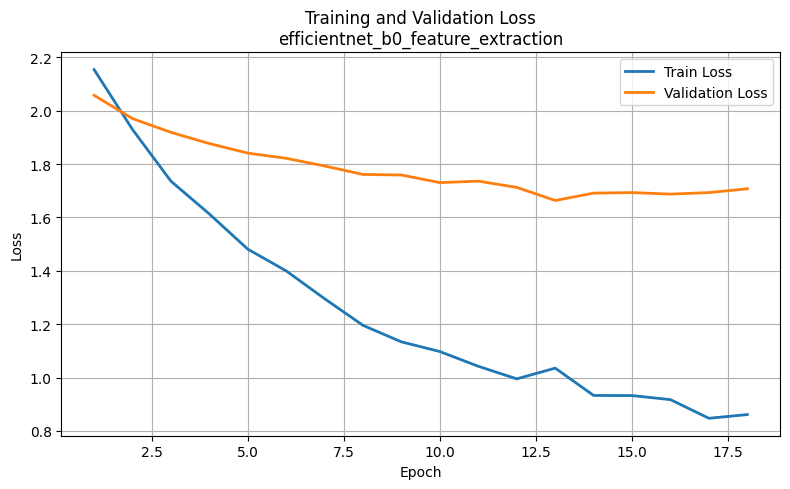

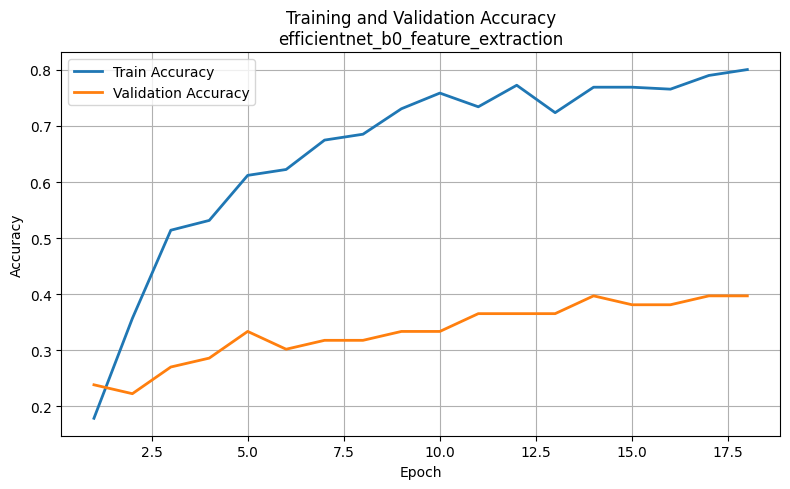

✓ Τα διαγράμματα εκπαίδευσης δημιουργήθηκαν επιτυχώς.


In [34]:
# =============================================================================
# 9.9 ΟΠΤΙΚΟΠΟΙΗΣΗ ΙΣΤΟΡΙΚΟΥ ΕΚΠΑΙΔΕΥΣΗΣ
# =============================================================================

plot_training_history(
    history=history,
    experiment_name=EXPERIMENT_NAME,
    results_dir=EXPERIMENT_RESULTS_DIR,
    save_plots=True
)

##Αποθήκευση των αποτελεσμάτων εκπαίδευσης

Το ιστορικό εκπαίδευσης και οι πληροφορίες που αφορούν τη διάρκεια, το
πλήθος εποχών και την καλύτερη επίδοση στο validation set αποθηκεύονται σε
αρχεία JSON.

In [35]:
# =============================================================================
# 9.10 ΑΠΟΘΗΚΕΥΣΗ ΑΠΟΤΕΛΕΣΜΑΤΩΝ ΕΚΠΑΙΔΕΥΣΗΣ
# =============================================================================

save_training_results(
    history=history,
    training_information=training_information,
    results_dir=EXPERIMENT_RESULTS_DIR
)

✓ Αποθηκεύτηκαν τα αποτελέσματα εκπαίδευσης.
Training history     : /content/drive/MyDrive/ptyxiaki/results/efficientnet_b0_feature_extraction/training_history.json
Training information : /content/drive/MyDrive/ptyxiaki/results/efficientnet_b0_feature_extraction/training_information.json


## Αξιολόγηση του μοντέλου στο test set

Το καλύτερο μοντέλο που προέκυψε από τη διαδικασία εκπαίδευσης αξιολογείται
στο ανεξάρτητο test set.

Υπολογίζονται οι μετρικές Accuracy, Macro Precision, Macro Recall,
Macro F1-score και Weighted F1-score.

Επιπλέον, δημιουργούνται το classification report και ο πίνακας σύγχυσης,
ώστε να εξεταστεί αναλυτικά η απόδοση του μοντέλου σε κάθε κατηγορία.

TEST SET RESULTS — efficientnet_b0_feature_extraction
Accuracy          : 0.5000
Top-3 Accuracy    : 0.8548
Macro Precision   : 0.5852
Macro Recall      : 0.4815
Macro F1-score    : 0.4857
Weighted F1-score : 0.4938

CLASSIFICATION REPORT
               precision    recall  f1-score   support

      ipeiros     0.3750    0.4286    0.4000         7
        kriti     1.0000    0.3333    0.5000         6
    makedonia     0.4545    0.6250    0.5263         8
nisia_aigaiou     0.6250    0.6250    0.6250         8
 nisia_ioniou     0.6000    0.5000    0.5455         6
 peloponnisos     0.3333    0.5714    0.4211         7
sterea_ellada     0.3333    0.1667    0.2222         6
    thessalia     1.0000    0.3333    0.5000         6
       thraki     0.5455    0.7500    0.6316         8

     accuracy                         0.5000        62
    macro avg     0.5852    0.4815    0.4857        62
 weighted avg     0.5735    0.5000    0.4938        62



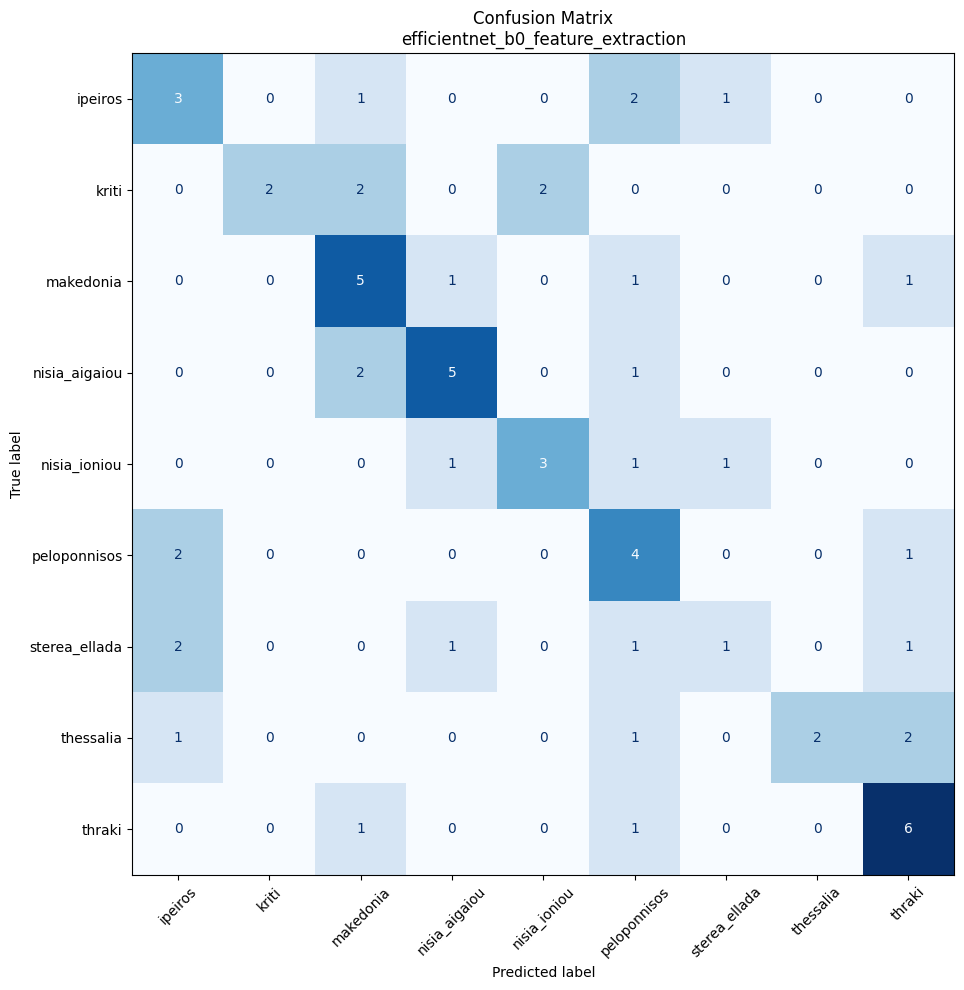


Αποθηκεύτηκαν:
Metrics              : /content/drive/MyDrive/ptyxiaki/results/efficientnet_b0_feature_extraction/test_metrics.json
Classification report: /content/drive/MyDrive/ptyxiaki/results/efficientnet_b0_feature_extraction/classification_report.json
Predictions          : /content/drive/MyDrive/ptyxiaki/results/efficientnet_b0_feature_extraction/test_predictions.npz
Confusion matrix     : /content/drive/MyDrive/ptyxiaki/results/efficientnet_b0_feature_extraction/confusion_matrix.png


In [36]:
# =============================================================================
# 9.11 ΑΞΙΟΛΟΓΗΣΗ ΣΤΟ TEST SET
# =============================================================================

test_metrics = evaluate_model_on_test_set(
    model=model,
    test_loader=test_loader,
    class_names=CLASS_NAMES,
    experiment_name=EXPERIMENT_NAME,
    results_dir=EXPERIMENT_RESULTS_DIR,
    save_results=True
)

In [37]:
# =============================================================================
# 9.12 ΑΠΟΘΗΚΕΥΣΗ ΤΕΛΙΚΟΥ ΜΟΝΤΕΛΟΥ
# =============================================================================

final_model_path = (
    EXPERIMENT_TRAINED_MODEL_DIR
    / "efficientnet_b0_feature_extraction_final.pth"
)

save_final_model(
    model=model,
    experiment_name=EXPERIMENT_NAME,
    model_path=final_model_path,
    test_metrics=test_metrics
)

✓ Το τελικό μοντέλο αποθηκεύτηκε επιτυχώς.
Model path: /content/drive/MyDrive/ptyxiaki/models/trained/efficientnet_b0_feature_extraction/efficientnet_b0_feature_extraction_final.pth


# ΠΕΙΡΑΜΑ 4: EfficientNet-B0 Partial Fine-Tuning

Στο τέταρτο πείραμα χρησιμοποιείται το προεκπαιδευμένο μοντέλο
EfficientNet-B0 με τη μέθοδο του Partial Fine-Tuning.

Αρχικά παγώνουν όλες οι παράμετροι του προεκπαιδευμένου δικτύου. Στη
συνέχεια ενεργοποιούνται για εκπαίδευση τα δύο τελευταία τμήματα εξαγωγής
χαρακτηριστικών του EfficientNet-B0, καθώς και το νέο τελικό επίπεδο
ταξινόμησης.

Η εκπαίδευση ενός μέρους του προεκπαιδευμένου δικτύου επιτρέπει στα
χαρακτηριστικά υψηλού επιπέδου να προσαρμοστούν καλύτερα στις εικόνες των
ελληνικών παραδοσιακών φορεσιών.

Επειδή ενημερώνονται και προεκπαιδευμένες παράμετροι, χρησιμοποιείται
μικρότερο learning rate από αυτό του Feature Extraction, ώστε να
περιοριστούν οι απότομες μεταβολές στα ήδη εκπαιδευμένα βάρη.

In [38]:
# =============================================================================
# 10.2 ΡΥΘΜΙΣΕΙΣ ΠΕΙΡΑΜΑΤΟΣ ΚΑΙ ΔΗΜΙΟΥΡΓΙΑ ΦΑΚΕΛΩΝ
# =============================================================================

EXPERIMENT_NAME = "efficientnet_b0_partial_fine_tuning"
MODEL_NAME = "EfficientNet-B0"
TRANSFER_LEARNING_MODE = "Partial Fine-Tuning"

# Χρησιμοποιείται μικρότερο learning rate επειδή εκπαιδεύονται
# και προεκπαιδευμένες παράμετροι.
LEARNING_RATE = 1e-4
WEIGHT_DECAY = DEFAULT_WEIGHT_DECAY

# Δημιουργία των φακέλων αποθήκευσης του πειράματος
experiment_paths = create_experiment_directories(
    EXPERIMENT_NAME
)

EXPERIMENT_RESULTS_DIR = (
    experiment_paths["results_dir"]
)

EXPERIMENT_CHECKPOINT_DIR = (
    experiment_paths["checkpoint_dir"]
)

EXPERIMENT_TRAINED_MODEL_DIR = (
    experiment_paths["trained_model_dir"]
)

print("=" * 70)
print("ΡΥΘΜΙΣΕΙΣ ΠΕΙΡΑΜΑΤΟΣ 4")
print("=" * 70)

print(f"Experiment name       : {EXPERIMENT_NAME}")
print(f"Model                 : {MODEL_NAME}")
print(f"Transfer learning     : {TRANSFER_LEARNING_MODE}")
print(f"Number of classes     : {NUM_CLASSES}")
print(f"Batch size            : {BATCH_SIZE}")
print(f"Maximum epochs        : {MAX_EPOCHS}")
print(f"Early stopping        : {EARLY_STOPPING_PATIENCE}")
print(f"Learning rate         : {LEARNING_RATE}")
print(f"Weight decay          : {WEIGHT_DECAY}")
print(f"Device                : {DEVICE}")

print("\nΦάκελοι πειράματος:")
print(f"Results               : {EXPERIMENT_RESULTS_DIR}")
print(f"Checkpoints           : {EXPERIMENT_CHECKPOINT_DIR}")
print(f"Trained model         : {EXPERIMENT_TRAINED_MODEL_DIR}")

print("\n" + "=" * 70)
print("Οι ρυθμίσεις του Πειράματος 4 ορίστηκαν επιτυχώς.")
print("=" * 70)

ΡΥΘΜΙΣΕΙΣ ΠΕΙΡΑΜΑΤΟΣ 4
Experiment name       : efficientnet_b0_partial_fine_tuning
Model                 : EfficientNet-B0
Transfer learning     : Partial Fine-Tuning
Number of classes     : 9
Batch size            : 16
Maximum epochs        : 25
Early stopping        : 5
Learning rate         : 0.0001
Weight decay          : 0.0001
Device                : cuda

Φάκελοι πειράματος:
Results               : /content/drive/MyDrive/ptyxiaki/results/efficientnet_b0_partial_fine_tuning
Checkpoints           : /content/drive/MyDrive/ptyxiaki/models/checkpoints/efficientnet_b0_partial_fine_tuning
Trained model         : /content/drive/MyDrive/ptyxiaki/models/trained/efficientnet_b0_partial_fine_tuning

Οι ρυθμίσεις του Πειράματος 4 ορίστηκαν επιτυχώς.


## Δημιουργία του μοντέλου EfficientNet-B0

Φορτώνεται το EfficientNet-B0 με προεκπαιδευμένα βάρη από το ImageNet.

Όλες οι παράμετροι παγώνουν αρχικά. Στη συνέχεια ενεργοποιούνται για
εκπαίδευση τα δύο τελευταία τμήματα του υποδικτύου εξαγωγής
χαρακτηριστικών και το νέο τελικό επίπεδο ταξινόμησης.

Το αρχικό επίπεδο ταξινόμησης αντικαθίσταται από νέο γραμμικό επίπεδο με
αριθμό εξόδων ίσο με τις εννέα κατηγορίες του dataset.

In [39]:
# =============================================================================
# 10.3 ΔΗΜΙΟΥΡΓΙΑ ΜΟΝΤΕΛΟΥ EFFICIENTNET-B0
# =============================================================================

import torch.nn as nn

from torchvision.models import (
    EfficientNet_B0_Weights,
    efficientnet_b0
)

# Επιλογή προεκπαιδευμένων βαρών
efficientnet_weights = EfficientNet_B0_Weights.DEFAULT

# Φόρτωση του προεκπαιδευμένου μοντέλου
model = efficientnet_b0(
    weights=efficientnet_weights
)

# -------------------------------------------------------------------------
# Πάγωμα όλων των παραμέτρων
# -------------------------------------------------------------------------

for parameter in model.parameters():
    parameter.requires_grad = False

# -------------------------------------------------------------------------
# Ενεργοποίηση των δύο τελευταίων τμημάτων του feature extractor
# -------------------------------------------------------------------------

for parameter in model.features[-2:].parameters():
    parameter.requires_grad = True

# -------------------------------------------------------------------------
# Αντικατάσταση του τελικού classification layer
# -------------------------------------------------------------------------

classifier_input_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features=classifier_input_features,
    out_features=NUM_CLASSES
)

# Το νέο layer είναι εξ ορισμού εκπαιδεύσιμο
for parameter in model.classifier.parameters():
    parameter.requires_grad = True

# Μεταφορά του μοντέλου στη διαθέσιμη συσκευή
model = model.to(DEVICE)

print("=" * 70)
print("ΔΗΜΙΟΥΡΓΙΑ ΜΟΝΤΕΛΟΥ")
print("=" * 70)

print(f"Model                  : {MODEL_NAME}")
print(f"Pretrained weights     : {efficientnet_weights}")
print(f"Classifier input size  : {classifier_input_features}")
print(f"Classifier output size : {NUM_CLASSES}")
print(f"Fine-tuned blocks      : model.features[-2:]")
print(f"Device                 : {DEVICE}")

print("\nΤο μοντέλο EfficientNet-B0 δημιουργήθηκε επιτυχώς.")

ΔΗΜΙΟΥΡΓΙΑ ΜΟΝΤΕΛΟΥ
Model                  : EfficientNet-B0
Pretrained weights     : EfficientNet_B0_Weights.IMAGENET1K_V1
Classifier input size  : 1280
Classifier output size : 9
Fine-tuned blocks      : model.features[-2:]
Device                 : cuda

Το μοντέλο EfficientNet-B0 δημιουργήθηκε επιτυχώς.


## Έλεγχος των εκπαιδεύσιμων επιπέδων

Πραγματοποιείται έλεγχος των παραμέτρων που έχουν ενεργοποιηθεί για
εκπαίδευση.

Οι εκπαιδεύσιμες παράμετροι πρέπει να ανήκουν αποκλειστικά στα δύο τελευταία
τμήματα του feature extractor και στον classifier.

In [40]:
# =============================================================================
# 10.4 ΕΛΕΓΧΟΣ ΕΚΠΑΙΔΕΥΣΙΜΩΝ ΠΑΡΑΜΕΤΡΩΝ
# =============================================================================

print("=" * 70)
print("ΕΚΠΑΙΔΕΥΣΙΜΕΣ ΠΑΡΑΜΕΤΡΟΙ")
print("=" * 70)

trainable_layer_names = []

for parameter_name, parameter in model.named_parameters():

    if parameter.requires_grad:
        trainable_layer_names.append(
            parameter_name
        )

        print(parameter_name)

print("\nΣυνολικό πλήθος εκπαιδεύσιμων tensors:")
print(len(trainable_layer_names))

ΕΚΠΑΙΔΕΥΣΙΜΕΣ ΠΑΡΑΜΕΤΡΟΙ
features.7.0.block.0.0.weight
features.7.0.block.0.1.weight
features.7.0.block.0.1.bias
features.7.0.block.1.0.weight
features.7.0.block.1.1.weight
features.7.0.block.1.1.bias
features.7.0.block.2.fc1.weight
features.7.0.block.2.fc1.bias
features.7.0.block.2.fc2.weight
features.7.0.block.2.fc2.bias
features.7.0.block.3.0.weight
features.7.0.block.3.1.weight
features.7.0.block.3.1.bias
features.8.0.weight
features.8.1.weight
features.8.1.bias
classifier.1.weight
classifier.1.bias

Συνολικό πλήθος εκπαιδεύσιμων tensors:
18


## Σύνοψη του μοντέλου

Παρουσιάζεται το συνολικό πλήθος παραμέτρων του EfficientNet-B0, καθώς και
ο αριθμός των εκπαιδεύσιμων και παγωμένων παραμέτρων.

Σε αντίθεση με το Feature Extraction, στο Partial Fine-Tuning το πλήθος των
εκπαιδεύσιμων παραμέτρων είναι μεγαλύτερο, επειδή ενημερώνονται και τα δύο
τελευταία τμήματα του feature extractor.

In [41]:
# =============================================================================
# 10.5 ΣΥΝΟΨΗ ΜΟΝΤΕΛΟΥ
# =============================================================================

print_model_summary(
    model=model,
    experiment_name=EXPERIMENT_NAME,
    transfer_learning_mode=TRANSFER_LEARNING_MODE
)

ΣΥΝΟΨΗ ΜΟΝΤΕΛΟΥ
Experiment name            : efficientnet_b0_partial_fine_tuning
Model class                : EfficientNet
Transfer learning mode     : Partial Fine-Tuning
Number of classes          : 9
Running on                 : cuda

Parameters:
Total parameters          : 4,019,077
Trainable parameters      : 1,140,921
Frozen parameters         : 2,878,156


## Έλεγχος της εξόδου του μοντέλου

Πριν από την εκπαίδευση πραγματοποιείται δοκιμαστική προώθηση ενός
εικονικού batch εικόνων μέσα από το δίκτυο.

Η έξοδος πρέπει να έχει διαστάσεις `[batch_size, number_of_classes]`,
δηλαδή `[16, 9]` για τις τρέχουσες ρυθμίσεις.

In [42]:
# =============================================================================
# 10.6 ΕΛΕΓΧΟΣ ΕΞΟΔΟΥ ΜΟΝΤΕΛΟΥ
# =============================================================================

validate_model_output(
    model=model,
    batch_size=BATCH_SIZE
)


Model output check:
Output tensor shape        : torch.Size([16, 9])
✓ Η έξοδος του μοντέλου έχει το σωστό σχήμα.


## Συνάρτηση απώλειας και αλγόριθμος βελτιστοποίησης

Χρησιμοποιείται η συνάρτηση απώλειας Cross-Entropy Loss, η οποία είναι
κατάλληλη για προβλήματα πολυταξικής ταξινόμησης.

Ως optimizer χρησιμοποιείται ο Adam. Στον optimizer περιλαμβάνονται μόνο
οι παράμετροι που έχουν ενεργοποιηθεί για εκπαίδευση, δηλαδή τα δύο
τελευταία τμήματα του feature extractor και ο classifier.

Το learning rate ορίζεται σε `0.0001`, ώστε η προσαρμογή των
προεκπαιδευμένων βαρών να πραγματοποιηθεί με μικρά και ελεγχόμενα βήματα.

In [43]:
# =============================================================================
# 10.7 ΣΥΝΑΡΤΗΣΗ ΑΠΩΛΕΙΑΣ ΚΑΙ OPTIMIZER
# =============================================================================

import torch.optim as optim

criterion = nn.CrossEntropyLoss()

trainable_parameters = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]

optimizer = optim.Adam(
    trainable_parameters,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

number_of_trainable_parameters = sum(
    parameter.numel()
    for parameter in trainable_parameters
)

print("=" * 70)
print("ΡΥΘΜΙΣΕΙΣ ΕΚΠΑΙΔΕΥΣΗΣ")
print("=" * 70)

print(f"Loss function          : {criterion.__class__.__name__}")
print(f"Optimizer              : {optimizer.__class__.__name__}")
print(f"Learning rate          : {LEARNING_RATE}")
print(f"Weight decay           : {WEIGHT_DECAY}")
print(f"Trainable parameters   : {number_of_trainable_parameters:,}")

print("\n✓ Η συνάρτηση απώλειας και ο optimizer δημιουργήθηκαν επιτυχώς.")

ΡΥΘΜΙΣΕΙΣ ΕΚΠΑΙΔΕΥΣΗΣ
Loss function          : CrossEntropyLoss
Optimizer              : Adam
Learning rate          : 0.0001
Weight decay           : 0.0001
Trainable parameters   : 1,140,921

✓ Η συνάρτηση απώλειας και ο optimizer δημιουργήθηκαν επιτυχώς.


In [44]:
# =============================================================================
# 10.8 ΕΚΠΑΙΔΕΥΣΗ ΜΟΝΤΕΛΟΥ
# =============================================================================

checkpoint_path = (
    EXPERIMENT_CHECKPOINT_DIR /
    "best_model_checkpoint.pth"
)

model, history, training_information = train_model(
    model=model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    criterion=criterion,
    optimizer=optimizer,
    experiment_name=EXPERIMENT_NAME,
    checkpoint_path=checkpoint_path,
    max_epochs=MAX_EPOCHS,
    early_stopping_patience=EARLY_STOPPING_PATIENCE
)

ΕΝΑΡΞΗ ΕΚΠΑΙΔΕΥΣΗΣ — efficientnet_b0_partial_fine_tuning

Epoch [1/25]
Learning Rate       : 0.00010000
Train Loss          : 2.1745
Validation Loss     : 2.1919
Train Accuracy      : 0.1643
Validation Accuracy : 0.1429
Epoch Time          : 3.84 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [2/25]
Learning Rate       : 0.00010000
Train Loss          : 2.0545
Validation Loss     : 2.1246
Train Accuracy      : 0.3252
Validation Accuracy : 0.2222
Epoch Time          : 3.70 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [3/25]
Learning Rate       : 0.00010000
Train Loss          : 1.9805
Validation Loss     : 2.0659
Train Accuracy      : 0.4126
Validation Accuracy : 0.2222
Epoch Time          : 3.73 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [4/25]
Learning Rate       : 0.00010000
Train Loss          : 1.8589
Validation Loss     : 2.0130
Train Accuracy      : 0.4860
Validation Accuracy : 0.2540
Epoch Time          : 5.32 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Ep

## Οπτικοποίηση του ιστορικού εκπαίδευσης

Παρουσιάζονται οι καμπύλες της συνάρτησης απώλειας και της ακρίβειας για το
training και το validation set.

Τα διαγράμματα επιτρέπουν την παρακολούθηση της σύγκλισης του μοντέλου και
τον εντοπισμό πιθανών ενδείξεων υπερπροσαρμογής.

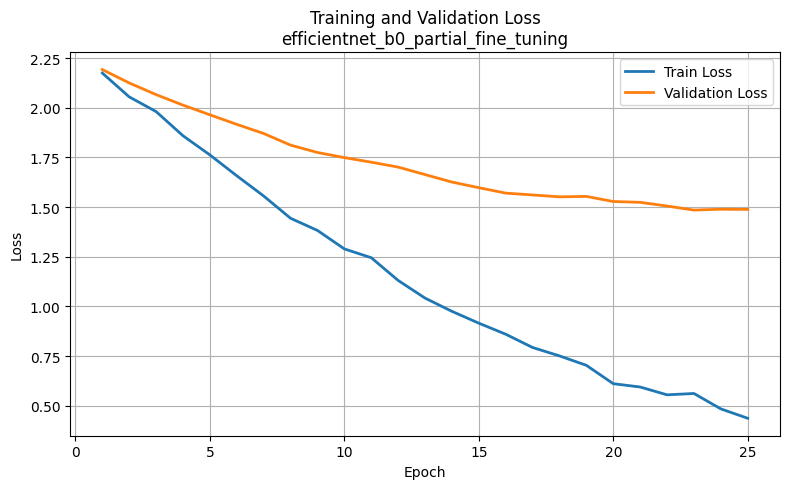

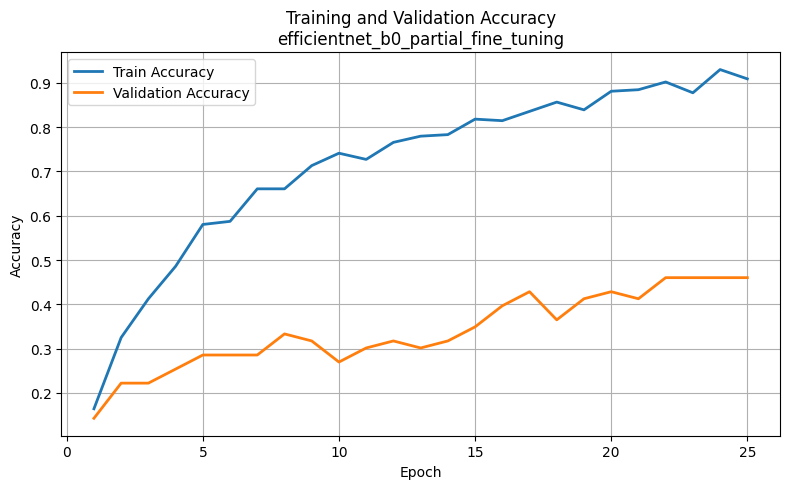

✓ Τα διαγράμματα εκπαίδευσης δημιουργήθηκαν επιτυχώς.


In [45]:
# =============================================================================
# 10.9 ΟΠΤΙΚΟΠΟΙΗΣΗ ΙΣΤΟΡΙΚΟΥ ΕΚΠΑΙΔΕΥΣΗΣ
# =============================================================================

plot_training_history(
    history=history,
    experiment_name=EXPERIMENT_NAME,
    results_dir=EXPERIMENT_RESULTS_DIR,
    save_plots=True
)

## Αποθήκευση των αποτελεσμάτων εκπαίδευσης

Το ιστορικό εκπαίδευσης και οι πληροφορίες της διαδικασίας αποθηκεύονται σε
αρχεία JSON, ώστε να είναι διαθέσιμα για μελλοντική ανάλυση και σύγκριση με
τα υπόλοιπα πειράματα.

In [46]:
# =============================================================================
# 10.10 ΑΠΟΘΗΚΕΥΣΗ ΑΠΟΤΕΛΕΣΜΑΤΩΝ ΕΚΠΑΙΔΕΥΣΗΣ
# =============================================================================

save_training_results(
    history=history,
    training_information=training_information,
    results_dir=EXPERIMENT_RESULTS_DIR
)

✓ Αποθηκεύτηκαν τα αποτελέσματα εκπαίδευσης.
Training history     : /content/drive/MyDrive/ptyxiaki/results/efficientnet_b0_partial_fine_tuning/training_history.json
Training information : /content/drive/MyDrive/ptyxiaki/results/efficientnet_b0_partial_fine_tuning/training_information.json


##Αξιολόγηση του μοντέλου στο test set

Το καλύτερο μοντέλο που προέκυψε από τη διαδικασία εκπαίδευσης αξιολογείται
στο ανεξάρτητο test set.

Υπολογίζονται οι μετρικές Accuracy, Macro Precision, Macro Recall,
Macro F1-score και Weighted F1-score.

Παράλληλα δημιουργούνται το classification report και ο πίνακας σύγχυσης,
ώστε να αξιολογηθεί αναλυτικά η απόδοση του μοντέλου σε κάθε κατηγορία.

TEST SET RESULTS — efficientnet_b0_partial_fine_tuning
Accuracy          : 0.6129
Top-3 Accuracy    : 0.9194
Macro Precision   : 0.6714
Macro Recall      : 0.6038
Macro F1-score    : 0.6072
Weighted F1-score : 0.6130

CLASSIFICATION REPORT
               precision    recall  f1-score   support

      ipeiros     0.4000    0.5714    0.4706         7
        kriti     1.0000    0.5000    0.6667         6
    makedonia     1.0000    0.3750    0.5455         8
nisia_aigaiou     0.6364    0.8750    0.7368         8
 nisia_ioniou     0.5000    0.5000    0.5000         6
 peloponnisos     0.5000    0.5714    0.5333         7
sterea_ellada     0.4286    0.5000    0.4615         6
    thessalia     0.8000    0.6667    0.7273         6
       thraki     0.7778    0.8750    0.8235         8

     accuracy                         0.6129        62
    macro avg     0.6714    0.6038    0.6072        62
 weighted avg     0.6772    0.6129    0.6130        62



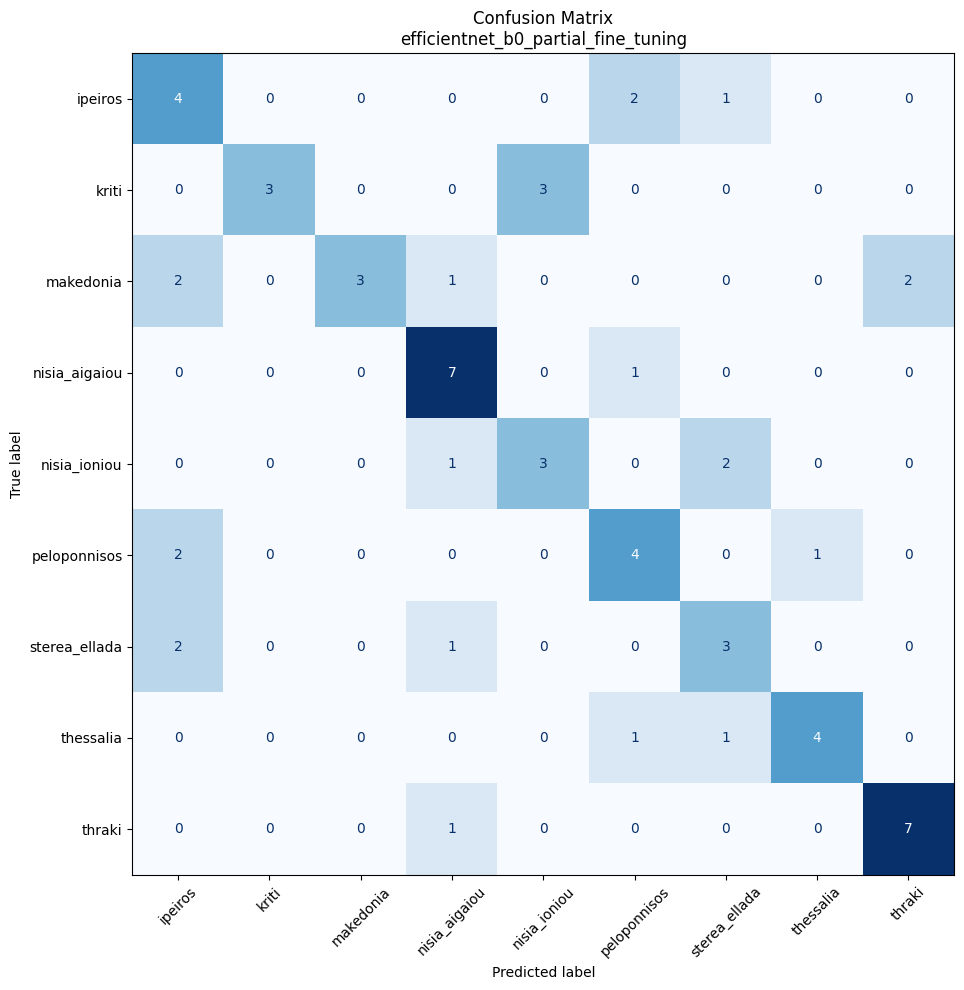


Αποθηκεύτηκαν:
Metrics              : /content/drive/MyDrive/ptyxiaki/results/efficientnet_b0_partial_fine_tuning/test_metrics.json
Classification report: /content/drive/MyDrive/ptyxiaki/results/efficientnet_b0_partial_fine_tuning/classification_report.json
Predictions          : /content/drive/MyDrive/ptyxiaki/results/efficientnet_b0_partial_fine_tuning/test_predictions.npz
Confusion matrix     : /content/drive/MyDrive/ptyxiaki/results/efficientnet_b0_partial_fine_tuning/confusion_matrix.png


In [47]:
# =============================================================================
# 10.11 ΑΞΙΟΛΟΓΗΣΗ ΣΤΟ TEST SET
# =============================================================================

test_metrics = evaluate_model_on_test_set(
    model=model,
    test_loader=test_loader,
    class_names=CLASS_NAMES,
    experiment_name=EXPERIMENT_NAME,
    results_dir=EXPERIMENT_RESULTS_DIR,
    save_results=True
)

In [48]:
# =============================================================================
# 10.12 ΑΠΟΘΗΚΕΥΣΗ ΤΕΛΙΚΟΥ ΜΟΝΤΕΛΟΥ
# =============================================================================

final_model_path = (
    EXPERIMENT_TRAINED_MODEL_DIR /
    "efficientnet_b0_partial_fine_tuning_final.pth"
)

save_final_model(
    model=model,
    experiment_name=EXPERIMENT_NAME,
    model_path=final_model_path,
    test_metrics=test_metrics
)

✓ Το τελικό μοντέλο αποθηκεύτηκε επιτυχώς.
Model path: /content/drive/MyDrive/ptyxiaki/models/trained/efficientnet_b0_partial_fine_tuning/efficientnet_b0_partial_fine_tuning_final.pth


## Ολοκλήρωση του Πειράματος 4

Το τέταρτο πείραμα ολοκληρώθηκε με τη χρήση του EfficientNet-B0 και της
μεθόδου Partial Fine-Tuning.

Κατά τη διαδικασία αυτή εκπαιδεύτηκαν τα δύο τελευταία τμήματα του
υποδικτύου εξαγωγής χαρακτηριστικών καθώς και το τελικό επίπεδο
ταξινόμησης.

Τα αποτελέσματα της εκπαίδευσης, οι τελικές μετρικές αξιολόγησης, το
classification report, ο πίνακας σύγχυσης και το τελικό μοντέλο
αποθηκεύτηκαν στους αντίστοιχους φακέλους του πειράματος.

In [49]:
# =============================================================================
# 10.13 ΤΕΛΙΚΗ ΕΠΙΒΕΒΑΙΩΣΗ ΠΕΙΡΑΜΑΤΟΣ 4
# =============================================================================

print("=" * 80)
print("ΟΛΟΚΛΗΡΩΣΗ ΠΕΙΡΑΜΑΤΟΣ 4")
print("=" * 80)

print(f"Experiment name       : {EXPERIMENT_NAME}")
print(f"Model                 : {MODEL_NAME}")
print(f"Transfer learning     : {TRANSFER_LEARNING_MODE}")

print("\nTraining:")

print(
    f"Epochs completed      : "
    f"{training_information['epochs_completed']}"
)

print(
    f"Best epoch            : "
    f"{training_information['best_epoch']}"
)

print(
    f"Best validation loss  : "
    f"{training_information['best_validation_loss']:.4f}"
)

print(
    f"Best validation acc.  : "
    f"{training_information['best_validation_accuracy']:.4f}"
)

print("\nTest set:")

print(
    f"Accuracy              : "
    f"{test_metrics['accuracy']:.4f}"
)

print(
    f"Macro Precision       : "
    f"{test_metrics['macro_precision']:.4f}"
)

print(
    f"Macro Recall          : "
    f"{test_metrics['macro_recall']:.4f}"
)

print(
    f"Macro F1-score        : "
    f"{test_metrics['macro_f1']:.4f}"
)

print(
    f"Weighted F1-score     : "
    f"{test_metrics['weighted_f1']:.4f}"
)

print("\nSaved files:")

print(f"Results directory     : {EXPERIMENT_RESULTS_DIR}")
print(f"Best checkpoint       : {checkpoint_path}")
print(f"Final model           : {final_model_path}")

print("\n" + "=" * 80)
print("Το Πείραμα 4 ολοκληρώθηκε επιτυχώς.")
print("=" * 80)

ΟΛΟΚΛΗΡΩΣΗ ΠΕΙΡΑΜΑΤΟΣ 4
Experiment name       : efficientnet_b0_partial_fine_tuning
Model                 : EfficientNet-B0
Transfer learning     : Partial Fine-Tuning

Training:
Epochs completed      : 25
Best epoch            : 23
Best validation loss  : 1.4847
Best validation acc.  : 0.4603

Test set:
Accuracy              : 0.6129
Macro Precision       : 0.6714
Macro Recall          : 0.6038
Macro F1-score        : 0.6072
Weighted F1-score     : 0.6130

Saved files:
Results directory     : /content/drive/MyDrive/ptyxiaki/results/efficientnet_b0_partial_fine_tuning
Best checkpoint       : /content/drive/MyDrive/ptyxiaki/models/checkpoints/efficientnet_b0_partial_fine_tuning/best_model_checkpoint.pth
Final model           : /content/drive/MyDrive/ptyxiaki/models/trained/efficientnet_b0_partial_fine_tuning/efficientnet_b0_partial_fine_tuning_final.pth

Το Πείραμα 4 ολοκληρώθηκε επιτυχώς.


#ΠΕΙΡΑΜΑ 5 — ConvNeXt-Tiny Feature Extraction

Στο πέμπτο πείραμα χρησιμοποιείται το προεκπαιδευμένο μοντέλο
ConvNeXt-Tiny με τη μέθοδο του Feature Extraction.

Όλες οι παράμετροι του προεκπαιδευμένου δικτύου παραμένουν παγωμένες
και εκπαιδεύεται αποκλειστικά το νέο τελικό επίπεδο ταξινόμησης.

Το αρχικό επίπεδο ταξινόμησης αντικαθίσταται από νέο γραμμικό επίπεδο
με αριθμό εξόδων ίσο με τις εννέα γεωγραφικές κατηγορίες του dataset.

Στόχος του πειράματος είναι να διερευνηθεί αν η αρχιτεκτονική
ConvNeXt-Tiny μπορεί να παρουσιάσει καλύτερη Top-1 απόδοση σε σχέση
με τα ResNet18 και EfficientNet-B0.

##Ρυθμίσεις πειράματος

Ορίζονται το όνομα του πειράματος, η αρχιτεκτονική του μοντέλου και η
μέθοδος Transfer Learning.

Για το Feature Extraction χρησιμοποιούνται οι κοινές υπερπαράμετροι
βελτιστοποίησης του notebook.

Παράλληλα δημιουργούνται ξεχωριστοί φάκελοι για την αποθήκευση των
αποτελεσμάτων, των checkpoints και του τελικού εκπαιδευμένου μοντέλου.

In [50]:
# =============================================================================
# 12.2 ΡΥΘΜΙΣΕΙΣ ΠΕΙΡΑΜΑΤΟΣ
# =============================================================================

EXPERIMENT_NAME = "convnext_tiny_feature_extraction"

MODEL_ARCHITECTURE = "ConvNeXt-Tiny"

TRANSFER_LEARNING_MODE = "Feature Extraction"

EXPERIMENT_LEARNING_RATE = DEFAULT_LEARNING_RATE
EXPERIMENT_WEIGHT_DECAY = DEFAULT_WEIGHT_DECAY


# -----------------------------------------------------------------------------
# Δημιουργία φακέλων του πειράματος
# -----------------------------------------------------------------------------

experiment_directories = create_experiment_directories(
    experiment_name=EXPERIMENT_NAME
)

EXPERIMENT_RESULTS_DIR = (
    experiment_directories["results_dir"]
)

EXPERIMENT_CHECKPOINT_DIR = (
    experiment_directories["checkpoint_dir"]
)

EXPERIMENT_TRAINED_MODEL_DIR = (
    experiment_directories["trained_model_dir"]
)


# -----------------------------------------------------------------------------
# Διαδρομές αρχείων
# -----------------------------------------------------------------------------

BEST_CHECKPOINT_PATH = (
    EXPERIMENT_CHECKPOINT_DIR
    / "best_checkpoint.pth"
)

FINAL_MODEL_PATH = (
    EXPERIMENT_TRAINED_MODEL_DIR
    / "convnext_tiny_feature_extraction.pth"
)

EXPERIMENT_SUMMARY_PATH = (
    EXPERIMENT_RESULTS_DIR
    / "experiment_summary.json"
)


# -----------------------------------------------------------------------------
# Εμφάνιση ρυθμίσεων
# -----------------------------------------------------------------------------

print("=" * 70)
print("ΠΕΙΡΑΜΑ 5 — CONVNEXT-TINY FEATURE EXTRACTION")
print("=" * 70)

print(f"Experiment name       : {EXPERIMENT_NAME}")
print(f"Model architecture    : {MODEL_ARCHITECTURE}")
print(f"Transfer learning     : {TRANSFER_LEARNING_MODE}")

print("\nOptimization:")
print(f"Learning rate         : {EXPERIMENT_LEARNING_RATE}")
print(f"Weight decay          : {EXPERIMENT_WEIGHT_DECAY}")
print(f"Maximum epochs        : {MAX_EPOCHS}")
print(f"Early stopping        : {EARLY_STOPPING_PATIENCE}")

print("\nDirectories:")
print(f"Results               : {EXPERIMENT_RESULTS_DIR}")
print(f"Checkpoints           : {EXPERIMENT_CHECKPOINT_DIR}")
print(f"Trained models        : {EXPERIMENT_TRAINED_MODEL_DIR}")

print("\nFiles:")
print(f"Best checkpoint       : {BEST_CHECKPOINT_PATH}")
print(f"Final model           : {FINAL_MODEL_PATH}")
print(f"Experiment summary    : {EXPERIMENT_SUMMARY_PATH}")

ΠΕΙΡΑΜΑ 5 — CONVNEXT-TINY FEATURE EXTRACTION
Experiment name       : convnext_tiny_feature_extraction
Model architecture    : ConvNeXt-Tiny
Transfer learning     : Feature Extraction

Optimization:
Learning rate         : 0.001
Weight decay          : 0.0001
Maximum epochs        : 25
Early stopping        : 5

Directories:
Results               : /content/drive/MyDrive/ptyxiaki/results/convnext_tiny_feature_extraction
Checkpoints           : /content/drive/MyDrive/ptyxiaki/models/checkpoints/convnext_tiny_feature_extraction
Trained models        : /content/drive/MyDrive/ptyxiaki/models/trained/convnext_tiny_feature_extraction

Files:
Best checkpoint       : /content/drive/MyDrive/ptyxiaki/models/checkpoints/convnext_tiny_feature_extraction/best_checkpoint.pth
Final model           : /content/drive/MyDrive/ptyxiaki/models/trained/convnext_tiny_feature_extraction/convnext_tiny_feature_extraction.pth
Experiment summary    : /content/drive/MyDrive/ptyxiaki/results/convnext_tiny_feature_ex

## Δημιουργία του μοντέλου ConvNeXt-Tiny

Φορτώνεται το ConvNeXt-Tiny με προεκπαιδευμένα βάρη από το ImageNet.

Αρχικά παγώνουν όλες οι παράμετροι του προεκπαιδευμένου δικτύου, ώστε να
μη μεταβάλλονται κατά τη διάρκεια της εκπαίδευσης.

Στη συνέχεια, το αρχικό τελικό επίπεδο ταξινόμησης αντικαθίσταται από νέο
γραμμικό επίπεδο με εννέα εξόδους, μία για κάθε γεωγραφική κατηγορία του
dataset.

Κατά συνέπεια, στο συγκεκριμένο πείραμα εκπαιδεύεται αποκλειστικά το νέο
τελικό επίπεδο ταξινόμησης.

In [51]:
# =============================================================================
# 12.3 ΔΗΜΙΟΥΡΓΙΑ CONVNEXT-TINY ΓΙΑ FEATURE EXTRACTION
# =============================================================================

import torch.nn as nn

from torchvision.models import (
    ConvNeXt_Tiny_Weights,
    convnext_tiny
)


# -----------------------------------------------------------------------------
# Φόρτωση προεκπαιδευμένων βαρών
# -----------------------------------------------------------------------------

convnext_weights = ConvNeXt_Tiny_Weights.DEFAULT

model = convnext_tiny(
    weights=convnext_weights
)


# -----------------------------------------------------------------------------
# Πάγωμα όλων των προεκπαιδευμένων παραμέτρων
# -----------------------------------------------------------------------------

for parameter in model.parameters():
    parameter.requires_grad = False


# -----------------------------------------------------------------------------
# Αντικατάσταση του τελικού classification layer
# -----------------------------------------------------------------------------

classifier_input_features = (
    model.classifier[2].in_features
)

model.classifier[2] = nn.Linear(
    in_features=classifier_input_features,
    out_features=NUM_CLASSES
)


# -----------------------------------------------------------------------------
# Μεταφορά στη διαθέσιμη συσκευή
# -----------------------------------------------------------------------------

model = model.to(
    DEVICE
)


# -----------------------------------------------------------------------------
# Έλεγχος εκπαιδεύσιμων παραμέτρων
# -----------------------------------------------------------------------------

trainable_parameter_names = [
    parameter_name
    for parameter_name, parameter in model.named_parameters()
    if parameter.requires_grad
]

expected_trainable_parameter_names = [
    "classifier.2.weight",
    "classifier.2.bias"
]

if (
    trainable_parameter_names
    != expected_trainable_parameter_names
):
    raise ValueError(
        "Στο Feature Extraction πρέπει να είναι εκπαιδεύσιμες "
        "μόνο οι παράμετροι classifier.2.weight και "
        "classifier.2.bias.\n"
        f"Βρέθηκαν: {trainable_parameter_names}"
    )


# -----------------------------------------------------------------------------
# Σύνοψη μοντέλου
# -----------------------------------------------------------------------------

print_model_summary(
    model=model,
    experiment_name=EXPERIMENT_NAME,
    transfer_learning_mode=TRANSFER_LEARNING_MODE
)

print("\nFinal classification layer:")
print(model.classifier[2])

print("\nTrainable parameter names:")

for parameter_name in trainable_parameter_names:
    print(f"- {parameter_name}")


# -----------------------------------------------------------------------------
# Έλεγχος εξόδου μοντέλου
# -----------------------------------------------------------------------------

validate_model_output(
    model=model,
    batch_size=min(
        BATCH_SIZE,
        4
    )
)

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 203MB/s]


ΣΥΝΟΨΗ ΜΟΝΤΕΛΟΥ
Experiment name            : convnext_tiny_feature_extraction
Model class                : ConvNeXt
Transfer learning mode     : Feature Extraction
Number of classes          : 9
Running on                 : cuda

Parameters:
Total parameters          : 27,827,049
Trainable parameters      : 6,921
Frozen parameters         : 27,820,128

Final classification layer:
Linear(in_features=768, out_features=9, bias=True)

Trainable parameter names:
- classifier.2.weight
- classifier.2.bias

Model output check:
Output tensor shape        : torch.Size([4, 9])
✓ Η έξοδος του μοντέλου έχει το σωστό σχήμα.


## Συνάρτηση κόστους και αλγόριθμος βελτιστοποίησης

Για την εκπαίδευση χρησιμοποιείται η συνάρτηση κόστους Cross-Entropy Loss,
η οποία είναι κατάλληλη για προβλήματα πολυταξικής ταξινόμησης.

Ως αλγόριθμος βελτιστοποίησης χρησιμοποιείται ο Adam.

Στον optimizer περιλαμβάνονται αποκλειστικά οι εκπαιδεύσιμες παράμετροι
του νέου τελικού επιπέδου ταξινόμησης.

In [52]:
# =============================================================================
# 12.4 ΣΥΝΑΡΤΗΣΗ ΚΟΣΤΟΥΣ ΚΑΙ OPTIMIZER
# =============================================================================

import torch.optim as optim

criterion = nn.CrossEntropyLoss()

trainable_parameters = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]

if len(trainable_parameters) == 0:
    raise ValueError(
        "Δεν βρέθηκαν εκπαιδεύσιμες παράμετροι."
    )

optimizer = optim.Adam(
    params=trainable_parameters,
    lr=EXPERIMENT_LEARNING_RATE,
    weight_decay=EXPERIMENT_WEIGHT_DECAY
)

optimizer_parameter_count = sum(
    parameter.numel()
    for parameter_group in optimizer.param_groups
    for parameter in parameter_group["params"]
)

model_trainable_parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

if (
    optimizer_parameter_count
    != model_trainable_parameter_count
):
    raise ValueError(
        "Ο optimizer δεν περιλαμβάνει ακριβώς όλες τις "
        "εκπαιδεύσιμες παραμέτρους."
    )

print("=" * 70)
print("ΣΥΝΑΡΤΗΣΗ ΚΟΣΤΟΥΣ ΚΑΙ OPTIMIZER")
print("=" * 70)

print(f"Loss function          : {criterion.__class__.__name__}")
print(f"Optimizer              : {optimizer.__class__.__name__}")
print(f"Learning rate          : {EXPERIMENT_LEARNING_RATE}")
print(f"Weight decay           : {EXPERIMENT_WEIGHT_DECAY}")
print(f"Optimized parameters   : {optimizer_parameter_count:,}")

ΣΥΝΑΡΤΗΣΗ ΚΟΣΤΟΥΣ ΚΑΙ OPTIMIZER
Loss function          : CrossEntropyLoss
Optimizer              : Adam
Learning rate          : 0.001
Weight decay           : 0.0001
Optimized parameters   : 6,921


## Εκπαίδευση του μοντέλου

Το ConvNeXt-Tiny εκπαιδεύεται χρησιμοποιώντας το training set, ενώ η
απόδοσή του παρακολουθείται στο validation set μετά από κάθε εποχή.

Η διαδικασία περιλαμβάνει Early Stopping με βάση το validation loss.
Όταν δεν παρατηρείται βελτίωση για προκαθορισμένο αριθμό διαδοχικών
εποχών, η εκπαίδευση διακόπτεται αυτόματα.

Το καλύτερο checkpoint του μοντέλου αποθηκεύεται με βάση τη μικρότερη
τιμή validation loss.

In [53]:
# =============================================================================
# 12.5 ΕΚΠΑΙΔΕΥΣΗ ΜΟΝΤΕΛΟΥ
# =============================================================================

model, training_history, training_information = train_model(
    model=model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    criterion=criterion,
    optimizer=optimizer,
    experiment_name=EXPERIMENT_NAME,
    checkpoint_path=BEST_CHECKPOINT_PATH,
    max_epochs=MAX_EPOCHS,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    scheduler=None
)

ΕΝΑΡΞΗ ΕΚΠΑΙΔΕΥΣΗΣ — convnext_tiny_feature_extraction

Epoch [1/25]
Learning Rate       : 0.00100000
Train Loss          : 2.1554
Validation Loss     : 1.9968
Train Accuracy      : 0.1678
Validation Accuracy : 0.3333
Epoch Time          : 10.87 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [2/25]
Learning Rate       : 0.00100000
Train Loss          : 1.8055
Validation Loss     : 1.8178
Train Accuracy      : 0.5035
Validation Accuracy : 0.3810
Epoch Time          : 3.88 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [3/25]
Learning Rate       : 0.00100000
Train Loss          : 1.5551
Validation Loss     : 1.7078
Train Accuracy      : 0.5874
Validation Accuracy : 0.4603
Epoch Time          : 4.19 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [4/25]
Learning Rate       : 0.00100000
Train Loss          : 1.3820
Validation Loss     : 1.6215
Train Accuracy      : 0.6643
Validation Accuracy : 0.5556
Epoch Time          : 5.05 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoc

## Αποθήκευση αποτελεσμάτων εκπαίδευσης

Μετά την ολοκλήρωση της διαδικασίας εκπαίδευσης αποθηκεύονται τα βασικά
στοιχεία του ιστορικού εκπαίδευσης και οι πληροφορίες που αφορούν την
πορεία του πειράματος.

Τα δεδομένα αυτά περιλαμβάνουν τις τιμές της συνάρτησης απώλειας και της
ακρίβειας για τα training και validation sets, καθώς και πληροφορίες όπως
ο συνολικός χρόνος εκπαίδευσης, ο αριθμός των εποχών που ολοκληρώθηκαν και
η εποχή στην οποία επιτεύχθηκε η καλύτερη επίδοση στο validation set.

Η αποθήκευση των συγκεκριμένων πληροφοριών επιτρέπει τη μεταγενέστερη
ανάλυση και σύγκριση του πειράματος με τις υπόλοιπες αρχιτεκτονικές.

In [54]:
# =============================================================================
# 12.6 ΑΠΟΘΗΚΕΥΣΗ ΑΠΟΤΕΛΕΣΜΑΤΩΝ ΕΚΠΑΙΔΕΥΣΗΣ
# =============================================================================

save_training_results(
    history=training_history,
    training_information=training_information,
    results_dir=EXPERIMENT_RESULTS_DIR
)

✓ Αποθηκεύτηκαν τα αποτελέσματα εκπαίδευσης.
Training history     : /content/drive/MyDrive/ptyxiaki/results/convnext_tiny_feature_extraction/training_history.json
Training information : /content/drive/MyDrive/ptyxiaki/results/convnext_tiny_feature_extraction/training_information.json


## Οπτικοποίηση της πορείας εκπαίδευσης

Για την οπτική αξιολόγηση της διαδικασίας εκπαίδευσης δημιουργούνται
διαγράμματα που παρουσιάζουν την εξέλιξη της συνάρτησης απώλειας και της
ακρίβειας ανά εποχή.

Στα διαγράμματα παρουσιάζονται ταυτόχρονα οι τιμές για το training και το
validation set. Με αυτόν τον τρόπο μπορεί να εξεταστεί η σύγκλιση του
μοντέλου και να εντοπιστούν πιθανές ενδείξεις υπερπροσαρμογής.

Τα παραγόμενα διαγράμματα αποθηκεύονται στον φάκελο αποτελεσμάτων του
συγκεκριμένου πειράματος.

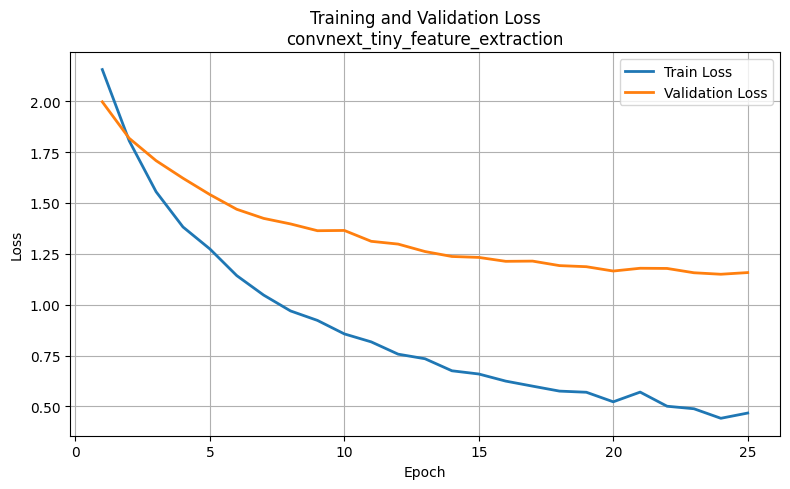

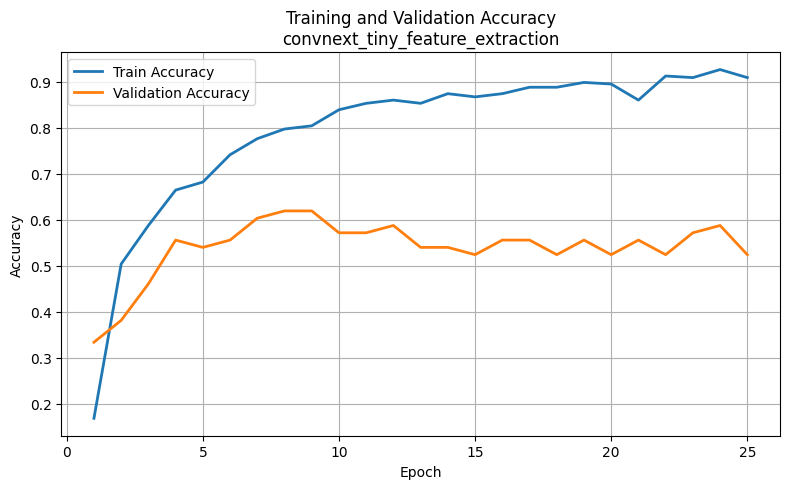

✓ Τα διαγράμματα εκπαίδευσης δημιουργήθηκαν επιτυχώς.


In [55]:
# =============================================================================
# 12.7 ΟΠΤΙΚΟΠΟΙΗΣΗ ΤΗΣ ΠΟΡΕΙΑΣ ΕΚΠΑΙΔΕΥΣΗΣ
# =============================================================================

plot_training_history(
    history=training_history,
    experiment_name=EXPERIMENT_NAME,
    results_dir=EXPERIMENT_RESULTS_DIR,
    save_plots=True
)

## Φόρτωση και έλεγχος του καλύτερου checkpoint

Κατά τη διάρκεια της εκπαίδευσης αποθηκεύεται το checkpoint που
αντιστοιχεί στην καλύτερη επίδοση στο validation set.

Πριν από την τελική αξιολόγηση στο test set φορτώνεται ξανά το συγκεκριμένο
checkpoint, ώστε η αξιολόγηση να πραγματοποιηθεί χρησιμοποιώντας την
καλύτερη έκδοση του μοντέλου και όχι απαραίτητα την κατάσταση της τελευταίας
εποχής εκπαίδευσης.

Παράλληλα πραγματοποιούνται έλεγχοι για την εγκυρότητα του checkpoint και
τη συμφωνία των αποθηκευμένων κλάσεων με τις κλάσεις του dataset.

In [56]:
# =============================================================================
# 12.8 ΦΟΡΤΩΣΗ ΚΑΙ ΕΛΕΓΧΟΣ ΤΟΥ ΚΑΛΥΤΕΡΟΥ CHECKPOINT
# =============================================================================

if not BEST_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Δεν βρέθηκε το checkpoint:\n{BEST_CHECKPOINT_PATH}"
    )


best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)


# -----------------------------------------------------------------------------
# Έλεγχος απαιτούμενων πεδίων
# -----------------------------------------------------------------------------

required_checkpoint_keys = [
    "experiment_name",
    "epoch",
    "model_state_dict",
    "validation_loss",
    "validation_accuracy",
    "class_names",
    "class_to_idx",
    "image_size"
]

missing_checkpoint_keys = [
    key
    for key in required_checkpoint_keys
    if key not in best_checkpoint
]

if missing_checkpoint_keys:
    raise KeyError(
        "Λείπουν πεδία από το checkpoint: "
        f"{missing_checkpoint_keys}"
    )


# -----------------------------------------------------------------------------
# Έλεγχος πειράματος
# -----------------------------------------------------------------------------

if (
    best_checkpoint["experiment_name"]
    != EXPERIMENT_NAME
):
    raise ValueError(
        "Το checkpoint ανήκει σε διαφορετικό πείραμα."
    )


# -----------------------------------------------------------------------------
# Έλεγχος κλάσεων
# -----------------------------------------------------------------------------

if (
    best_checkpoint["class_names"]
    != CLASS_NAMES
):
    raise ValueError(
        "Οι κλάσεις του checkpoint δεν συμφωνούν "
        "με τις κλάσεις του dataset."
    )


# -----------------------------------------------------------------------------
# Φόρτωση καλύτερων βαρών
# -----------------------------------------------------------------------------

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model = model.to(
    DEVICE
)

model.eval()


# -----------------------------------------------------------------------------
# Εμφάνιση πληροφοριών
# -----------------------------------------------------------------------------

print("=" * 70)
print("ΚΑΛΥΤΕΡΟ CHECKPOINT")
print("=" * 70)

print(
    f"Experiment             : "
    f"{best_checkpoint['experiment_name']}"
)

print(
    f"Best epoch             : "
    f"{best_checkpoint['epoch']}"
)

print(
    f"Validation loss        : "
    f"{best_checkpoint['validation_loss']:.4f}"
)

print(
    f"Validation accuracy    : "
    f"{best_checkpoint['validation_accuracy']:.4f}"
)

print(
    f"Checkpoint path        : "
    f"{BEST_CHECKPOINT_PATH}"
)

print("\n✓ Το καλύτερο checkpoint φορτώθηκε επιτυχώς.")

ΚΑΛΥΤΕΡΟ CHECKPOINT
Experiment             : convnext_tiny_feature_extraction
Best epoch             : 24
Validation loss        : 1.1497
Validation accuracy    : 0.5873
Checkpoint path        : /content/drive/MyDrive/ptyxiaki/models/checkpoints/convnext_tiny_feature_extraction/best_checkpoint.pth

✓ Το καλύτερο checkpoint φορτώθηκε επιτυχώς.


## Τελική αξιολόγηση στο test set

Μετά τη φόρτωση του καλύτερου checkpoint, το μοντέλο αξιολογείται στο
ανεξάρτητο test set.

Το test set δεν χρησιμοποιείται κατά τη διαδικασία εκπαίδευσης ή επιλογής
του καλύτερου checkpoint και χρησιμοποιείται αποκλειστικά για την τελική
εκτίμηση της ικανότητας γενίκευσης του μοντέλου.

Για την αξιολόγηση υπολογίζονται οι μετρικές Accuracy, Macro Precision,
Macro Recall, Macro F1-score και Weighted F1-score. Παράλληλα δημιουργούνται
το classification report και ο πίνακας σύγχυσης, ώστε να εξεταστεί
αναλυτικότερα η συμπεριφορά του μοντέλου στις επιμέρους γεωγραφικές
κατηγορίες.

Για τον τελικό στόχο της εφαρμογής ιδιαίτερη σημασία δίνεται στο Accuracy,
καθώς εκφράζει το ποσοστό των περιπτώσεων στις οποίες η πραγματική περιοχή
κατατάσσεται ως πρώτη πρόβλεψη του μοντέλου.

TEST SET RESULTS — convnext_tiny_feature_extraction
Accuracy          : 0.5645
Top-3 Accuracy    : 0.9194
Macro Precision   : 0.5963
Macro Recall      : 0.5556
Macro F1-score    : 0.5659
Weighted F1-score : 0.5717

CLASSIFICATION REPORT
               precision    recall  f1-score   support

      ipeiros     0.3750    0.4286    0.4000         7
        kriti     1.0000    0.6667    0.8000         6
    makedonia     0.6667    0.7500    0.7059         8
nisia_aigaiou     0.5000    0.3750    0.4286         8
 nisia_ioniou     0.8000    0.6667    0.7273         6
 peloponnisos     0.4000    0.5714    0.4706         7
sterea_ellada     0.2500    0.3333    0.2857         6
    thessalia     0.5000    0.3333    0.4000         6
       thraki     0.8750    0.8750    0.8750         8

     accuracy                         0.5645        62
    macro avg     0.5963    0.5556    0.5659        62
 weighted avg     0.5977    0.5645    0.5717        62



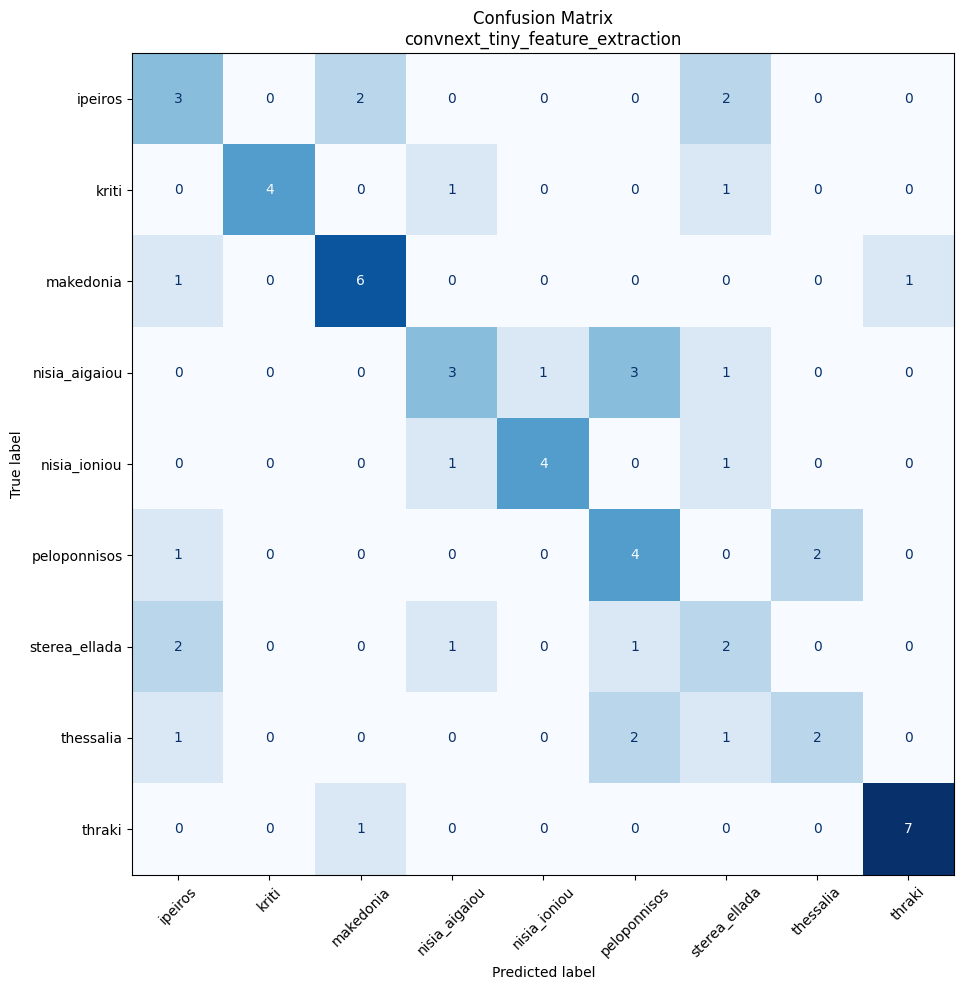


Αποθηκεύτηκαν:
Metrics              : /content/drive/MyDrive/ptyxiaki/results/convnext_tiny_feature_extraction/test_metrics.json
Classification report: /content/drive/MyDrive/ptyxiaki/results/convnext_tiny_feature_extraction/classification_report.json
Predictions          : /content/drive/MyDrive/ptyxiaki/results/convnext_tiny_feature_extraction/test_predictions.npz
Confusion matrix     : /content/drive/MyDrive/ptyxiaki/results/convnext_tiny_feature_extraction/confusion_matrix.png


In [57]:
# =============================================================================
# 12.9 ΤΕΛΙΚΗ ΑΞΙΟΛΟΓΗΣΗ ΣΤΟ TEST SET
# =============================================================================

test_metrics = evaluate_model_on_test_set(
    model=model,
    test_loader=test_loader,
    class_names=CLASS_NAMES,
    experiment_name=EXPERIMENT_NAME,
    results_dir=EXPERIMENT_RESULTS_DIR,
    save_results=True
)

## Αποθήκευση του τελικού μοντέλου

Μετά την ολοκλήρωση της αξιολόγησης αποθηκεύεται το τελικό μοντέλο στον
αντίστοιχο φάκελο των εκπαιδευμένων μοντέλων.

Το αποθηκευμένο αρχείο περιλαμβάνει τα βάρη του καλύτερου μοντέλου και τις
απαραίτητες πληροφορίες για τη μελλοντική επαναφόρτωση και χρήση του.

Με αυτόν τον τρόπο το μοντέλο μπορεί να χρησιμοποιηθεί αργότερα για
inference χωρίς να απαιτείται νέα διαδικασία εκπαίδευσης.

In [58]:
# =============================================================================
# 12.10 ΑΠΟΘΗΚΕΥΣΗ ΤΕΛΙΚΟΥ ΜΟΝΤΕΛΟΥ
# =============================================================================

save_final_model(
    model=model,
    experiment_name=EXPERIMENT_NAME,
    model_path=FINAL_MODEL_PATH,
    test_metrics=test_metrics
)

✓ Το τελικό μοντέλο αποθηκεύτηκε επιτυχώς.
Model path: /content/drive/MyDrive/ptyxiaki/models/trained/convnext_tiny_feature_extraction/convnext_tiny_feature_extraction.pth


## Τελική σύνοψη πειράματος

Στο τελευταίο στάδιο συγκεντρώνονται οι σημαντικότερες πληροφορίες του
πειράματος σε ένα ενιαίο αρχείο σύνοψης.

Καταγράφονται η αρχιτεκτονική και η μέθοδος Transfer Learning, οι
υπερπαράμετροι, ο αριθμός των παραμέτρων του μοντέλου, τα στοιχεία της
εκπαίδευσης και οι τελικές μετρικές αξιολόγησης στο test set.

Η συγκεντρωτική αποθήκευση των πληροφοριών διευκολύνει την αναπαραγωγή των
πειραμάτων και την άμεση σύγκριση του ConvNeXt-Tiny με τα υπόλοιπα μοντέλα
που εξετάζονται στην εργασία.

In [59]:
# =============================================================================
# 12.11 ΤΕΛΙΚΗ ΣΥΝΟΨΗ ΠΕΙΡΑΜΑΤΟΣ
# =============================================================================

parameter_counts = count_model_parameters(
    model
)


experiment_summary = {
    "experiment_name": EXPERIMENT_NAME,
    "model_architecture": MODEL_ARCHITECTURE,
    "transfer_learning_mode": TRANSFER_LEARNING_MODE,

    "dataset": {
        "number_of_classes": int(NUM_CLASSES),
        "class_names": list(CLASS_NAMES),
        "image_size": int(IMAGE_SIZE),
        "batch_size": int(BATCH_SIZE)
    },

    "hyperparameters": {
        "learning_rate": float(
            EXPERIMENT_LEARNING_RATE
        ),
        "weight_decay": float(
            EXPERIMENT_WEIGHT_DECAY
        ),
        "maximum_epochs": int(
            MAX_EPOCHS
        ),
        "early_stopping_patience": int(
            EARLY_STOPPING_PATIENCE
        ),
        "optimizer": optimizer.__class__.__name__,
        "criterion": criterion.__class__.__name__
    },

    "parameters": {
        "total_parameters": int(
            parameter_counts["total_parameters"]
        ),
        "trainable_parameters": int(
            parameter_counts["trainable_parameters"]
        ),
        "frozen_parameters": int(
            parameter_counts["frozen_parameters"]
        )
    },

    "training": {
        "training_time_seconds": float(
            training_information["training_time_seconds"]
        ),
        "epochs_completed": int(
            training_information["epochs_completed"]
        ),
        "best_epoch": int(
            training_information["best_epoch"]
        ),
        "best_validation_loss": float(
            training_information["best_validation_loss"]
        ),
        "best_validation_accuracy": float(
            training_information["best_validation_accuracy"]
        )
    },

    "test_metrics": {
        "accuracy": float(
            test_metrics["accuracy"]
        ),
        "macro_precision": float(
            test_metrics["macro_precision"]
        ),
        "macro_recall": float(
            test_metrics["macro_recall"]
        ),
        "macro_f1": float(
            test_metrics["macro_f1"]
        ),
        "weighted_f1": float(
            test_metrics["weighted_f1"]
        )
    },

    "saved_files": {
        "best_checkpoint": str(
            BEST_CHECKPOINT_PATH
        ),
        "final_model": str(
            FINAL_MODEL_PATH
        ),
        "results_directory": str(
            EXPERIMENT_RESULTS_DIR
        )
    }
}


# -----------------------------------------------------------------------------
# Αποθήκευση JSON
# -----------------------------------------------------------------------------

save_json_file(
    data=experiment_summary,
    file_path=EXPERIMENT_SUMMARY_PATH
)


# -----------------------------------------------------------------------------
# Εμφάνιση τελικής σύνοψης
# -----------------------------------------------------------------------------

print("=" * 80)
print("ΤΕΛΙΚΗ ΣΥΝΟΨΗ — ΠΕΙΡΑΜΑ 5")
print("=" * 80)

print(f"Experiment                  : {EXPERIMENT_NAME}")
print(f"Architecture                : {MODEL_ARCHITECTURE}")
print(f"Transfer learning           : {TRANSFER_LEARNING_MODE}")

print("\nModel parameters:")

print(
    f"Total parameters            : "
    f"{parameter_counts['total_parameters']:,}"
)

print(
    f"Trainable parameters        : "
    f"{parameter_counts['trainable_parameters']:,}"
)

print(
    f"Frozen parameters           : "
    f"{parameter_counts['frozen_parameters']:,}"
)


print("\nTraining:")

print(
    f"Epochs completed            : "
    f"{training_information['epochs_completed']}"
)

print(
    f"Best epoch                  : "
    f"{training_information['best_epoch']}"
)

print(
    f"Best validation loss        : "
    f"{training_information['best_validation_loss']:.4f}"
)

print(
    f"Best validation accuracy    : "
    f"{training_information['best_validation_accuracy']:.4f}"
)

print(
    f"Training time               : "
    f"{training_information['training_time_seconds']:.2f} seconds"
)


print("\nTest set:")

print(
    f"Accuracy                    : "
    f"{test_metrics['accuracy']:.4f}"
)

print(
    f"Macro Precision             : "
    f"{test_metrics['macro_precision']:.4f}"
)

print(
    f"Macro Recall                : "
    f"{test_metrics['macro_recall']:.4f}"
)

print(
    f"Macro F1-score              : "
    f"{test_metrics['macro_f1']:.4f}"
)

print(
    f"Weighted F1-score           : "
    f"{test_metrics['weighted_f1']:.4f}"
)


print("\nSaved files:")

print(
    f"Best checkpoint             : "
    f"{BEST_CHECKPOINT_PATH}"
)

print(
    f"Final model                 : "
    f"{FINAL_MODEL_PATH}"
)

print(
    f"Experiment summary          : "
    f"{EXPERIMENT_SUMMARY_PATH}"
)

print("\n" + "=" * 80)
print("✓ ΤΟ ΠΕΙΡΑΜΑ 5 ΟΛΟΚΛΗΡΩΘΗΚΕ ΕΠΙΤΥΧΩΣ")
print("=" * 80)

ΤΕΛΙΚΗ ΣΥΝΟΨΗ — ΠΕΙΡΑΜΑ 5
Experiment                  : convnext_tiny_feature_extraction
Architecture                : ConvNeXt-Tiny
Transfer learning           : Feature Extraction

Model parameters:
Total parameters            : 27,827,049
Trainable parameters        : 6,921
Frozen parameters           : 27,820,128

Training:
Epochs completed            : 25
Best epoch                  : 24
Best validation loss        : 1.1497
Best validation accuracy    : 0.5873
Training time               : 137.61 seconds

Test set:
Accuracy                    : 0.5645
Macro Precision             : 0.5963
Macro Recall                : 0.5556
Macro F1-score              : 0.5659
Weighted F1-score           : 0.5717

Saved files:
Best checkpoint             : /content/drive/MyDrive/ptyxiaki/models/checkpoints/convnext_tiny_feature_extraction/best_checkpoint.pth
Final model                 : /content/drive/MyDrive/ptyxiaki/models/trained/convnext_tiny_feature_extraction/convnext_tiny_feature_extractio

# ΠΕΙΡΑΜΑ 6 — ConvNeXt-Tiny Partial Fine-Tuning

Στο έκτο πείραμα χρησιμοποιείται το προεκπαιδευμένο μοντέλο ConvNeXt-Tiny
με τη μέθοδο Partial Fine-Tuning.

Σε αντίθεση με το προηγούμενο πείραμα Feature Extraction, στο οποίο
εκπαιδευόταν αποκλειστικά το νέο τελικό επίπεδο ταξινόμησης, στο παρόν
πείραμα επιτρέπεται η προσαρμογή και μέρους των προεκπαιδευμένων
χαρακτηριστικών του μοντέλου.

Συγκεκριμένα, ξεπαγώνει το τελευταίο τμήμα του feature extractor και το
τελικό classification layer, ενώ τα υπόλοιπα επίπεδα παραμένουν παγωμένα.

Χρησιμοποιείται μικρότερο learning rate, ώστε να περιοριστούν οι μεγάλες
μεταβολές στα προεκπαιδευμένα βάρη.

Στόχος είναι να εξεταστεί αν η προσαρμογή των τελευταίων επιπέδων του
ConvNeXt-Tiny στο συγκεκριμένο dataset μπορεί να βελτιώσει την απόδοση
σε σχέση με το Feature Extraction.

## Ρυθμίσεις πειράματος

Ορίζονται το όνομα του πειράματος, η αρχιτεκτονική του μοντέλου και η
μέθοδος Transfer Learning.

Για το Partial Fine-Tuning χρησιμοποιείται learning rate ίσο με 1e-4,
καθώς εκπαιδεύονται τόσο νέες όσο και προεκπαιδευμένες παράμετροι.

Δημιουργούνται ξεχωριστοί φάκελοι για τα αποτελέσματα, τα checkpoints
και το τελικό εκπαιδευμένο μοντέλο.

In [105]:
# =============================================================================
# 13.2 ΡΥΘΜΙΣΕΙΣ ΠΕΙΡΑΜΑΤΟΣ
# =============================================================================

EXPERIMENT_NAME = "convnext_tiny_partial_fine_tuning"

MODEL_ARCHITECTURE = "ConvNeXt-Tiny"

TRANSFER_LEARNING_MODE = (
    "Partial Fine-Tuning (last feature stage + classifier)"
)

LEARNING_RATE = 1e-4

WEIGHT_DECAY = DEFAULT_WEIGHT_DECAY


# -----------------------------------------------------------------------------
# Δημιουργία φακέλων πειράματος
# -----------------------------------------------------------------------------

experiment_paths = create_experiment_directories(
    EXPERIMENT_NAME
)

EXPERIMENT_RESULTS_DIR = (
    experiment_paths["results_dir"]
)

EXPERIMENT_CHECKPOINT_DIR = (
    experiment_paths["checkpoint_dir"]
)

EXPERIMENT_TRAINED_MODEL_DIR = (
    experiment_paths["trained_model_dir"]
)


# -----------------------------------------------------------------------------
# Διαδρομές αρχείων
# -----------------------------------------------------------------------------

BEST_CHECKPOINT_PATH = (
    EXPERIMENT_CHECKPOINT_DIR
    / "best_checkpoint.pth"
)

FINAL_MODEL_PATH = (
    EXPERIMENT_TRAINED_MODEL_DIR
    / "convnext_tiny_partial_fine_tuning.pth"
)

EXPERIMENT_SUMMARY_PATH = (
    EXPERIMENT_RESULTS_DIR
    / "experiment_summary.json"
)


# -----------------------------------------------------------------------------
# Εμφάνιση ρυθμίσεων
# -----------------------------------------------------------------------------

print("=" * 70)
print("ΠΕΙΡΑΜΑ 6 — CONVNEXT-TINY PARTIAL FINE-TUNING")
print("=" * 70)

print(f"Experiment name       : {EXPERIMENT_NAME}")
print(f"Model architecture    : {MODEL_ARCHITECTURE}")
print(f"Transfer learning     : {TRANSFER_LEARNING_MODE}")

print("\nOptimization:")
print(f"Learning rate         : {LEARNING_RATE}")
print(f"Weight decay          : {WEIGHT_DECAY}")
print(f"Maximum epochs        : {MAX_EPOCHS}")
print(f"Early stopping        : {EARLY_STOPPING_PATIENCE}")

print("\nDirectories:")
print(f"Results               : {EXPERIMENT_RESULTS_DIR}")
print(f"Checkpoints           : {EXPERIMENT_CHECKPOINT_DIR}")
print(f"Trained models        : {EXPERIMENT_TRAINED_MODEL_DIR}")

print("\nFiles:")
print(f"Best checkpoint       : {BEST_CHECKPOINT_PATH}")
print(f"Final model           : {FINAL_MODEL_PATH}")
print(f"Experiment summary    : {EXPERIMENT_SUMMARY_PATH}")

ΠΕΙΡΑΜΑ 6 — CONVNEXT-TINY PARTIAL FINE-TUNING
Experiment name       : convnext_tiny_partial_fine_tuning
Model architecture    : ConvNeXt-Tiny
Transfer learning     : Partial Fine-Tuning (last feature stage + classifier)

Optimization:
Learning rate         : 0.0001
Weight decay          : 0.0001
Maximum epochs        : 25
Early stopping        : 5

Directories:
Results               : /content/drive/MyDrive/ptyxiaki/results/convnext_tiny_partial_fine_tuning
Checkpoints           : /content/drive/MyDrive/ptyxiaki/models/checkpoints/convnext_tiny_partial_fine_tuning
Trained models        : /content/drive/MyDrive/ptyxiaki/models/trained/convnext_tiny_partial_fine_tuning

Files:
Best checkpoint       : /content/drive/MyDrive/ptyxiaki/models/checkpoints/convnext_tiny_partial_fine_tuning/best_checkpoint.pth
Final model           : /content/drive/MyDrive/ptyxiaki/models/trained/convnext_tiny_partial_fine_tuning/convnext_tiny_partial_fine_tuning.pth
Experiment summary    : /content/drive/MyDri

##Δημιουργία του μοντέλου ConvNeXt-Tiny

Φορτώνεται το ConvNeXt-Tiny με προεκπαιδευμένα βάρη.

Αρχικά παγώνουν όλες οι παράμετροι του μοντέλου. Στη συνέχεια ξεπαγώνει
το τελευταίο τμήμα του feature extractor, ώστε τα χαρακτηριστικά υψηλού
επιπέδου να μπορούν να προσαρμοστούν στις εικόνες των παραδοσιακών
φορεσιών.

Το αρχικό classification layer αντικαθίσταται από νέο γραμμικό επίπεδο
με εννέα εξόδους, μία για κάθε γεωγραφική περιοχή του dataset.

Με αυτόν τον τρόπο το μεγαλύτερο μέρος του προεκπαιδευμένου μοντέλου
παραμένει σταθερό, ενώ τα τελευταία επίπεδα προσαρμόζονται στο
συγκεκριμένο πρόβλημα ταξινόμησης.

In [106]:
# =============================================================================
# 13.3 ΔΗΜΙΟΥΡΓΙΑ CONVNEXT-TINY ΓΙΑ PARTIAL FINE-TUNING
# =============================================================================

import torch.nn as nn

from torchvision.models import (
    ConvNeXt_Tiny_Weights,
    convnext_tiny
)


# -----------------------------------------------------------------------------
# Φόρτωση προεκπαιδευμένων βαρών
# -----------------------------------------------------------------------------

convnext_weights = ConvNeXt_Tiny_Weights.DEFAULT

model = convnext_tiny(
    weights=convnext_weights
)


# -----------------------------------------------------------------------------
# Πάγωμα όλων των παραμέτρων
# -----------------------------------------------------------------------------

for parameter in model.parameters():
    parameter.requires_grad = False


# -----------------------------------------------------------------------------
# Ξεπάγωμα του τελευταίου feature stage
# -----------------------------------------------------------------------------

for parameter in model.features[-1].parameters():
    parameter.requires_grad = True


# -----------------------------------------------------------------------------
# Αντικατάσταση του τελικού classification layer
# -----------------------------------------------------------------------------

classifier_input_features = (
    model.classifier[2].in_features
)

model.classifier[2] = nn.Linear(
    in_features=classifier_input_features,
    out_features=NUM_CLASSES
)


# -----------------------------------------------------------------------------
# Επιβεβαίωση ότι ο classifier είναι εκπαιδεύσιμος
# -----------------------------------------------------------------------------

for parameter in model.classifier.parameters():
    parameter.requires_grad = True


# -----------------------------------------------------------------------------
# Μεταφορά στη διαθέσιμη συσκευή
# -----------------------------------------------------------------------------

model = model.to(
    DEVICE
)


# -----------------------------------------------------------------------------
# Έλεγχος εκπαιδεύσιμων παραμέτρων
# -----------------------------------------------------------------------------

trainable_parameter_names = [
    parameter_name
    for parameter_name, parameter in model.named_parameters()
    if parameter.requires_grad
]


# -----------------------------------------------------------------------------
# Εμφάνιση εκπαιδεύσιμων παραμέτρων
# -----------------------------------------------------------------------------

print("=" * 70)
print("ΕΚΠΑΙΔΕΥΣΙΜΕΣ ΠΑΡΑΜΕΤΡΟΙ")
print("=" * 70)

for parameter_name in trainable_parameter_names:
    print(parameter_name)

print("\nΣυνολικό πλήθος εκπαιδεύσιμων tensors:")
print(len(trainable_parameter_names))


# -----------------------------------------------------------------------------
# Σύνοψη μοντέλου
# -----------------------------------------------------------------------------

print_model_summary(
    model=model,
    experiment_name=EXPERIMENT_NAME,
    transfer_learning_mode=TRANSFER_LEARNING_MODE
)


# -----------------------------------------------------------------------------
# Έλεγχος εξόδου μοντέλου
# -----------------------------------------------------------------------------

validate_model_output(
    model=model,
    batch_size=BATCH_SIZE
)

ΕΚΠΑΙΔΕΥΣΙΜΕΣ ΠΑΡΑΜΕΤΡΟΙ
features.7.0.layer_scale
features.7.0.block.0.weight
features.7.0.block.0.bias
features.7.0.block.2.weight
features.7.0.block.2.bias
features.7.0.block.3.weight
features.7.0.block.3.bias
features.7.0.block.5.weight
features.7.0.block.5.bias
features.7.1.layer_scale
features.7.1.block.0.weight
features.7.1.block.0.bias
features.7.1.block.2.weight
features.7.1.block.2.bias
features.7.1.block.3.weight
features.7.1.block.3.bias
features.7.1.block.5.weight
features.7.1.block.5.bias
features.7.2.layer_scale
features.7.2.block.0.weight
features.7.2.block.0.bias
features.7.2.block.2.weight
features.7.2.block.2.bias
features.7.2.block.3.weight
features.7.2.block.3.bias
features.7.2.block.5.weight
features.7.2.block.5.bias
classifier.0.weight
classifier.0.bias
classifier.2.weight
classifier.2.bias

Συνολικό πλήθος εκπαιδεύσιμων tensors:
31
ΣΥΝΟΨΗ ΜΟΝΤΕΛΟΥ
Experiment name            : convnext_tiny_partial_fine_tuning
Model class                : ConvNeXt
Transfer learnin

## Συνάρτηση κόστους και αλγόριθμος βελτιστοποίησης

Για την εκπαίδευση χρησιμοποιείται η Cross-Entropy Loss, η οποία είναι
κατάλληλη για το πρόβλημα πολυταξικής ταξινόμησης.

Ως optimizer χρησιμοποιείται ο Adam.

Σε αντίθεση με το Feature Extraction, ο optimizer περιλαμβάνει όλες τις
εκπαιδεύσιμες παραμέτρους του τελευταίου feature stage και του νέου
classification layer.

Χρησιμοποιείται learning rate ίσο με 1e-4, ώστε η προσαρμογή των
προεκπαιδευμένων παραμέτρων να πραγματοποιείται με μικρά βήματα.

In [107]:
# =============================================================================
# 13.4 ΣΥΝΑΡΤΗΣΗ ΚΟΣΤΟΥΣ ΚΑΙ OPTIMIZER
# =============================================================================

import torch.optim as optim

criterion = nn.CrossEntropyLoss()


# -----------------------------------------------------------------------------
# Επιλογή εκπαιδεύσιμων παραμέτρων
# -----------------------------------------------------------------------------

trainable_parameters = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]

if len(trainable_parameters) == 0:
    raise ValueError(
        "Δεν βρέθηκαν εκπαιδεύσιμες παράμετροι."
    )


# -----------------------------------------------------------------------------
# Δημιουργία optimizer
# -----------------------------------------------------------------------------

optimizer = optim.Adam(
    params=trainable_parameters,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# -----------------------------------------------------------------------------
# Έλεγχος optimizer
# -----------------------------------------------------------------------------

optimizer_parameter_count = sum(
    parameter.numel()
    for parameter_group in optimizer.param_groups
    for parameter in parameter_group["params"]
)

model_trainable_parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

if (
    optimizer_parameter_count
    != model_trainable_parameter_count
):
    raise ValueError(
        "Ο optimizer δεν περιλαμβάνει ακριβώς όλες "
        "τις εκπαιδεύσιμες παραμέτρους."
    )


# -----------------------------------------------------------------------------
# Εμφάνιση ρυθμίσεων
# -----------------------------------------------------------------------------

print("=" * 70)
print("ΣΥΝΑΡΤΗΣΗ ΚΟΣΤΟΥΣ ΚΑΙ OPTIMIZER")
print("=" * 70)

print(
    f"Loss function          : "
    f"{criterion.__class__.__name__}"
)

print(
    f"Optimizer              : "
    f"{optimizer.__class__.__name__}"
)

print(
    f"Learning rate          : "
    f"{LEARNING_RATE}"
)

print(
    f"Weight decay           : "
    f"{WEIGHT_DECAY}"
)

print(
    f"Trainable parameters   : "
    f"{optimizer_parameter_count:,}"
)

ΣΥΝΑΡΤΗΣΗ ΚΟΣΤΟΥΣ ΚΑΙ OPTIMIZER
Loss function          : CrossEntropyLoss
Optimizer              : Adam
Learning rate          : 0.0001
Weight decay           : 0.0001
Trainable parameters   : 14,297,865


## Εκπαίδευση του μοντέλου

Το ConvNeXt-Tiny εκπαιδεύεται χρησιμοποιώντας το training set και
αξιολογείται στο validation set μετά από κάθε εποχή.

Η διαδικασία εκπαίδευσης χρησιμοποιεί Early Stopping, ώστε να περιορίζεται
η υπερπροσαρμογή του μοντέλου στο μικρό σχετικά μέγεθος του dataset.

Κατά τη διάρκεια της εκπαίδευσης αποθηκεύεται το checkpoint που
παρουσιάζει την καλύτερη επίδοση στο validation set.

In [108]:
# =============================================================================
# 13.5 ΕΚΠΑΙΔΕΥΣΗ ΜΟΝΤΕΛΟΥ
# =============================================================================

model, training_history, training_information = train_model(
    model=model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    criterion=criterion,
    optimizer=optimizer,
    experiment_name=EXPERIMENT_NAME,
    checkpoint_path=BEST_CHECKPOINT_PATH,
    max_epochs=MAX_EPOCHS,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    scheduler=None
)

ΕΝΑΡΞΗ ΕΚΠΑΙΔΕΥΣΗΣ — convnext_tiny_partial_fine_tuning

Epoch [1/25]
Learning Rate       : 0.00010000
Train Loss          : 2.2016
Validation Loss     : 2.0785
Train Accuracy      : 0.1154
Validation Accuracy : 0.2698
Epoch Time          : 5.31 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [2/25]
Learning Rate       : 0.00010000
Train Loss          : 1.8804
Validation Loss     : 1.8562
Train Accuracy      : 0.4266
Validation Accuracy : 0.4444
Epoch Time          : 4.21 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [3/25]
Learning Rate       : 0.00010000
Train Loss          : 1.4380
Validation Loss     : 1.6140
Train Accuracy      : 0.6643
Validation Accuracy : 0.5714
Epoch Time          : 4.16 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoch [4/25]
Learning Rate       : 0.00010000
Train Loss          : 1.0382
Validation Loss     : 1.4328
Train Accuracy      : 0.8252
Validation Accuracy : 0.5714
Epoch Time          : 6.00 seconds
✓ Αποθηκεύτηκε νέο καλύτερο μοντέλο.

Epoc

## Αποθήκευση αποτελεσμάτων εκπαίδευσης

Μετά την ολοκλήρωση της εκπαίδευσης αποθηκεύονται οι πληροφορίες του
ιστορικού εκπαίδευσης και τα βασικά στοιχεία της διαδικασίας.

Η αποθήκευση επιτρέπει την αναπαραγωγή και την ανάλυση του πειράματος
χωρίς να απαιτείται εκ νέου εκπαίδευση του μοντέλου.

In [109]:
# =============================================================================
# 13.6 ΑΠΟΘΗΚΕΥΣΗ ΑΠΟΤΕΛΕΣΜΑΤΩΝ ΕΚΠΑΙΔΕΥΣΗΣ
# =============================================================================

save_training_results(
    history=training_history,
    training_information=training_information,
    results_dir=EXPERIMENT_RESULTS_DIR
)

✓ Αποθηκεύτηκαν τα αποτελέσματα εκπαίδευσης.
Training history     : /content/drive/MyDrive/ptyxiaki/results/convnext_tiny_partial_fine_tuning/training_history.json
Training information : /content/drive/MyDrive/ptyxiaki/results/convnext_tiny_partial_fine_tuning/training_information.json


##Οπτικοποίηση της πορείας εκπαίδευσης

Δημιουργούνται διαγράμματα που παρουσιάζουν την εξέλιξη της συνάρτησης
απώλειας και της ακρίβειας στο training και validation set.

Τα διαγράμματα χρησιμοποιούνται για την αξιολόγηση της σύγκλισης του
μοντέλου και τον εντοπισμό πιθανών φαινομένων υπερπροσαρμογής.

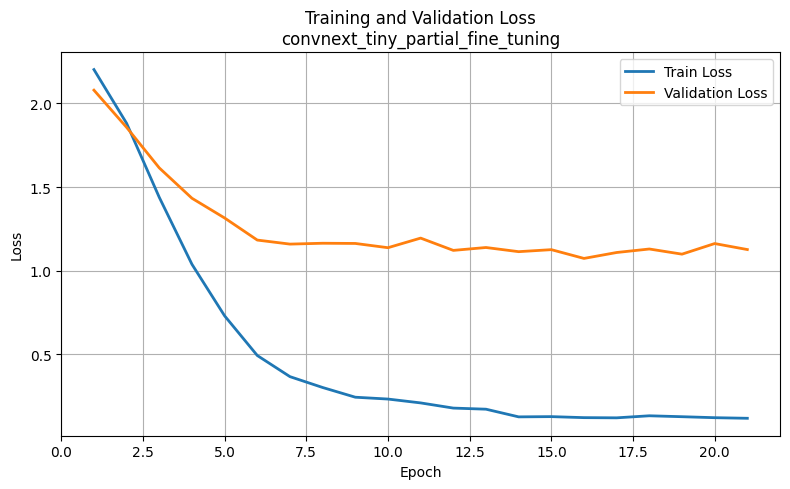

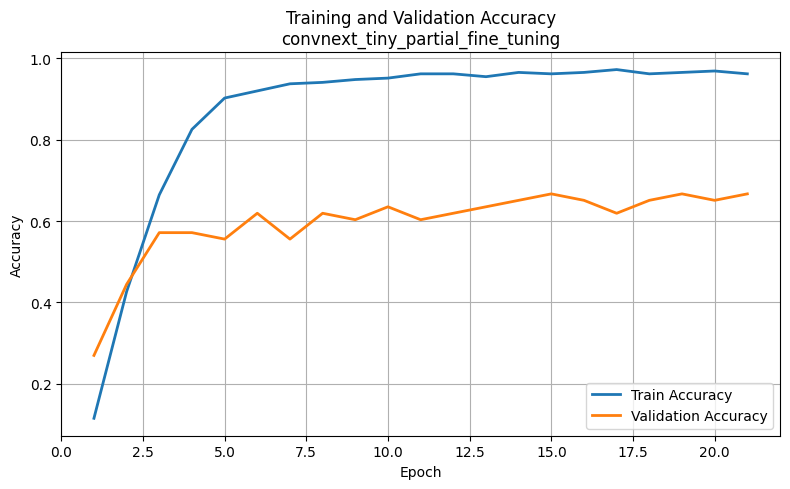

✓ Τα διαγράμματα εκπαίδευσης δημιουργήθηκαν επιτυχώς.


In [110]:
# =============================================================================
# 13.7 ΟΠΤΙΚΟΠΟΙΗΣΗ ΤΗΣ ΠΟΡΕΙΑΣ ΕΚΠΑΙΔΕΥΣΗΣ
# =============================================================================

plot_training_history(
    history=training_history,
    experiment_name=EXPERIMENT_NAME,
    results_dir=EXPERIMENT_RESULTS_DIR,
    save_plots=True
)

##Φόρτωση του καλύτερου checkpoint

Πριν από την τελική αξιολόγηση στο test set φορτώνεται το checkpoint που
παρουσίασε την καλύτερη επίδοση στο validation set.

Με αυτόν τον τρόπο η τελική αξιολόγηση πραγματοποιείται χρησιμοποιώντας
την καλύτερη κατάσταση του μοντέλου κατά τη διάρκεια της εκπαίδευσης.

In [111]:
# =============================================================================
# 13.8 ΦΟΡΤΩΣΗ ΤΟΥ ΚΑΛΥΤΕΡΟΥ CHECKPOINT
# =============================================================================

if not BEST_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        "Δεν βρέθηκε το καλύτερο checkpoint:\n"
        f"{BEST_CHECKPOINT_PATH}"
    )


checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)


# -----------------------------------------------------------------------------
# Έλεγχος checkpoint
# -----------------------------------------------------------------------------

required_checkpoint_keys = [
    "experiment_name",
    "epoch",
    "model_state_dict",
    "validation_loss",
    "validation_accuracy",
    "class_names",
    "class_to_idx",
    "image_size"
]

missing_checkpoint_keys = [
    key
    for key in required_checkpoint_keys
    if key not in checkpoint
]

if missing_checkpoint_keys:
    raise KeyError(
        "Λείπουν πεδία από το checkpoint: "
        f"{missing_checkpoint_keys}"
    )


if checkpoint["experiment_name"] != EXPERIMENT_NAME:
    raise ValueError(
        "Το checkpoint ανήκει σε διαφορετικό πείραμα."
    )


if checkpoint["class_names"] != CLASS_NAMES:
    raise ValueError(
        "Οι κλάσεις του checkpoint δεν συμφωνούν "
        "με τις κλάσεις του dataset."
    )


# -----------------------------------------------------------------------------
# Φόρτωση βαρών
# -----------------------------------------------------------------------------

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(
    DEVICE
)

model.eval()


# -----------------------------------------------------------------------------
# Εμφάνιση πληροφοριών
# -----------------------------------------------------------------------------

print("=" * 70)
print("ΚΑΛΥΤΕΡΟ CHECKPOINT")
print("=" * 70)

print(
    f"Experiment             : "
    f"{checkpoint['experiment_name']}"
)

print(
    f"Best epoch             : "
    f"{checkpoint['epoch']}"
)

print(
    f"Validation loss        : "
    f"{checkpoint['validation_loss']:.4f}"
)

print(
    f"Validation accuracy    : "
    f"{checkpoint['validation_accuracy']:.4f}"
)

print(
    f"Checkpoint path        : "
    f"{BEST_CHECKPOINT_PATH}"
)

print("\n✓ Το καλύτερο checkpoint φορτώθηκε επιτυχώς.")

ΚΑΛΥΤΕΡΟ CHECKPOINT
Experiment             : convnext_tiny_partial_fine_tuning
Best epoch             : 16
Validation loss        : 1.0733
Validation accuracy    : 0.6508
Checkpoint path        : /content/drive/MyDrive/ptyxiaki/models/checkpoints/convnext_tiny_partial_fine_tuning/best_checkpoint.pth

✓ Το καλύτερο checkpoint φορτώθηκε επιτυχώς.


## Τελική αξιολόγηση στο test set

Το μοντέλο αξιολογείται στο ανεξάρτητο test set χρησιμοποιώντας το
καλύτερο checkpoint που προέκυψε κατά την εκπαίδευση.

Υπολογίζονται οι Accuracy, Macro Precision, Macro Recall, Macro F1-score
και Weighted F1-score.

Η Accuracy αποτελεί την κύρια μετρική για την αξιολόγηση της εφαρμογής,
καθώς ο βασικός στόχος είναι η σωστή αναγνώριση της γεωγραφικής περιοχής
ως πρώτης πρόβλεψης.

TEST SET RESULTS — convnext_tiny_partial_fine_tuning
Accuracy          : 0.7097
Top-3 Accuracy    : 0.9194
Macro Precision   : 0.7306
Macro Recall      : 0.7083
Macro F1-score    : 0.7064
Weighted F1-score : 0.7056

CLASSIFICATION REPORT
               precision    recall  f1-score   support

      ipeiros     0.3750    0.4286    0.4000         7
        kriti     1.0000    0.8333    0.9091         6
    makedonia     0.6667    0.5000    0.5714         8
nisia_aigaiou     0.7778    0.8750    0.8235         8
 nisia_ioniou     0.7143    0.8333    0.7692         6
 peloponnisos     1.0000    0.5714    0.7273         7
sterea_ellada     0.6000    0.5000    0.5455         6
    thessalia     0.7143    0.8333    0.7692         6
       thraki     0.7273    1.0000    0.8421         8

     accuracy                         0.7097        62
    macro avg     0.7306    0.7083    0.7064        62
 weighted avg     0.7286    0.7097    0.7056        62



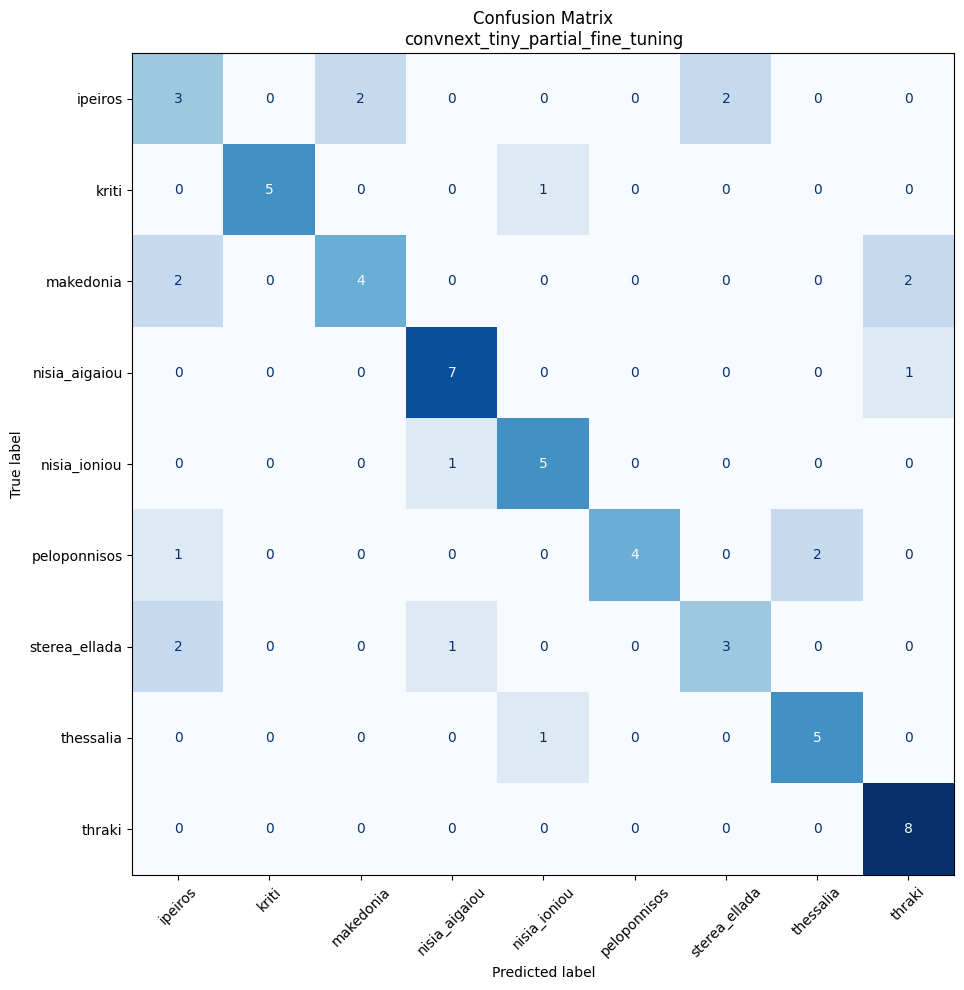


Αποθηκεύτηκαν:
Metrics              : /content/drive/MyDrive/ptyxiaki/results/convnext_tiny_partial_fine_tuning/test_metrics.json
Classification report: /content/drive/MyDrive/ptyxiaki/results/convnext_tiny_partial_fine_tuning/classification_report.json
Predictions          : /content/drive/MyDrive/ptyxiaki/results/convnext_tiny_partial_fine_tuning/test_predictions.npz
Confusion matrix     : /content/drive/MyDrive/ptyxiaki/results/convnext_tiny_partial_fine_tuning/confusion_matrix.png


In [112]:
# =============================================================================
# 13.9 ΑΞΙΟΛΟΓΗΣΗ ΣΤΟ TEST SET
# =============================================================================

test_metrics = evaluate_model_on_test_set(
    model=model,
    test_loader=test_loader,
    class_names=CLASS_NAMES,
    experiment_name=EXPERIMENT_NAME,
    results_dir=EXPERIMENT_RESULTS_DIR,
    save_results=True
)

## Αποθήκευση του τελικού μοντέλου

Μετά την τελική αξιολόγηση αποθηκεύεται το εκπαιδευμένο ConvNeXt-Tiny
στον αντίστοιχο φάκελο των εκπαιδευμένων μοντέλων.

Το αρχείο μπορεί να χρησιμοποιηθεί αργότερα για inference και για τη
σύνδεση του μοντέλου με την εφαρμογή αναγνώρισης παραδοσιακών φορεσιών.

In [113]:
# =============================================================================
# 13.10 ΑΠΟΘΗΚΕΥΣΗ ΤΕΛΙΚΟΥ ΜΟΝΤΕΛΟΥ
# =============================================================================

save_final_model(
    model=model,
    experiment_name=EXPERIMENT_NAME,
    model_path=FINAL_MODEL_PATH,
    test_metrics=test_metrics
)

✓ Το τελικό μοντέλο αποθηκεύτηκε επιτυχώς.
Model path: /content/drive/MyDrive/ptyxiaki/models/trained/convnext_tiny_partial_fine_tuning/convnext_tiny_partial_fine_tuning.pth


## Τελική σύνοψη πειράματος

Στο τελευταίο στάδιο συγκεντρώνονται τα βασικά στοιχεία του πειράματος
σε ένα ενιαίο αρχείο JSON.

Καταγράφονται η αρχιτεκτονική, η μέθοδος Transfer Learning, οι
υπερπαράμετροι, ο αριθμός των παραμέτρων, τα στοιχεία της εκπαίδευσης
και οι τελικές μετρικές αξιολόγησης στο test set.

Η πληροφορία αυτή χρησιμοποιείται για τη συγκριτική αξιολόγηση του
ConvNeXt-Tiny με τα υπόλοιπα μοντέλα της μελέτης.

In [114]:
# =============================================================================
# 13.11 ΤΕΛΙΚΗ ΣΥΝΟΨΗ ΠΕΙΡΑΜΑΤΟΣ
# =============================================================================

parameter_counts = count_model_parameters(
    model
)


experiment_summary = {
    "experiment_name": EXPERIMENT_NAME,
    "model_architecture": MODEL_ARCHITECTURE,
    "transfer_learning_mode": TRANSFER_LEARNING_MODE,

    "dataset": {
        "number_of_classes": int(NUM_CLASSES),
        "class_names": list(CLASS_NAMES),
        "image_size": int(IMAGE_SIZE),
        "batch_size": int(BATCH_SIZE)
    },

    "hyperparameters": {
        "learning_rate": float(LEARNING_RATE),
        "weight_decay": float(WEIGHT_DECAY),
        "maximum_epochs": int(MAX_EPOCHS),
        "early_stopping_patience": int(
            EARLY_STOPPING_PATIENCE
        ),
        "optimizer": optimizer.__class__.__name__,
        "criterion": criterion.__class__.__name__
    },

    "parameters": {
        "total_parameters": int(
            parameter_counts["total_parameters"]
        ),
        "trainable_parameters": int(
            parameter_counts["trainable_parameters"]
        ),
        "frozen_parameters": int(
            parameter_counts["frozen_parameters"]
        )
    },

    "training": {
        "training_time_seconds": float(
            training_information["training_time_seconds"]
        ),
        "epochs_completed": int(
            training_information["epochs_completed"]
        ),
        "best_epoch": int(
            training_information["best_epoch"]
        ),
        "best_validation_loss": float(
            training_information["best_validation_loss"]
        ),
        "best_validation_accuracy": float(
            training_information["best_validation_accuracy"]
        )
    },

    "test_metrics": {
        "accuracy": float(
            test_metrics["accuracy"]
        ),
        "macro_precision": float(
            test_metrics["macro_precision"]
        ),
        "macro_recall": float(
            test_metrics["macro_recall"]
        ),
        "macro_f1": float(
            test_metrics["macro_f1"]
        ),
        "weighted_f1": float(
            test_metrics["weighted_f1"]
        )
    },

    "saved_files": {
        "best_checkpoint": str(
            BEST_CHECKPOINT_PATH
        ),
        "final_model": str(
            FINAL_MODEL_PATH
        ),
        "results_directory": str(
            EXPERIMENT_RESULTS_DIR
        )
    }
}


# -----------------------------------------------------------------------------
# Αποθήκευση JSON
# -----------------------------------------------------------------------------

save_json_file(
    data=experiment_summary,
    file_path=EXPERIMENT_SUMMARY_PATH
)


# -----------------------------------------------------------------------------
# Εμφάνιση τελικής σύνοψης
# -----------------------------------------------------------------------------

print("=" * 80)
print("ΤΕΛΙΚΗ ΣΥΝΟΨΗ — ΠΕΙΡΑΜΑ 6")
print("=" * 80)

print(
    f"Experiment                  : "
    f"{EXPERIMENT_NAME}"
)

print(
    f"Architecture                : "
    f"{MODEL_ARCHITECTURE}"
)

print(
    f"Transfer learning           : "
    f"{TRANSFER_LEARNING_MODE}"
)


print("\nModel parameters:")

print(
    f"Total parameters            : "
    f"{parameter_counts['total_parameters']:,}"
)

print(
    f"Trainable parameters        : "
    f"{parameter_counts['trainable_parameters']:,}"
)

print(
    f"Frozen parameters           : "
    f"{parameter_counts['frozen_parameters']:,}"
)


print("\nTraining:")

print(
    f"Epochs completed            : "
    f"{training_information['epochs_completed']}"
)

print(
    f"Best epoch                  : "
    f"{training_information['best_epoch']}"
)

print(
    f"Best validation loss        : "
    f"{training_information['best_validation_loss']:.4f}"
)

print(
    f"Best validation accuracy    : "
    f"{training_information['best_validation_accuracy']:.4f}"
)

print(
    f"Training time               : "
    f"{training_information['training_time_seconds']:.2f} seconds"
)


print("\nTest set:")

print(
    f"Accuracy                    : "
    f"{test_metrics['accuracy']:.4f}"
)

print(
    f"Top-3 Accuracy              : "
    f"{test_metrics['top3_accuracy']:.4f}")

print(
    f"Macro Precision             : "
    f"{test_metrics['macro_precision']:.4f}"
)

print(
    f"Macro Recall                : "
    f"{test_metrics['macro_recall']:.4f}"
)

print(
    f"Macro F1-score              : "
    f"{test_metrics['macro_f1']:.4f}"
)

print(
    f"Weighted F1-score           : "
    f"{test_metrics['weighted_f1']:.4f}"
)


print("\nSaved files:")

print(
    f"Best checkpoint             : "
    f"{BEST_CHECKPOINT_PATH}"
)

print(
    f"Final model                 : "
    f"{FINAL_MODEL_PATH}"
)

print(
    f"Experiment summary          : "
    f"{EXPERIMENT_SUMMARY_PATH}"
)

print("\n" + "=" * 80)
print("✓ ΤΟ ΠΕΙΡΑΜΑ 6 ΟΛΟΚΛΗΡΩΘΗΚΕ ΕΠΙΤΥΧΩΣ")
print("=" * 80)

ΤΕΛΙΚΗ ΣΥΝΟΨΗ — ΠΕΙΡΑΜΑ 6
Experiment                  : convnext_tiny_partial_fine_tuning
Architecture                : ConvNeXt-Tiny
Transfer learning           : Partial Fine-Tuning (last feature stage + classifier)

Model parameters:
Total parameters            : 27,827,049
Trainable parameters        : 14,297,865
Frozen parameters           : 13,529,184

Training:
Epochs completed            : 21
Best epoch                  : 16
Best validation loss        : 1.0733
Best validation accuracy    : 0.6508
Training time               : 115.64 seconds

Test set:
Accuracy                    : 0.7097
Top-3 Accuracy              : 0.9194
Macro Precision             : 0.7306
Macro Recall                : 0.7083
Macro F1-score              : 0.7064
Weighted F1-score           : 0.7056

Saved files:
Best checkpoint             : /content/drive/MyDrive/ptyxiaki/models/checkpoints/convnext_tiny_partial_fine_tuning/best_checkpoint.pth
Final model                 : /content/drive/MyDrive/ptyxiaki/

#Ενότητα 7 - Σύγκριση Πειραμάτων

Στην ενότητα αυτή συγκρίνονται τα αποτελέσματα των τεσσάρων πειραμάτων που
πραγματοποιήθηκαν κατά την ανάπτυξη του συστήματος αναγνώρισης ελληνικών
παραδοσιακών φορεσιών.

Η σύγκριση βασίζεται στις μετρικές Accuracy, Macro Precision, Macro Recall,
Macro F1-score και Weighted F1-score, οι οποίες υπολογίστηκαν στο ανεξάρτητο
test set.

Στόχος είναι η επιλογή του μοντέλου που παρουσιάζει τη βέλτιστη συνολική
απόδοση.

In [115]:
# =============================================================================
# ΣΥΓΚΕΝΤΡΩΤΙΚΟΣ ΠΙΝΑΚΑΣ ΑΠΟΤΕΛΕΣΜΑΤΩΝ
# =============================================================================

# =============================================================================
# ΑΥΤΟΜΑΤΗ ΦΟΡΤΩΣΗ ΑΠΟΤΕΛΕΣΜΑΤΩΝ ΠΕΙΡΑΜΑΤΩΝ
# =============================================================================

import json
import pandas as pd


# -----------------------------------------------------------------------------
# Πειράματα που θα συμπεριληφθούν στη σύγκριση
# -----------------------------------------------------------------------------

experiments = {

    "ResNet18\nFeature Extraction":
        "resnet18_feature_extraction",

    "ResNet18\nPartial Fine-Tuning":
        "resnet18_partial_fine_tuning",

    "EfficientNet-B0\nFeature Extraction":
        "efficientnet_b0_feature_extraction",

    "EfficientNet-B0\nPartial Fine-Tuning":
        "efficientnet_b0_partial_fine_tuning",

    "ConvNeXt-Tiny\nFeature Extraction":
        "convnext_tiny_feature_extraction",

    "ConvNeXt-Tiny\nPartial Fine-Tuning":
        "convnext_tiny_partial_fine_tuning",

}


# -----------------------------------------------------------------------------
# Φόρτωση των test_metrics.json
# -----------------------------------------------------------------------------

comparison_rows = []

for display_name, experiment_name in experiments.items():

    metrics_path = (
        RESULTS_ROOT_DIR /
        experiment_name /
        "test_metrics.json"
    )

    if not metrics_path.exists():
        raise FileNotFoundError(
            "Δεν βρέθηκε το αρχείο αποτελεσμάτων:\n"
            f"{metrics_path}"
        )

    with open(
        metrics_path,
        "r",
        encoding="utf-8"
    ) as file:

        metrics = json.load(file)

    comparison_rows.append({
        "Experiment": display_name,
        "Accuracy": metrics["accuracy"],
        "Macro Precision": metrics["macro_precision"],
        "Macro Recall": metrics["macro_recall"],
        "Macro F1": metrics["macro_f1"],
        "Weighted F1": metrics["weighted_f1"],
    })


# -----------------------------------------------------------------------------
# Δημιουργία DataFrame
# -----------------------------------------------------------------------------

comparison_results = pd.DataFrame(
    comparison_rows
)


# -----------------------------------------------------------------------------
# Εμφάνιση συγκεντρωτικού πίνακα
# -----------------------------------------------------------------------------

print("=" * 90)
print("ΣΥΓΚΕΝΤΡΩΤΙΚΑ ΑΠΟΤΕΛΕΣΜΑΤΑ ΠΕΙΡΑΜΑΤΩΝ")
print("=" * 90)

display(
    comparison_results.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
    })
)


# =============================================================================
# ΑΥΤΟΜΑΤΗ ΕΠΙΛΟΓΗ ΚΑΛΥΤΕΡΟΥ ΜΟΝΤΕΛΟΥ
# =============================================================================

best_accuracy_row = comparison_results.loc[
    comparison_results["Accuracy"].idxmax()
]

best_macro_f1_row = comparison_results.loc[
    comparison_results["Macro F1"].idxmax()
]


print("\n" + "=" * 80)
print("ΚΑΛΥΤΕΡΑ ΑΠΟΤΕΛΕΣΜΑΤΑ")
print("=" * 80)


# -----------------------------------------------------------------------------
# Καλύτερο μοντέλο με βάση το Accuracy
# -----------------------------------------------------------------------------

print("\nΚαλύτερο μοντέλο με βάση το Accuracy:")

print(
    best_accuracy_row["Experiment"].replace(
        "\n",
        " "
    )
)

print(
    f"Accuracy: "
    f"{best_accuracy_row['Accuracy']:.4f}"
)


# -----------------------------------------------------------------------------
# Καλύτερο μοντέλο με βάση το Macro F1
# -----------------------------------------------------------------------------

print("\nΚαλύτερο μοντέλο με βάση το Macro F1:")

print(
    best_macro_f1_row["Experiment"].replace(
        "\n",
        " "
    )
)

print(
    f"Macro F1: "
    f"{best_macro_f1_row['Macro F1']:.4f}"
)


# -----------------------------------------------------------------------------
# Τελική επιβεβαίωση
# -----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("Η σύγκριση των πειραμάτων ολοκληρώθηκε επιτυχώς.")
print("=" * 80)

ΣΥΓΚΕΝΤΡΩΤΙΚΑ ΑΠΟΤΕΛΕΣΜΑΤΑ ΠΕΙΡΑΜΑΤΩΝ


,Experiment,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,ResNet18 Feature Extraction,0.4194,0.4944,0.4167,0.4092,0.4120
1,ResNet18 Partial Fine-Tuning,0.5484,0.5765,0.5397,0.5402,0.5462
2,EfficientNet-B0 Feature Extraction,0.5000,0.5852,0.4815,0.4857,0.4938
3,EfficientNet-B0 Partial Fine-Tuning,0.6129,0.6714,0.6038,0.6072,0.6130
4,ConvNeXt-Tiny Feature Extraction,0.5645,0.5963,0.5556,0.5659,0.5717
5,ConvNeXt-Tiny Partial Fine-Tuning,0.7097,0.7306,0.7083,0.7064,0.7056



ΚΑΛΥΤΕΡΑ ΑΠΟΤΕΛΕΣΜΑΤΑ

Καλύτερο μοντέλο με βάση το Accuracy:
ConvNeXt-Tiny Partial Fine-Tuning
Accuracy: 0.7097

Καλύτερο μοντέλο με βάση το Macro F1:
ConvNeXt-Tiny Partial Fine-Tuning
Macro F1: 0.7064

Η σύγκριση των πειραμάτων ολοκληρώθηκε επιτυχώς.


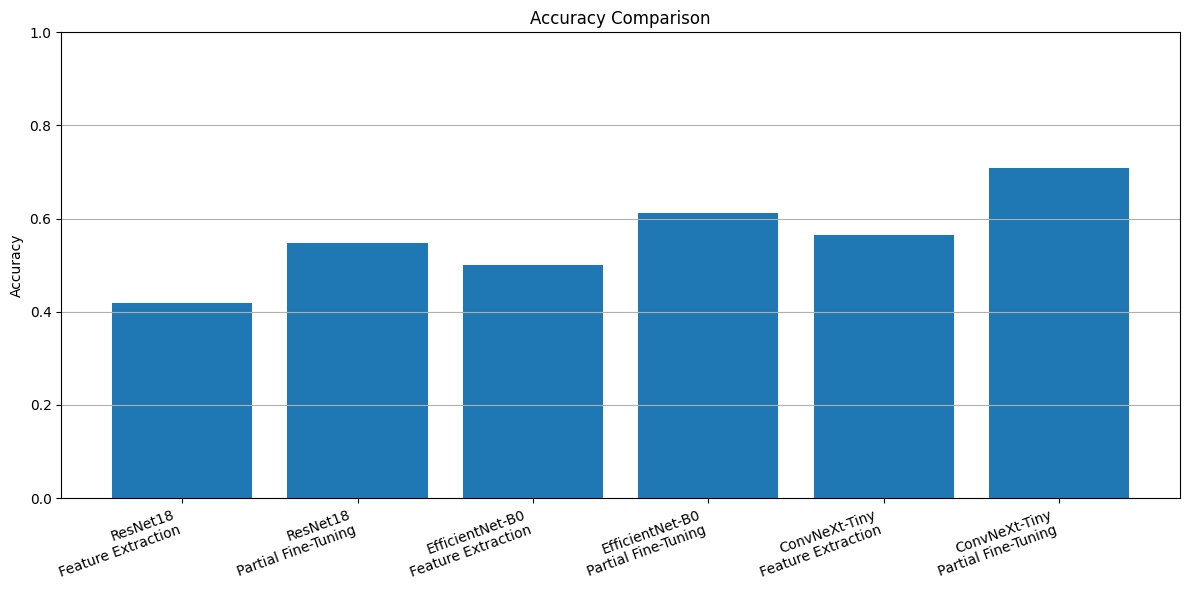

In [116]:
plt.figure(figsize=(12, 6))

plt.bar(
    comparison_results["Experiment"],
    comparison_results["Accuracy"]
)

plt.title("Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.grid(axis="y")

plt.tight_layout()
plt.show()

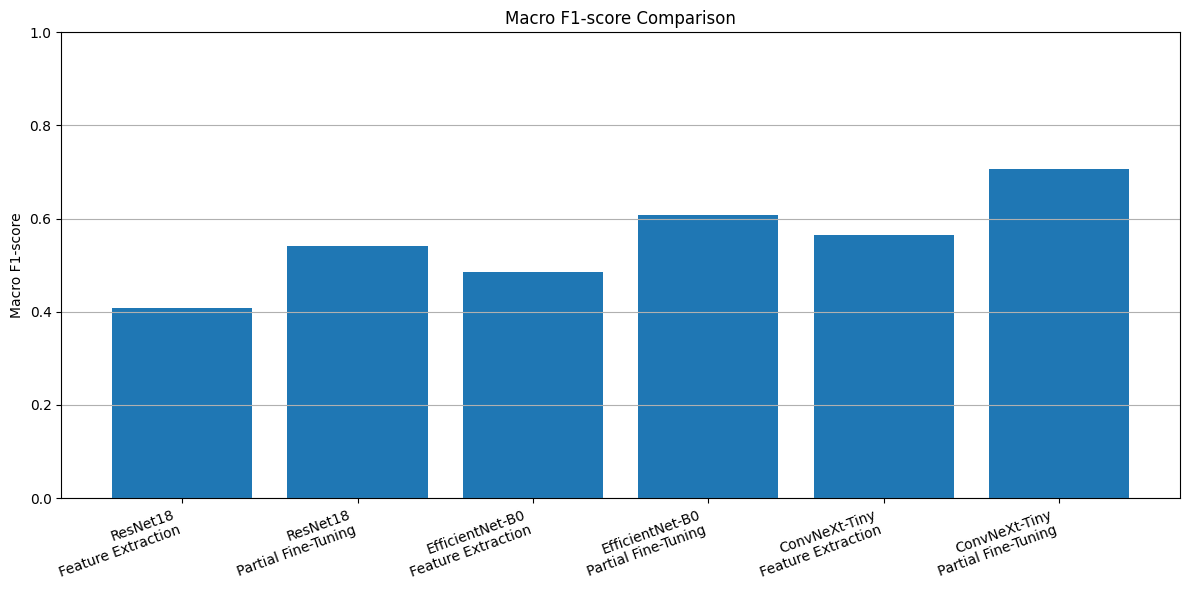

In [117]:
plt.figure(figsize=(12, 6))

plt.bar(
    comparison_results["Experiment"],
    comparison_results["Macro F1"]
)

plt.title("Macro F1-score Comparison")
plt.ylabel("Macro F1-score")
plt.ylim(0, 1)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.grid(axis="y")

plt.tight_layout()
plt.show()

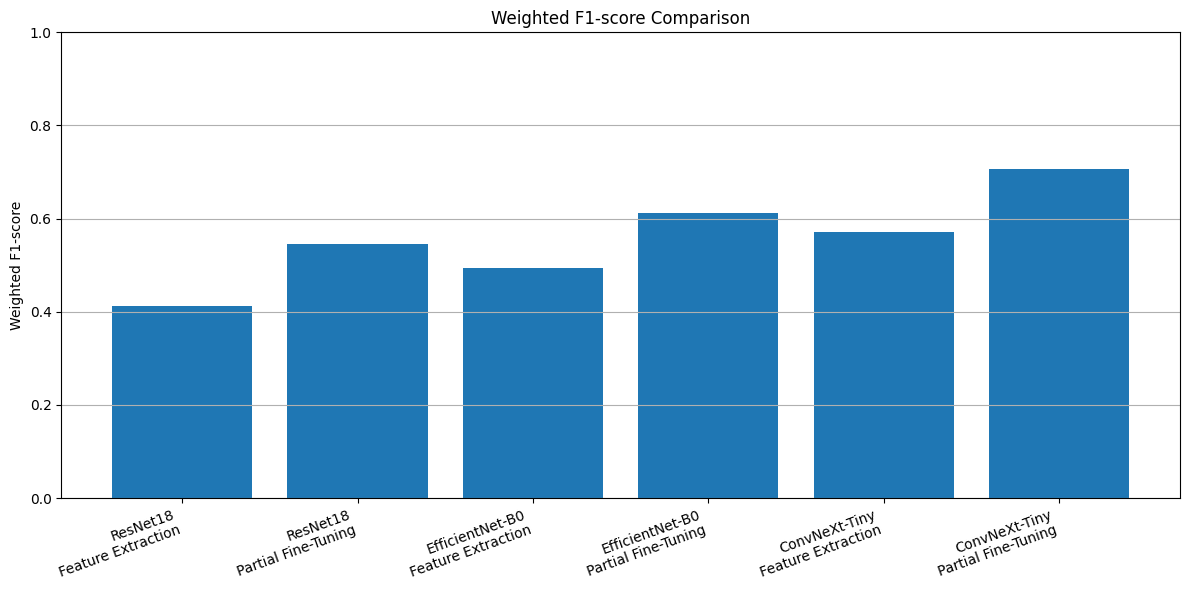

In [118]:
plt.figure(figsize=(12, 6))

plt.bar(
    comparison_results["Experiment"],
    comparison_results["Weighted F1"]
)

plt.title("Weighted F1-score Comparison")
plt.ylabel("Weighted F1-score")
plt.ylim(0, 1)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.grid(axis="y")

plt.tight_layout()
plt.show()

## Επιλογή του καλύτερου μοντέλου

Η σύγκριση των έξι πειραμάτων έδειξε ότι το μοντέλο **ConvNext-Tiny με
Partial Fine-Tuning** παρουσίασε τη συνολικά καλύτερη απόδοση.

Συγκεκριμένα, πέτυχε:

-Accuracy: **70.97%**

-Macro Precision: **73.06%**

-Macro Recall: **70.83%**

-Macro F1-score: **70.64%**

-Weighted F1-score: **70.56%**

Οι επιδόσεις αυτές ήταν υψηλότερες από εκείνες τόσο του αντίστοιχου
Feature Extraction όσο και των δύο πειραμάτων με ResNet18 και EfficientNet-B0.

Με βάση τα αποτελέσματα αυτά, το ConvNext-Tiny με
Partial Fine-Tuning επιλέγεται
ως το τελικό μοντέλο της παρούσας εργασίας.

In [1]:
# =============================================================================
# ΟΛΟΚΛΗΡΩΣΗ ΠΕΙΡΑΜΑΤΩΝ
# =============================================================================

print("=" * 80)
print("ΟΛΑ ΤΑ ΠΕΙΡΑΜΑΤΑ ΟΛΟΚΛΗΡΩΘΗΚΑΝ")
print("=" * 80)

print("\nΚαλύτερο μοντέλο:")

print("ConvNext-Tiny Partial Fine-Tuning")

print("\nAccuracy          : 0.7097")
print("Macro Precision  : 0.7306")
print("Macro Recall     : 0.7083")
print("Macro F1-score   : 0.7064")
print("Weighted F1-score: 0.7056")

print("\nΗ διαδικασία εκπαίδευσης και αξιολόγησης όλων των μοντέλων")
print("ολοκληρώθηκε επιτυχώς.")

print("=" * 80)

ΟΛΑ ΤΑ ΠΕΙΡΑΜΑΤΑ ΟΛΟΚΛΗΡΩΘΗΚΑΝ

Καλύτερο μοντέλο:
ConvNext-Tiny Partial Fine-Tuning

Accuracy          : 0.7097
Macro Precision  : 0.7306
Macro Recall     : 0.7083
Macro F1-score   : 0.7064
Weighted F1-score: 0.7056

Η διαδικασία εκπαίδευσης και αξιολόγησης όλων των μοντέλων
ολοκληρώθηκε επιτυχώς.
